<a href="https://colab.research.google.com/github/SergioCardozoCD/centinela-dengue/blob/main/notebooks/centinela_fase2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Abrir en Colab"/></a>

# Centinela del Dengue · Fase 2 · Sistema multimodal (CNN + LSTM/GRU + fusión)

**Profundización I: Redes Neuronales y Deep Learning (EA-N-F-004)** · Maestría en Ciencia de Datos · Universidad Santo Tomás · Docente: Javier Mauricio Sierra

**Equipo:** Sergio Alexander Cardozo Ovadia · Cesar Augusto Coy Velandia

**Qué hace este cuaderno.** Continúa la Fase 1 con el mismo problema y el mismo cliente: anticipar, con una semana de ventaja, si un municipio entra en brote de dengue (programas de Enfermedades Transmitidas por Vectores, ETV). La serie de casos y clima pasa a su arquitectura nativa (LSTM y GRU), entra la imagen satelital Sentinel-2 con una red convolucional preentrenada, y las dos ramas se fusionan en una sola alerta. Las dos fuentes se unen por la clave (código DIVIPOLA del municipio, semana epidemiológica).

**Las tres etiquetas de la semana siguiente** (todas salen del canal endémico de la Fase 1):

| Etiqueta | Qué es | La usa |
| --- | --- | --- |
| `y_brote` | Brote sí o no: incidencia sobre el cuartil 3 del canal y al menos 5 casos (la misma etiqueta de la Fase 1) | La fusión (rama C) |
| `y_zona` | Zona del canal: seguridad, alerta o brote. La etiqueta original es binaria y la rúbrica pide al menos 3 categorías para la imagen; las zonas del canal son las que ya usa la vigilancia en salud pública | La CNN (rama A) |
| `y_inc` | Incidencia por 100.000 habitantes | La LSTM y la GRU (rama B, regresión); la alerta se deriva comparándola con el umbral del canal |

**Política de datos.** Igual que en la Fase 1: los casos de SIVIGILA son datos de salud (Ley 1581 de 2012) y se reducen de inmediato a conteos por municipio y semana; no se publica ningún registro individual. Las imágenes de PhysioNet son de dominio público (CC0 1.0) y no muestran personas.

**Uso de IA.** El equipo usa Claude (Anthropic) como asistente de programación y redacción. Las decisiones y los fallos de la IA se registran en la bitácora (entradas E-14 en adelante); el identificador aparece en el comentario inicial de cada celda afectada. La sección 8 audita un fallo real de la IA.

### Mapa del cuaderno

| Sección | Contenido | Criterio de la rúbrica |
| --- | --- | --- |
| 0 | Entorno | — |
| 1 | La serie: casos, clima, población, canal endémico y etiquetas | 2 y 3 |
| 2 | Las imágenes: inventario, ubicación real, repetidas y nubes | 1 y 3 |
| 3 | Selección final, análisis exploratorio por clase y partición única | 1 y 3 |
| 4 | El MLP de la Fase 1 como vara de medida (incluye el compromiso de la Propuesta v1) | 2 y 3 |
| 5 | Rama B · RNN de contraste, LSTM y GRU | 2 |
| 6 | Rama A · CNN con aprendizaje por transferencia | 1 |
| 7 | Rama C · Fusión y ablación | 3 |
| 8 | Auditoría a la IA | 4 |
| 9 | Gráficas para el cliente (y panel interactivo, celda 42) | 5 |
| 10 | Anexo de procedencia (SHA-256) | 4 |
| 11 | Conclusiones, limitaciones y evidencia por criterio | 1 a 5 |

*Cada resultado va seguido de su **Lectura**: qué muestra la salida y qué se decide con ella. Las cifras de las lecturas son las de esta ejecución (Colab, GPU T4, 19 de noviembre de 2026).*

## 0. Entorno

In [3]:
# Celda 0 · Entorno, semilla y configuración
# Qué hace: instala las tres librerías que Colab no trae (lectura de los Excel del INS, de los
#   archivos .rds del DANE y de las imágenes GeoTIFF), fija la semilla 2026 (la misma de la Fase 1),
#   define los 10 municipios con las coordenadas de su casco urbano y la carpeta de trabajo.
# Dónde se guarda: en /content, que se borra al cerrar la sesión. Lo que valga la pena conservar
#   se descarga al computador con guardar_local(). El equipo decidió no usar Google Drive.
!pip -q install python-calamine pyreadr tifffile

import io, os, re, time, hashlib, datetime, warnings, random
import numpy as np
import pandas as pd
import requests
import torch
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
SEMILLA = 2026
random.seed(SEMILLA); np.random.seed(SEMILLA); torch.manual_seed(SEMILLA)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
FECHA_EJECUCION = datetime.date.today().isoformat()
ANIOS = list(range(2007, 2026))                      # 2007-2025, igual que en la Fase 1

CARPETA = "/content/centinela_fase2"
os.makedirs(CARPETA, exist_ok=True)

def guardar_local(ruta):
    """Descarga un archivo de la sesión al computador (para conservarlo o subirlo a OneDrive)."""
    from google.colab import files
    files.download(ruta)

# Los 10 municipios de la Fase 1 (código DIVIPOLA de 5 dígitos) y el centro aproximado de su
# casco urbano. Las coordenadas sirven para el clima (NASA POWER) y para comprobar qué municipio
# muestra de verdad cada imagen satelital (sección 2).
MUNICIPIOS = pd.DataFrame([
    ("05001", "Medellín",       6.2442, -75.5812),
    ("05360", "Itagüí",         6.1719, -75.6114),
    ("08001", "Barranquilla",  10.9685, -74.7813),
    ("23001", "Montería",       8.7479, -75.8814),
    ("41001", "Neiva",          2.9273, -75.2819),
    ("50001", "Villavicencio",  4.1420, -73.6266),
    ("54001", "Cúcuta",         7.8939, -72.5078),
    ("68001", "Bucaramanga",    7.1193, -73.1227),
    ("73001", "Ibagué",         4.4389, -75.2322),
    ("76001", "Cali",           3.4516, -76.5320),
], columns=["divipola", "municipio", "lat", "lon"])
NOMBRE = dict(zip(MUNICIPIOS["divipola"], MUNICIPIOS["municipio"]))

# Registro de procedencia (Anexo): cada archivo descargado con su huella SHA-256
procedencia = []
def registrar(archivo, url, contenido_bytes):
    procedencia.append({"archivo": archivo, "url": url, "fecha_descarga": FECHA_EJECUCION,
                        "sha256": hashlib.sha256(contenido_bytes).hexdigest()})

# Colores de las gráficas (los mismos de la Fase 1)
AZUL, NARANJA, GRIS, ROJO, VERDE = "#2E6DA4", "#E07B39", "#8A8A8A", "#C0392B", "#3A8F5C"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titlesize": 10, "axes.titleweight": "bold", "font.size": 9})

print("PyTorch", torch.__version__, "| dispositivo:", DEVICE, "| fecha:", FECHA_EJECUCION)
MUNICIPIOS


PyTorch 2.14.1+cu130 | dispositivo: cuda | fecha: 2026-11-20


,divipola,municipio,lat,lon
0,05001,Medellín,6.2442,-75.5812
1,05360,Itagüí,6.1719,-75.6114
2,08001,Barranquilla,10.9685,-74.7813
3,23001,Montería,8.7479,-75.8814
4,41001,Neiva,2.9273,-75.2819
5,50001,Villavicencio,4.1420,-73.6266
6,54001,Cúcuta,7.8939,-72.5078
7,68001,Bucaramanga,7.1193,-73.1227
8,73001,Ibagué,4.4389,-75.2322
9,76001,Cali,3.4516,-76.5320


## 1. La serie: casos, clima y población

Es la misma tubería de datos de la Fase 1 (celdas 1 a 8 de ese cuaderno), con un cambio: además de la etiqueta de brote, se calculan la mediana del canal (para las 3 zonas) y la incidencia de la semana siguiente (para la regresión). La serie cubre los 10 municipios de 2007 a 2025; la rama B no depende de las imágenes.

In [4]:
# Celda 1 · Calendario epidemiológico (domingo a sábado; la semana 1 contiene el 4 de enero)
# Qué hace: convierte cualquier fecha en su (año, semana) epidemiológica. Es el mismo calendario
#   de SIVIGILA, y es la mitad de la clave que une la imagen con la serie.
def inicio_anio_epi(anio):
    cuatro_enero = pd.Timestamp(anio, 1, 4)
    return cuatro_enero - pd.Timedelta(days=(cuatro_enero.weekday() + 1) % 7)

def semana_epi(fecha):
    fecha = pd.Timestamp(fecha)
    anio = fecha.year
    if fecha < inicio_anio_epi(anio):
        anio -= 1
    elif fecha >= inicio_anio_epi(anio + 1):
        anio += 1
    return anio, (fecha - inicio_anio_epi(anio)).days // 7 + 1

def semanas_del_anio(anio):
    return (inicio_anio_epi(anio + 1) - inicio_anio_epi(anio)).days // 7

assert inicio_anio_epi(2016) == pd.Timestamp("2016-01-03")
assert semana_epi("2016-01-03") == (2016, 1) and semana_epi("2018-12-23") == (2018, 52)
assert semanas_del_anio(2025) == 53 and semanas_del_anio(2024) == 52
print("Calendario verificado · años con 53 semanas:", [a for a in ANIOS if semanas_del_anio(a) == 53])


Calendario verificado · años con 53 semanas: [2008, 2014, 2020, 2025]


In [5]:
# Celda 2 · Casos de dengue: descarga de SIVIGILA (INS) y agregación municipio-semana · bitácora E-18
# Qué hace: lo mismo que la celda 2 de la Fase 1. Descarga los microdatos de los eventos 210 (dengue)
#   y 220 (dengue grave) de 2007 a 2025, quita los registros descartados (ajuste 6 y D), los cuenta
#   por municipio de procedencia y semana, y descarta los microdatos de inmediato.
# Por qué no el 580: es la mortalidad, un evento aparte (auditoría E-4 de la Fase 1).
# Tiempo: unos 10 a 15 minutos la primera vez. Los conteos (agregados, sin datos personales) quedan
#   en la carpeta de trabajo, así que en la misma sesión no se vuelve a descargar.
# La verificación cruzada con el script de R se hizo en la Fase 1 (celda 3): los totales coinciden.
BASE_SIV = "https://portalsivigila.ins.gov.co/_api/"
EVENTOS = {"dengue": 210, "dengue grave": 220}
COLUMNAS = ["cod_eve", "ano", "semana", "cod_dpto_o", "cod_mun_o", "ajuste"]
CACHE_SIV = f"{CARPETA}/sivigila_conteos.csv"
CACHE_PROC = f"{CARPETA}/sivigila_procedencia.csv"

def normalizar(col):
    return str(col).strip().lower().rstrip("_")      # el INS publica AJUSTE_, COD_EVE...

def archivos_del_anio(anio):
    consulta = (f"web/lists/GetByTitle('Microdatos')/items?$select=NombreEvento,A_x00f1_o,FileRef"
                f"&$filter=A_x00f1_o%20eq%20%27{anio}%27&$top=5000")
    r = requests.get(BASE_SIV + consulta, headers={"Accept": "application/json;odata=verbose"}, timeout=120)
    r.raise_for_status()
    return [(it["NombreEvento"], it["FileRef"]) for it in r.json()["d"]["results"]
            if it["NombreEvento"].strip().lower() in EVENTOS]

def leer_excel(contenido):
    try:
        return pd.read_excel(io.BytesIO(contenido), engine="calamine", dtype=str,
                             usecols=lambda c: normalizar(c) in COLUMNAS)
    except Exception:
        return pd.read_excel(io.BytesIO(contenido), engine="openpyxl", dtype=str,
                             usecols=lambda c: normalizar(c) in COLUMNAS)

if os.path.exists(CACHE_SIV):
    conteos = pd.read_csv(CACHE_SIV, dtype={"divipola": str})
    procedencia += pd.read_csv(CACHE_PROC).to_dict("records")
    print("Conteos leídos de la carpeta de trabajo.")
else:
    partes = []
    for anio in ANIOS:
        for evento, ruta in archivos_del_anio(anio):
            url = BASE_SIV + f"Web/GetFileByServerRelativeUrl('{ruta}')/$value?binaryStringResponseBody=true"
            contenido = requests.get(url, timeout=600).content
            registrar(ruta.split("/")[-1], url, contenido)
            df = leer_excel(contenido)
            df.columns = [normalizar(c) for c in df.columns]
            assert set(COLUMNAS) <= set(df.columns), f"Faltan columnas en {ruta}"
            df["ajuste"] = df["ajuste"].astype(str).str.strip().str.replace(r"\.0$", "", regex=True)
            df = df[~df["ajuste"].isin(["6", "D"])]
            df["divipola"] = (pd.to_numeric(df["cod_dpto_o"], errors="coerce").astype("Int64").astype(str).str.zfill(2)
                              + pd.to_numeric(df["cod_mun_o"], errors="coerce").astype("Int64").astype(str).str.zfill(3))
            df = df[df["divipola"].isin(MUNICIPIOS["divipola"])]
            df["anio"] = pd.to_numeric(df["ano"], errors="coerce").astype(int)
            df["semana"] = pd.to_numeric(df["semana"], errors="coerce").astype(int)
            partes.append(df.groupby(["divipola", "anio", "semana"]).size().rename("casos").reset_index())
            del df, contenido                                     # se descartan los microdatos
        print(f"{anio} listo")
    conteos = pd.concat(partes).groupby(["divipola", "anio", "semana"], as_index=False)["casos"].sum()
    conteos.to_csv(CACHE_SIV, index=False)
    pd.DataFrame(procedencia).to_csv(CACHE_PROC, index=False)

# Rejilla completa municipio × semana: las semanas sin casos valen 0
rejilla = pd.DataFrame([(d, a, s) for d in MUNICIPIOS["divipola"] for a in ANIOS
                        for s in range(1, semanas_del_anio(a) + 1)], columns=["divipola", "anio", "semana"])
serie = (rejilla.merge(conteos, on=["divipola", "anio", "semana"], how="left")
                .fillna({"casos": 0}).astype({"casos": int}))
print("Tabla municipio-semana:", serie.shape, "| casos en los 10 municipios:",
      f"{serie['casos'].sum():,}".replace(",", "."), "(Fase 1: 563.245)")


Conteos leídos de la carpeta de trabajo.
Tabla municipio-semana: (9920, 4) | casos en los 10 municipios: 563.245 (Fase 1: 563.245)


In [6]:
# Celda 3 · Clima diario de NASA POWER agregado a semana epidemiológica
# Qué hace: lo mismo que la celda 4 de la Fase 1: temperatura media, máxima y mínima, humedad
#   relativa y lluvia de cada municipio, día a día, agregadas a la semana epidemiológica.
PARAMS = "T2M,T2M_MAX,T2M_MIN,RH2M,PRECTOTCORR"
CACHE_CLIMA = f"{CARPETA}/clima_semanal.csv"
CACHE_CLIMA_PROC = f"{CARPETA}/clima_procedencia.csv"

if os.path.exists(CACHE_CLIMA) and os.path.exists(CACHE_CLIMA_PROC):
    clima = pd.read_csv(CACHE_CLIMA, dtype={"divipola": str})
    procedencia += pd.read_csv(CACHE_CLIMA_PROC).to_dict("records")
    print("Clima leído de la carpeta de trabajo.")
else:
    tablas = []
    for _, m in MUNICIPIOS.iterrows():
        url = ("https://power.larc.nasa.gov/api/temporal/daily/point"
               f"?parameters={PARAMS}&community=AG&longitude={m.lon}&latitude={m.lat}"
               f"&start=20061231&end=20260103&format=JSON")
        r = requests.get(url, timeout=300); r.raise_for_status()
        registrar(f"nasa_power_{m.divipola}.json", url, r.content)
        diario_m = pd.DataFrame(r.json()["properties"]["parameter"])
        diario_m.index = pd.to_datetime(diario_m.index, format="%Y%m%d")
        diario_m = diario_m.replace(-999, np.nan)
        diario_m["divipola"] = m.divipola
        tablas.append(diario_m)
        time.sleep(1)
    diario = pd.concat(tablas).rename_axis("fecha").reset_index()
    diario[["anio", "semana"]] = pd.DataFrame(diario["fecha"].map(semana_epi).tolist(), index=diario.index)
    clima = (diario.groupby(["divipola", "anio", "semana"])
             .agg(t2m=("T2M", "mean"), t2m_max=("T2M_MAX", "mean"), t2m_min=("T2M_MIN", "mean"),
                  rh2m=("RH2M", "mean"), lluvia=("PRECTOTCORR", "sum"), dias=("T2M", "size"))
             .reset_index())
    clima = clima[clima["anio"].isin(ANIOS)]
    clima.to_csv(CACHE_CLIMA, index=False)
    pd.DataFrame([p for p in procedencia if p["archivo"].startswith("nasa_power")]).to_csv(CACHE_CLIMA_PROC, index=False)
print("Clima semanal:", clima.shape, "| semanas con menos de 7 días:", int((clima["dias"] < 7).sum()))


Clima semanal: (9920, 9) | semanas con menos de 7 días: 0


In [7]:
# Celda 4 · Población municipal por año (proyecciones del DANE, vía el repositorio de sivirep)
# Qué hace: lo mismo que la celda 5 de la Fase 1. La población permite pasar de casos a
#   incidencia por 100.000 habitantes, la escala con la que se construye el canal endémico.
import pyreadr, tempfile
URL_POB = "https://raw.githubusercontent.com/TRACE-LAC/sivirep_incidence/main/data/proyecciones/proyecciones_{anio}.rds"
poblacion = []
for anio in ANIOS:
    url = URL_POB.format(anio=anio)
    contenido = requests.get(url, timeout=300).content
    registrar(f"proyecciones_{anio}.rds", url, contenido)
    with tempfile.NamedTemporaryFile(suffix=".rds") as tmp:
        tmp.write(contenido); tmp.flush()
        df = list(pyreadr.read_r(tmp.name).values())[0]
    df = df[(df["area_geografica"] == "Total") & (df["mpio"].isin(MUNICIPIOS["divipola"]))]
    poblacion.append(df.groupby("mpio")["total"].sum().rename("poblacion").reset_index()
                     .rename(columns={"mpio": "divipola"}).assign(anio=anio))
poblacion = pd.concat(poblacion)
print("Población:", poblacion.shape, "| años:", poblacion["anio"].min(), "a", poblacion["anio"].max())


Población: (190, 3) | años: 2007 a 2025


In [8]:
# Celda 5 · Tabla integrada, canal endémico y las tres etiquetas de la semana siguiente · bitácora E-17
# Qué hace: une casos, clima y población; calcula la incidencia por 100.000 habitantes y el canal
#   endémico (mediana y cuartil 3 de la misma semana en los 5 años anteriores). Con eso arma las
#   tres etiquetas que usa la Fase 2, todas para la semana t + 1 (lo que se predice):
#   · y_brote: brote sí o no (incidencia > Q3 y al menos 5 casos), la misma etiqueta de la Fase 1.
#     Es la salida de la fusión.
#   · y_zona: las 3 zonas del canal (0 seguridad: hasta la mediana; 1 alerta: sobre la mediana sin
#     llegar a brote; 2 brote). Es la salida de la CNN. La etiqueta original es binaria y la rúbrica
#     pide al menos 3 categorías para la imagen: las zonas del canal son las que ya usa la vigilancia.
#   · y_inc: la incidencia de la semana siguiente. Es la salida de la LSTM y la GRU (regresión).
datos = (serie.merge(clima.drop(columns="dias"), on=["divipola", "anio", "semana"], how="left")
              .merge(poblacion, on=["divipola", "anio"], how="left"))
datos["municipio"] = datos["divipola"].map(NOMBRE)
datos["incidencia"] = 100_000 * datos["casos"] / datos["poblacion"]
datos = datos.sort_values(["divipola", "anio", "semana"]).reset_index(drop=True)

VENTANA_ANIOS, MIN_CASOS = 5, 5
datos["semana_ref"] = datos["semana"].clip(upper=52)      # la semana 53 se compara con la 52
pivote = datos.pivot_table(index=["divipola", "semana_ref"], columns="anio", values="incidencia", aggfunc="mean")

def canal(fila):
    previos = [a for a in range(fila.anio - VENTANA_ANIOS, fila.anio) if a in pivote.columns]
    if len(previos) < VENTANA_ANIOS:
        return pd.Series([np.nan, np.nan])
    valores = pivote.loc[(fila.divipola, fila.semana_ref), previos].values
    return pd.Series([np.nanpercentile(valores, 50), np.nanpercentile(valores, 75)])

datos[["q2_canal", "q3_canal"]] = datos.apply(canal, axis=1)
hay_canal = datos["q3_canal"].notna()
brote = (datos["incidencia"] > datos["q3_canal"]) & (datos["casos"] >= MIN_CASOS)
datos["brote_t"] = brote.astype(float).where(hay_canal)
datos["zona_t"] = np.select([brote, datos["incidencia"] > datos["q2_canal"]], [2, 1], 0).astype(float)
datos["zona_t"] = datos["zona_t"].where(hay_canal)

g = datos.groupby("divipola")
datos["y_brote"] = g["brote_t"].shift(-1)
datos["y_zona"] = g["zona_t"].shift(-1)
datos["y_inc"] = g["incidencia"].shift(-1)
datos["q3_t1"] = g["q3_canal"].shift(-1)                   # umbral de t + 1: sale de años previos
datos["poblacion_t1"] = g["poblacion"].shift(-1)

etiquetado = datos.dropna(subset=["y_brote"])
print("Semanas con etiqueta:", len(etiquetado), "| desde", int(etiquetado["anio"].min()),
      "hasta", int(etiquetado["anio"].max()))
print(f"Brote en t + 1: {etiquetado['y_brote'].mean():.1%} de las semanas (en la Fase 1, con las variables completas: 35,6 %)")
print("Zonas en t + 1:", etiquetado["y_zona"].map({0: "seguridad", 1: "alerta", 2: "brote"})
      .value_counts(normalize=True).round(3).to_dict())
datos.to_csv(f"{CARPETA}/datos_serie.csv", index=False)   # solo agregados municipio-semana


Semanas con etiqueta: 7310 | desde 2011 hasta 2025
Brote en t + 1: 35.6% de las semanas (en la Fase 1, con las variables completas: 35,6 %)
Zonas en t + 1: {'seguridad': 0.463, 'brote': 0.356, 'alerta': 0.181}


**Lectura (celdas 1 a 5).** La serie es la misma de la Fase 1: 563.245 casos en los 10 municipios, clima completo (ninguna semana con menos de 7 días) y población de 2007 a 2025. Quedan 7.310 semanas con etiqueta; el 35,6 % es brote en la semana siguiente, igual que en la Fase 1. Por zonas: 46,3 % seguridad, 18,1 % alerta y 35,6 % brote.

## 2. Las imágenes satelitales: inventario y control de calidad

**Fuente:** Cajas et al. (2024), *A multi-modal satellite imagery dataset for public health analysis in Colombia*, PhysioNet, v1.0.0 (CC0 1.0), subconjunto `10_municipalities`: una escena Sentinel-2 por municipio y semana epidemiológica, de 2016 a 2018 (156 semanas), con 12 bandas a 10 m.

**Qué se revisa antes de usar una imagen** (la exploración que llevó a estas reglas está en la bitácora, entradas E-14 en adelante):

1. **Vacías:** escenas negras de unos 9 KB, sin información.
2. **Ubicación real:** cada escena trae su georreferencia interna. Se verificó que no siempre coincide con la carpeta del municipio en que viene guardada.
3. **Repetidas:** la misma escena guardada en varias semanas o en varias carpetas no es una observación nueva.
4. **Nubes:** escenas cubiertas que no muestran el territorio.

In [9]:
# Celda 6 · Inventario de las imágenes de PhysioNet sin descargarlas
# Qué hace: lista las escenas del subconjunto 10_municipalities en el espejo público del dataset en
#   AWS (sin credenciales) y trae de cada una su ruta, su tamaño y su ETag. Marca como vacías las que
#   pesan menos de 20 KB: son escenas negras de unos 9 KB, sin información.
# Por qué esta versión: se inventariaron también las de 81 municipios (v1.0 y v2.0). Para nuestros
#   municipios traen las mismas escenas y el mismo problema de ubicación de la celda 8; la v2.0 solo
#   rellena las semanas negras repitiendo escenas. La original es la más completa y la más simple.
import xml.etree.ElementTree as ET

BUCKET = "https://physionet-open.s3.amazonaws.com"
BASE_IMG = "multimodal-satellite-data/1.0.0/"

def consulta_s3(params):
    r = requests.get(BUCKET, params=params, timeout=60); r.raise_for_status()
    raiz = ET.fromstring(r.content)
    return raiz, {"s": raiz.tag.split("}")[0].strip("{")}

def listar(prefijo):
    """Todos los archivos bajo una ruta (S3 entrega de a 1.000, por eso se pagina)."""
    filas, token = [], None
    while True:
        params = {"list-type": "2", "prefix": BASE_IMG + prefijo}
        if token:
            params["continuation-token"] = token
        raiz, ns = consulta_s3(params)
        for c in raiz.findall("s:Contents", ns):
            filas.append({"clave": c.find("s:Key", ns).text, "bytes": int(c.find("s:Size", ns).text),
                          "etag": c.find("s:ETag", ns).text.strip('"')})
        if raiz.find("s:IsTruncated", ns).text != "true":
            return pd.DataFrame(filas)
        token = raiz.find("s:NextContinuationToken", ns).text

escenas = listar("10_municipalities/images/")
m = escenas["clave"].str.extract(r"/(\d{4,5})/image_(\d{4}-\d{2}-\d{2})\.tiff?$")
escenas["divipola_carpeta"] = m[0].str.zfill(5)
escenas["fecha"] = pd.to_datetime(m[1])
escenas = escenas.dropna(subset=["fecha"]).sort_values(["divipola_carpeta", "fecha"]).reset_index(drop=True)
escenas[["anio", "semana"]] = pd.DataFrame(escenas["fecha"].map(semana_epi).tolist(), index=escenas.index)
escenas["vacia"] = escenas["bytes"] < 20_000

print(f"Escenas: {len(escenas):,} · vacías: {escenas['vacia'].sum()} · con contenido: {(~escenas['vacia']).sum()}".replace(",", "."))
print(escenas.assign(municipio_carpeta=escenas["divipola_carpeta"].map(NOMBRE))
      .groupby("municipio_carpeta").agg(escenas=("clave", "size"), vacias=("vacia", "sum"),
                                        desde=("fecha", "min"), hasta=("fecha", "max")).to_string())


Escenas: 1.560 · vacías: 290 · con contenido: 1270
                   escenas  vacias      desde      hasta
municipio_carpeta                                       
Barranquilla           156      67 2016-01-03 2018-12-23
Bucaramanga            156      51 2016-01-03 2018-12-23
Cali                   156       0 2016-01-03 2018-12-23
Cúcuta                 156       0 2016-01-03 2018-12-23
Ibagué                 156       0 2016-01-03 2018-12-23
Itagüí                 156      44 2016-01-03 2018-12-23
Medellín               156       0 2016-01-03 2018-12-23
Montería               156      65 2016-01-03 2018-12-23
Neiva                  156      63 2016-01-03 2018-12-23
Villavicencio          156       0 2016-01-03 2018-12-23


In [10]:
# Celda 7 · Descarga de las escenas con contenido: ubicación real, reducción y medida de nubes · bitácora E-15
# Qué hace, para cada escena con contenido (unos 1.270 archivos, unos 3 GB; tarda 2 o 3 minutos):
#   1. Lee su georreferencia interna (punto de anclaje y tamaño del píxel del GeoTIFF) y decide qué
#      municipio muestra de verdad: aquel cuyo casco urbano cae dentro de la huella de la escena.
#   2. Conserva 4 bandas (B02, B03, B04 y B08: azul, verde, rojo e infrarrojo cercano) y las reduce a
#      224 × 224 píxeles, el tamaño de entrada de las redes preentrenadas. La escena entra completa.
#   3. Mide las nubes: fracción de píxeles con el azul (B02) en 100 o más. Las nubes blancas son muy
#      brillantes en el azul; el suelo, la vegetación y lo urbano casi nunca llegan a ese valor.
#   4. Registra la huella SHA-256 del archivo original (procedencia).
# Orden de las 12 bandas: B01 a B12 sin la B8A (ficha de PhysioNet). Se verificó viendo la imagen:
#   con B04, B03 y B02 las ciudades se ven en color natural y la B10 (cirro) vale casi 0.
# Si la sesión se corta: cada escena procesada se guarda apenas termina; al repetir la celda solo
#   descarga las que faltan.
import tifffile
from concurrent.futures import ThreadPoolExecutor
from PIL import Image

BANDAS = ["B01", "B02", "B03", "B04", "B05", "B06", "B07", "B08", "B09", "B10", "B11", "B12"]
B = {nombre: i for i, nombre in enumerate(BANDAS)}
BANDAS_CNN = ["B02", "B03", "B04", "B08"]
LADO = 224
PROCESADAS = f"{CARPETA}/escenas_224"
os.makedirs(PROCESADAS, exist_ok=True)

def municipio_real(x0, y0, sx, sy, ancho, alto):
    """Municipio cuyo casco urbano cae dentro de la huella de la escena (o 'ninguno')."""
    dentro = MUNICIPIOS[(MUNICIPIOS["lon"] >= x0) & (MUNICIPIOS["lon"] <= x0 + ancho * sx) &
                        (MUNICIPIOS["lat"] <= y0) & (MUNICIPIOS["lat"] >= y0 - alto * sy)]
    return dentro["divipola"].iloc[0] if len(dentro) == 1 else ("varios" if len(dentro) > 1 else "ninguno")

def procesar(fila):
    destino = f"{PROCESADAS}/{fila.Index:04d}.npz"
    if os.path.exists(destino):
        return
    for intento in range(3):
        try:
            r = requests.get(f"{BUCKET}/{fila.clave}", timeout=300); r.raise_for_status(); break
        except Exception:
            if intento == 2:
                raise
    with tifffile.TiffFile(io.BytesIO(r.content)) as t:
        etiquetas = {tag.name: tag.value for tag in t.pages[0].tags.values()}
        arr = t.asarray()                                   # (alto, ancho, 12)
    x0, y0 = [float(v) for v in etiquetas["ModelTiepointTag"][3:5]]
    sx, sy = [float(v) for v in etiquetas["ModelPixelScaleTag"][:2]]
    alto, ancho = arr.shape[:2]
    canales = [np.asarray(Image.fromarray(arr[:, :, B[b]]).resize((LADO, LADO), Image.BOX)) for b in BANDAS_CNN]
    np.savez_compressed(destino, x=np.stack(canales).astype("uint8"),
                        meta=np.array([x0, y0, sx, sy, ancho, alto, (arr[:, :, B["B02"]] >= 100).mean()]),
                        sha256=hashlib.sha256(r.content).hexdigest())

con_contenido = escenas[~escenas["vacia"]]
t0 = time.time()
with ThreadPoolExecutor(max_workers=8) as pool:
    for i, _ in enumerate(pool.map(procesar, con_contenido.itertuples()), 1):
        if i % 200 == 0 or i == len(con_contenido):
            print(f"{i}/{len(con_contenido)} escenas · {time.time() - t0:.0f} s")

X_todas = np.zeros((len(con_contenido), len(BANDAS_CNN), LADO, LADO), dtype="uint8")
filas = []
for k, idx in enumerate(con_contenido.index):
    d = np.load(f"{PROCESADAS}/{idx:04d}.npz")
    X_todas[k] = d["x"]
    x0, y0, sx, sy, ancho, alto, nubes = d["meta"]
    filas.append({"ancla_lon": x0, "ancla_lat": y0, "nubes": nubes, "sha256": str(d["sha256"]),
                  "divipola_real": municipio_real(x0, y0, sx, sy, ancho, alto)})
con_contenido = pd.concat([con_contenido.reset_index(drop=True), pd.DataFrame(filas)], axis=1)
print("Listo:", X_todas.shape, f"· {X_todas.nbytes / 1e6:.0f} MB en memoria")


200/1270 escenas · 63 s
400/1270 escenas · 125 s
600/1270 escenas · 185 s
800/1270 escenas · 245 s
1000/1270 escenas · 307 s
1200/1270 escenas · 367 s
1270/1270 escenas · 389 s
Listo: (1270, 4, 224, 224) · 255 MB en memoria


In [11]:
# Celda 8 · Control de calidad: escenas en la carpeta equivocada y escenas repetidas · bitácora E-14, E-15
# Qué hace:
#   1. Compara la carpeta de cada escena (el municipio que dice el dataset) con el municipio que la
#      escena muestra de verdad según su georreferencia.
#   2. Quita las repetidas: dentro de cada municipio real, una escena casi idéntica a otra ya
#      guardada (diferencia media < 1 en una escala de 0 a 255) no es una observación nueva. Se
#      conserva la de la semana más temprana. Así salen las copias de relleno (la escena de la semana
#      anterior repetida) y la misma escena guardada en varias carpetas.
# Hallazgo que motiva esta celda: en el dataset, las carpetas de Itagüí, Barranquilla, Montería y
#   Neiva contienen escenas de otros municipios (sobre todo de Bucaramanga, Itagüí y Neiva), la misma
#   escena repetida en varias carpetas en la misma semana. Unir la etiqueta de un municipio con la
#   foto de otro sería un pareo artificial entre modalidades (fuga de datos).
print("Carpeta del dataset (filas) frente al municipio que muestra la escena (columnas):")
tabla = pd.crosstab(con_contenido["divipola_carpeta"].map(NOMBRE),
                    con_contenido["divipola_real"].map(lambda c: NOMBRE.get(c, c)))
print(tabla.to_string())

# Firma reducida de cada escena: promedio de las bandas visibles en una rejilla de 28 × 28
firma = X_todas[:, :3].astype("float32").mean(axis=1)
firma = firma.reshape(len(firma), 28, 8, 28, 8).mean(axis=(2, 4)).reshape(len(firma), -1)
con_contenido["repetida"] = True
for cod, grupo in con_contenido[con_contenido["divipola_real"].isin(NOMBRE)].groupby("divipola_real"):
    guardadas = []
    for i in grupo.sort_values("fecha").index:
        if all(np.abs(firma[i] - firma[j]).mean() >= 1 for j in guardadas):
            guardadas.append(i)
    con_contenido.loc[guardadas, "repetida"] = False

validas = con_contenido[con_contenido["divipola_real"].isin(NOMBRE) & ~con_contenido["repetida"]]
# Si quedaran dos escenas distintas del mismo municipio en la misma semana, se deja la de menos nubes
validas = validas.sort_values("nubes").drop_duplicates(["divipola_real", "anio", "semana"]).sort_index()
print(f"\nEscenas con contenido: {len(con_contenido)} · repetidas: {con_contenido['repetida'].sum()} · "
      f"sin municipio propio: {(~con_contenido['divipola_real'].isin(NOMBRE)).sum()} · válidas: {len(validas)}")
conteo = validas.pivot_table(index=validas["divipola_real"].map(NOMBRE), columns="anio", values="clave",
                             aggfunc="size", fill_value=0)
conteo["total"] = conteo.sum(axis=1)
print("\nEscenas válidas por municipio real y año:")
print(conteo.reindex(MUNICIPIOS["municipio"]).fillna(0).astype(int).to_string())


Carpeta del dataset (filas) frente al municipio que muestra la escena (columnas):
divipola_real     Barranquilla  Bucaramanga  Cali  Cúcuta  Ibagué  Itagüí  Medellín  Montería  Neiva  Villavicencio
divipola_carpeta                                                                                                   
Barranquilla                25           18     0       0       0      30         0         7      9              0
Bucaramanga                 12           63     0       0       0      14         0         7      9              0
Cali                         0            0   156       0       0       0         0         0      0              0
Cúcuta                       0            0     0     156       0       0         0         0      0              0
Ibagué                       0            0     0       0     156       0         0         0      0              0
Itagüí                      12           32     0       0       0      52         0         7      9      

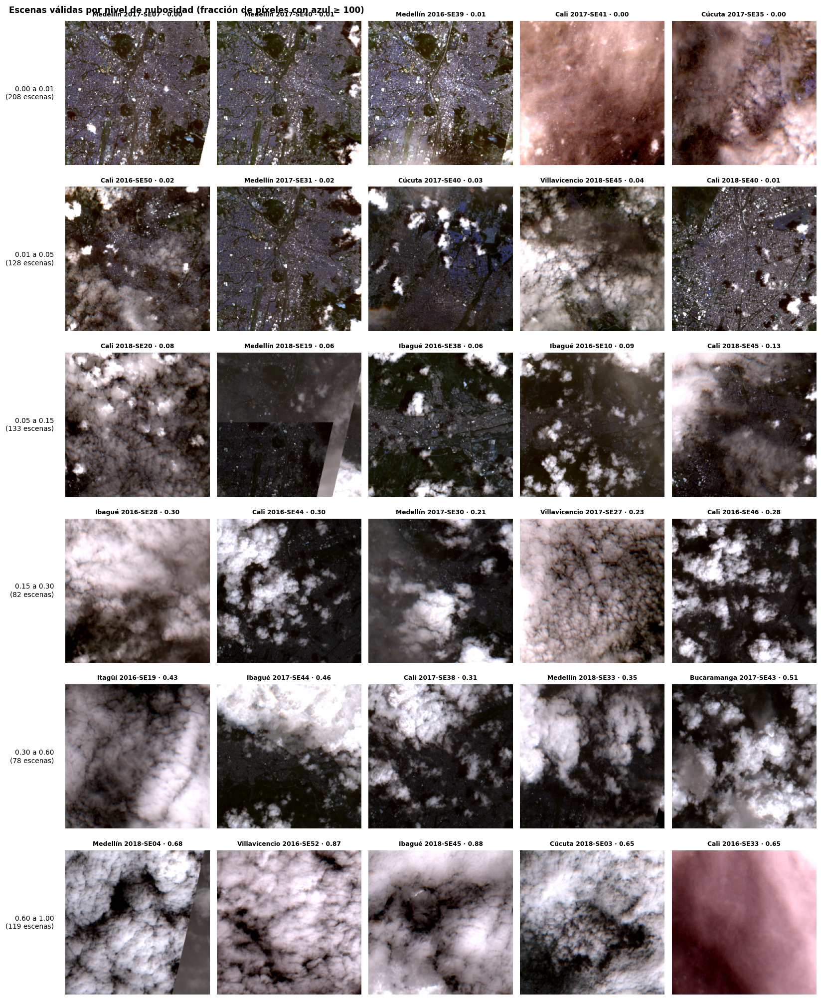

Escenas que quedan si se descartan las que superan cada umbral:
 umbral  quedan  2016  2017  2018 municipio_con_menos
   0.05     336    84   121   131        Montería (6)
   0.10     415   103   152   160        Montería (6)
   0.15     469   119   162   188        Montería (9)
   0.20     496   124   170   202        Montería (9)
   0.30     551   143   187   221       Montería (11)
   0.50     608   160   207   241       Montería (13)


In [12]:
# Celda 9 · Nubes: ejemplos por nivel y umbral de descarte · bitácora E-16
# Qué hace: dibuja 5 escenas válidas en cada nivel de nubosidad y cuenta cuántas quedarían con cada
#   umbral (en total, por año y en el municipio con menos). Con eso se fija UMBRAL_NUBES.
# Limitación declarada: la medida detecta bien las nubes blancas, pero no las grises ni las franjas
#   sin datos del borde de la pasada del satélite. Ese ruido queda en el conjunto final.
def color_verdadero(x):
    """x: (4, 224, 224) con B02, B03, B04, B08 → imagen RGB con contraste estirado, solo para verla."""
    rgb = x[[2, 1, 0]].transpose(1, 2, 0).astype("float32")
    lo, hi = np.percentile(rgb, [2, 98])
    return np.clip((rgb - lo) / (hi - lo + 1e-6), 0, 1)

NIVELES = [0, 0.01, 0.05, 0.15, 0.30, 0.60, 1.0001]
niveles = pd.cut(validas["nubes"], NIVELES, right=False)
fig, axes = plt.subplots(len(NIVELES) - 1, 5, figsize=(15, 3.1 * (len(NIVELES) - 1)))
for fila_ax, (nivel, grupo) in zip(axes, validas.groupby(niveles, observed=False)):
    for ax in fila_ax:
        ax.axis("off")
    for ax, (i, f) in zip(fila_ax, grupo.sample(min(5, len(grupo)), random_state=SEMILLA).iterrows()):
        ax.imshow(color_verdadero(X_todas[i]))
        ax.set_title(f"{NOMBRE[f['divipola_real']]} {f['anio']}-SE{f['semana']:02d} · {f['nubes']:.2f}", fontsize=8)
    fila_ax[0].text(-0.08, 0.5, f"{nivel.left:.2f} a {min(nivel.right, 1):.2f}\n({len(grupo)} escenas)",
                    transform=fila_ax[0].transAxes, ha="right", va="center", fontsize=9)
fig.suptitle("Escenas válidas por nivel de nubosidad (fracción de píxeles con azul ≥ 100)",
             x=0.01, ha="left", fontsize=11, fontweight="bold")
plt.tight_layout(); plt.show()

filas_u = []
for u in [0.05, 0.10, 0.15, 0.20, 0.30, 0.50]:
    q = validas[validas["nubes"] <= u]
    por_mun = q["divipola_real"].map(NOMBRE).value_counts()
    filas_u.append({"umbral": u, "quedan": len(q),
                    **{str(a): int((q["anio"] == a).sum()) for a in (2016, 2017, 2018)},
                    "municipio_con_menos": f"{por_mun.idxmin()} ({por_mun.min()})" if len(por_mun) else "—"})
print("Escenas que quedan si se descartan las que superan cada umbral:")
print(pd.DataFrame(filas_u).to_string(index=False))


**Lectura (celdas 6 a 9).** (1) De 1.560 escenas, 290 están vacías (negras). (2) **La georreferencia muestra que las carpetas de Barranquilla, Bucaramanga, Itagüí, Montería y Neiva mezclan escenas de esos cinco municipios.** Por ejemplo, la carpeta de Barranquilla tiene 25 escenas de Barranquilla, 30 de Itagüí y 18 de Bucaramanga. Las de Cali, Cúcuta, Ibagué, Medellín y Villavicencio están bien. Cada escena se reasigna al municipio que muestra. (3) Al quitar las repetidas (522, entre copias de relleno y el mismo archivo en varias carpetas) quedan 748 escenas válidas, muy desiguales: de 142 (Medellín) a 16 (Montería). (4) Con el umbral de nubes de 0,30 quedan 551 escenas: es el más estricto que cumple el mínimo de 500 de la actividad (con 0,20 serían 496). Montería queda con 11. **Limitación:** la medida no detecta nubes grises, bruma ni franjas sin datos.

## 3. Selección final, análisis por clase y partición

Después de las reglas de la sección 2 quedan las imágenes que muestran de verdad el municipio y la semana de su etiqueta. Aquí se fija el umbral de nubes, se une cada imagen con su semana en la serie, se mira qué distingue a las tres zonas y se define una sola partición para la CNN, la fusión y la comparación con el MLP.

In [13]:
# Celda 10 · Selección final de imágenes y sus etiquetas · bitácora E-16
# Qué hace: aplica el umbral de nubes elegido en la celda 9, une cada escena con su semana en la
#   serie por la clave (código DIVIPOLA del municipio real, año y semana epidemiológica) y le asigna
#   las etiquetas de la semana siguiente. Guarda el conjunto final para las ramas A y C.
# UMBRAL_NUBES: se fija viendo la celda 9. Criterio: el más estricto que deje al menos 500
#   imágenes (mínimo de la rúbrica) y un número razonable en cada municipio.
UMBRAL_NUBES = 0.30

sel = validas[validas["nubes"] <= UMBRAL_NUBES].copy()
sel["divipola"] = sel["divipola_real"]
sel = sel.merge(datos[["divipola", "anio", "semana", "municipio", "y_zona", "y_brote", "y_inc"]],
                on=["divipola", "anio", "semana"], how="left", validate="one_to_one")
idx_sel = validas.index[validas["nubes"] <= UMBRAL_NUBES]      # posición de cada escena en X_todas
sel["indice_escena"] = idx_sel
assert sel["y_zona"].notna().all(), "Alguna imagen no encontró su semana en la serie"
X_img = X_todas[idx_sel]

ZONAS = {0: "seguridad", 1: "alerta", 2: "brote"}
print(f"Umbral de nubes: {UMBRAL_NUBES} · imágenes seleccionadas: {len(sel)} "
      f"({'cumple' if len(sel) >= 500 else 'NO cumple'} el mínimo de 500) · municipios: {sel['divipola'].nunique()}")
print("\nZona de la semana siguiente, por municipio:")
print(pd.crosstab(sel["municipio"], sel["y_zona"].map(ZONAS), margins=True, margins_name="Total").to_string())
print("\nZona de la semana siguiente, por año:")
print(pd.crosstab(sel["anio"], sel["y_zona"].map(ZONAS), normalize="index").round(2).to_string())

np.savez_compressed(f"{CARPETA}/imagenes_224.npz", X=X_img)
sel.to_csv(f"{CARPETA}/imagenes_224.csv", index=False)
print(f"\nGuardado: {CARPETA}/imagenes_224.npz y imagenes_224.csv")


Umbral de nubes: 0.3 · imágenes seleccionadas: 551 (cumple el mínimo de 500) · municipios: 10

Zona de la semana siguiente, por municipio:
y_zona         alerta  brote  seguridad  Total
municipio                                     
Barranquilla        5      3         12     20
Bucaramanga         1      0         37     38
Cali                6      6         55     67
Cúcuta              9      7         43     59
Ibagué              3      2         69     74
Itagüí              2      9         28     39
Medellín            9     39         73    121
Montería            1      3          7     11
Neiva               2      0         19     21
Villavicencio      22      4         75    101
Total              60     73        418    551

Zona de la semana siguiente, por año:
y_zona  alerta  brote  seguridad
anio                            
2016      0.10   0.35       0.55
2017      0.05   0.03       0.91
2018      0.16   0.08       0.76

Guardado: /content/centinela_fase2/imagenes_2

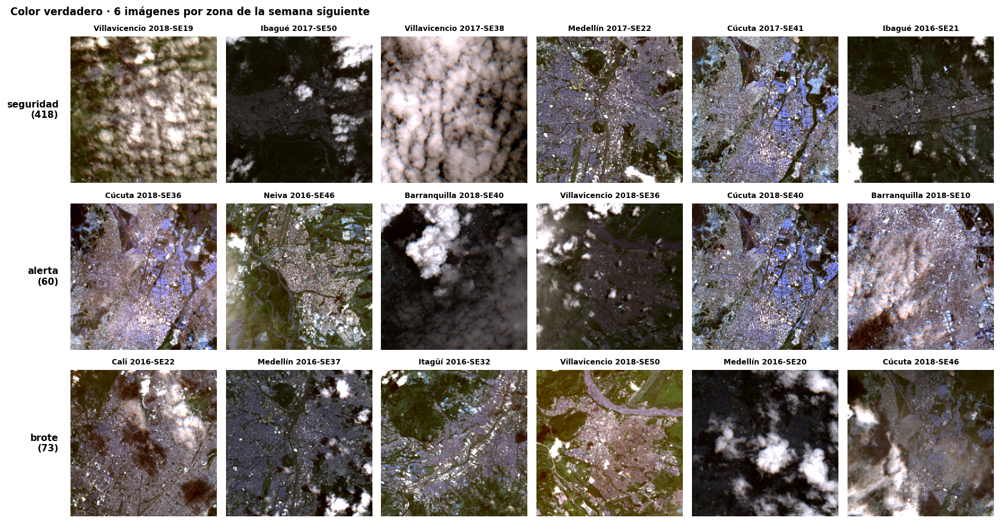

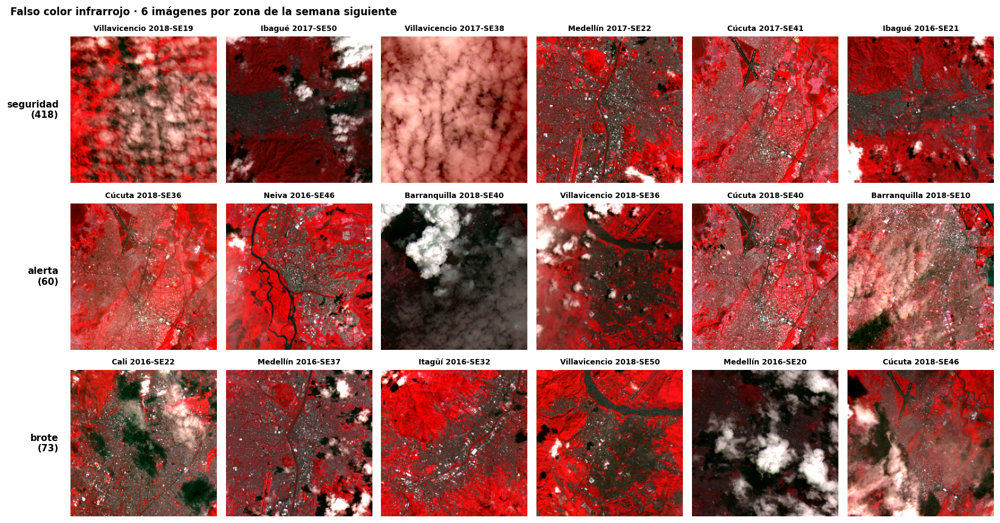

           brillo  nubes
y_zona                  
alerta     50.918  0.076
brote      44.305  0.055
seguridad  45.803  0.062


In [14]:
# Celda 11 · Análisis exploratorio de las imágenes por clase
# Qué hace: muestra 6 imágenes de cada zona en color verdadero y en falso color infrarrojo (B08, B04,
#   B03: la vegetación sale roja, lo urbano gris o azulado y el agua oscura), y el brillo y la
#   nubosidad medios por clase.
# Pregunta que responde: ¿se ve algo en la imagen que distinga una zona de otra, o lo que cambia es
#   sobre todo el municipio y las nubes? Si es lo segundo, la CNN tenderá a aprender «qué ciudad es».
def falso_color(x):
    rgb = x[[3, 2, 1]].transpose(1, 2, 0).astype("float32")
    lo, hi = np.percentile(rgb, [2, 98])
    return np.clip((rgb - lo) / (hi - lo + 1e-6), 0, 1)

for titulo, funcion in [("Color verdadero", color_verdadero), ("Falso color infrarrojo", falso_color)]:
    fig, axes = plt.subplots(3, 6, figsize=(15, 8))
    for fila_ax, (zona, nombre) in zip(axes, ZONAS.items()):
        grupo = sel[sel["y_zona"] == zona]
        for ax in fila_ax:
            ax.axis("off")
        for ax, (k, f) in zip(fila_ax, grupo.sample(min(6, len(grupo)), random_state=SEMILLA).iterrows()):
            ax.imshow(funcion(X_img[k])); ax.set_title(f"{f['municipio']} {f['anio']}-SE{f['semana']:02d}", fontsize=8)
        fila_ax[0].text(-0.08, 0.5, f"{nombre}\n({len(grupo)})", transform=fila_ax[0].transAxes,
                        ha="right", va="center", fontsize=10, fontweight="bold")
    fig.suptitle(f"{titulo} · 6 imágenes por zona de la semana siguiente", x=0.01, ha="left",
                 fontsize=11, fontweight="bold")
    plt.tight_layout(); plt.show()

resumen = sel.assign(brillo=X_img[:, :3].reshape(len(sel), -1).mean(axis=1)).groupby(sel["y_zona"].map(ZONAS))
print(resumen[["brillo", "nubes"]].mean().round(3).to_string())


In [15]:
# Celda 12 · Partición única para la CNN, la fusión y la comparación con el MLP · bitácora E-17
# Qué hace: reparte las imágenes en entrenamiento, validación y prueba (cerca de 70/15/15) por
#   bloques de 4 semanas seguidas: todas las imágenes de un bloque (de todos los municipios) van al
#   mismo conjunto. La CNN (rama A), la fusión (rama C) y el MLP de la Fase 1 usan esta misma partición.
# Por qué por bloques y no al azar: semanas vecinas de un mismo municipio se parecen mucho (misma
#   ciudad, nubes y etiqueta parecidas); repartidas al azar, el modelo vería en entrenamiento la
#   gemela casi exacta de cada imagen de prueba. Por qué no un corte por fechas: 2016 fue epidémico y
#   2017 casi no tuvo brotes; un corte por años dejaría la validación o la prueba casi sin alguna clase.
# Cómo se elige: se prueban asignaciones de bloques al azar (semilla fija) y se toma la primera que
#   quede a no más de 4 puntos de 70/15/15 y con las 3 clases representadas (al menos 8 % cada una)
#   en validación y en prueba; si ninguna lo logra, se baja ese mínimo al 5 % y se avisa. La semilla
#   elegida queda impresa, así la partición se puede repetir.
sel["bloque"] = ((sel["fecha"] - pd.Timestamp("2016-01-03")).dt.days // 28).astype(int)
bloques = np.sort(sel["bloque"].unique())

def evaluar(asignacion, minimo):
    conj = sel["bloque"].map(asignacion)
    prop = conj.value_counts(normalize=True)
    if any(abs(prop.get(c, 0) - p) > 0.04 for c, p in [("train", 0.70), ("val", 0.15), ("test", 0.15)]):
        return None
    for c in ("val", "test"):
        clases = sel.loc[conj == c, "y_zona"].value_counts(normalize=True)
        if len(clases) < 3 or clases.min() < minimo:
            return None
    return conj

conj = None
for minimo in (0.08, 0.05):
    for semilla_part in range(SEMILLA, SEMILLA + 5000):
        orden = np.random.default_rng(semilla_part).permutation(bloques)
        n_val = n_test = round(0.15 * len(bloques))
        asignacion = {b: "test" for b in orden[:n_test]}
        asignacion.update({b: "val" for b in orden[n_test:n_test + n_val]})
        asignacion.update({b: "train" for b in orden[n_test + n_val:]})
        conj = evaluar(asignacion, minimo)
        if conj is not None:
            break
    if conj is not None:
        break
    print("Aviso: ninguna asignación dejó el 8 % de cada clase; se prueba con el 5 %.")
assert conj is not None, "Ninguna asignación cumplió las condiciones: revisar el balance de clases"
sel["conjunto"] = conj
print(f"Partición elegida con la semilla {semilla_part} (mínimo por clase: {minimo:.0%}) · "
      f"{len(bloques)} bloques de 4 semanas")
print(pd.crosstab(sel["conjunto"], sel["y_zona"].map(ZONAS), margins=True, margins_name="Total")
      .reindex(["train", "val", "test", "Total"]).to_string())
print("\nProporción por conjunto:", sel["conjunto"].value_counts(normalize=True).round(3).to_dict())
sel.to_csv(f"{CARPETA}/imagenes_224.csv", index=False)


Partición elegida con la semilla 2026 (mínimo por clase: 8%) · 39 bloques de 4 semanas
y_zona    alerta  brote  seguridad  Total
conjunto                                 
train         38     55        290    383
val           12      7         64     83
test          10     11         64     85
Total         60     73        418    551

Proporción por conjunto: {'train': 0.695, 'test': 0.154, 'val': 0.151}


**Lectura (celdas 10 a 12).** (1) Las 551 imágenes tienen un desbalance fuerte: 418 de seguridad (76 %), 73 de brote y 60 de alerta. (2) Medellín concentra 39 de los 73 brotes, y Bucaramanga y Neiva no tienen ninguno: una CNN podría acertar solo con reconocer la ciudad. La celda 28 lo controla con la línea base «Solo municipio». (3) En 2017 casi no hubo brotes (3 %), así que un corte por años dejaría la validación o la prueba sin alguna clase. Por eso se usa la partición por bloques: 383 / 83 / 85, con las tres clases en validación y en prueba. (4) A simple vista, las tres zonas no se distinguen (celda 11): las mismas ciudades aparecen en todas, y las diferencias de brillo (44 a 51) y de nubes (0,055 a 0,076) entre clases son pequeñas.

## 4. El MLP de la Fase 1 como vara de medida

La Fase 2 no compite contra cero: compite contra el MLP de la Fase 1. Esta sección lo vuelve a entrenar, sin cambiarle nada (mismas 28 variables, misma arquitectura, misma semilla, misma regla de umbral), en las tres particiones que necesita el resto del cuaderno:

| Celda | Partición | Para qué |
| --- | --- | --- |
| 14 | La cronológica de la Fase 1: train 2012–2019 · val 2020–2022 · test 2023–2025 | Comprobar que se reproduce la Fase 1 y comparar con la rama B en las mismas semanas (celda 24) |
| 15 | La ventana de las imágenes: train 2016–2017 · test 2018 | Cumplir lo prometido en la Propuesta de Datos v1 |
| 16 | Los bloques de 4 semanas de la celda 12 | Comparar con la CNN y la fusión en las mismas semanas de prueba (sección 7) |

Todas las tablas reportan, además de exactitud, precisión, *recall* y F1 de la clase brote: el *recall* de los **inicios** de brote (semanas sin brote que pasan a brote la semana siguiente, lo que la persistencia nunca anticipa), los brotes sin aviso y las falsas alarmas.

In [16]:
# Celda 13 · Las variables y el MLP de la Fase 1, y las herramientas de evaluación comunes
# Qué hace: reconstruye sobre la tabla de la celda 5 las mismas 28 variables de la Fase 1 (celda 12
#   de ese cuaderno), la misma arquitectura (MLP 28 → 56 → 28 → 1), el mismo bucle de entrenamiento
#   con parada temprana y la misma regla de umbral (el más alto que avise al menos el 90 % de los
#   brotes en validación). Así el MLP sirve de vara de medida en las secciones 5 (serie) y 7 (fusión).
# También ubica cada semana de 2016–2018 en su bloque de 4 semanas de la partición de la celda 12.
import copy
import torch.nn as nn
from sklearn.metrics import (precision_score, recall_score, f1_score, accuracy_score,
                             precision_recall_curve, roc_auc_score)

datos = datos.sort_values(["divipola", "anio", "semana"]).reset_index(drop=True)
datos["fecha"] = [inicio_anio_epi(a) + pd.Timedelta(weeks=s - 1) for a, s in zip(datos["anio"], datos["semana"])]
datos["anio_obj"] = datos.groupby("divipola")["anio"].shift(-1)        # año de la semana que se predice

# Variables de la Fase 1: todo lo que se sabe al cierre de la semana t
datos["log_inc"] = np.log1p(datos["incidencia"])                        # la incidencia es muy asimétrica
for k in range(1, 5):
    datos[f"log_inc_l{k}"] = datos.groupby("divipola")["log_inc"].shift(k)   # rezagos t-1 … t-4
datos["log_q3_t1"] = np.log1p(datos["q3_t1"])                          # umbral de t + 1 (sale de años previos)
for var in ["t2m", "rh2m", "lluvia"]:                                   # clima: promedios de 4 semanas en
    for desde in (0, 4, 8):                                             # tres ventanas (0–3, 4–7, 8–11 atrás)
        datos[f"{var}_v{desde}"] = datos.groupby("divipola")[var].transform(
            lambda s, d=desde: s.shift(d).rolling(4).mean())
datos["sem_sin"] = np.sin(2 * np.pi * datos["semana"] / 52)
datos["sem_cos"] = np.cos(2 * np.pi * datos["semana"] / 52)
dummies = pd.get_dummies(datos["municipio"], prefix="mun", dtype=float)
datos = pd.concat([datos.drop(columns=dummies.columns, errors="ignore"), dummies], axis=1)

VARS_CONTINUAS = (["log_inc"] + [f"log_inc_l{k}" for k in range(1, 5)] + ["log_q3_t1"]
                  + [f"{v}_v{d}" for v in ["t2m", "rh2m", "lluvia"] for d in (0, 4, 8)] + ["sem_sin", "sem_cos"])
VARS_BINARIAS = ["brote_t"] + list(dummies.columns)        # brote actual (con el piso de 5 casos) + municipio
VARIABLES = VARS_CONTINUAS + VARS_BINARIAS
modelo_df = datos.dropna(subset=["y_brote"] + VARIABLES).copy()
modelo_df["y"] = modelo_df["y_brote"].astype(int)

# Bloque de 4 semanas de cada semana t de 2016–2018 y su conjunto en la partición de la celda 12
BLOQUE_CONJ = sel.drop_duplicates("bloque").set_index("bloque")["conjunto"]
dias = (datos["fecha"] - pd.Timestamp("2016-01-03")).dt.days
datos["conjunto_bloque"] = (dias // 28).where(dias >= 0).map(BLOQUE_CONJ)
modelo_df["conjunto_bloque"] = datos.loc[modelo_df.index, "conjunto_bloque"]


class CentinelaMLP(nn.Module):
    """El MLP de la Fase 1: d → 2d → d → 1. La salida es el logit (pareja de BCEWithLogitsLoss);
    la probabilidad se obtiene con la sigmoide solo al evaluar."""
    def __init__(self, d_entrada, oculta1=None, oculta2=None, p_dropout=0.0):
        super().__init__()
        oculta1 = oculta1 or 2 * d_entrada
        oculta2 = oculta2 or oculta1 // 2
        self.red = nn.Sequential(
            nn.Linear(d_entrada, oculta1), nn.ReLU(), nn.Dropout(p_dropout),
            nn.Linear(oculta1, oculta2), nn.ReLU(), nn.Dropout(p_dropout),
            nn.Linear(oculta2, 1))
    def forward(self, x):
        return self.red(x)


def entrenar(modelo, X_tr, y_tr, X_va, y_va, epocas=50, lr=1e-3, tam_lote=128, semilla=SEMILLA):
    """El bucle de la Fase 1: mini-lotes, Adam y parada temprana (se queda con la época de menor
    pérdida de validación)."""
    criterio = nn.BCEWithLogitsLoss()
    optimizador = torch.optim.Adam(modelo.parameters(), lr=lr)
    generador = torch.Generator().manual_seed(semilla)
    hist = {"train": [], "val": []}
    mejor_val, mejor_estado, mejor_epoca = float("inf"), None, 0
    for epoca in range(1, epocas + 1):
        modelo.train()
        orden = torch.randperm(len(X_tr), generator=generador)
        suma, n = 0.0, 0
        for i in range(0, len(X_tr), tam_lote):
            idx = orden[i:i + tam_lote]
            perdida = criterio(modelo(X_tr[idx]), y_tr[idx])     # (1) forward y (2) pérdida
            optimizador.zero_grad()                              # (3) limpiar gradientes
            perdida.backward()                                   # (4) retropropagación
            optimizador.step()                                   # (5) actualizar pesos
            suma += perdida.item() * len(idx); n += len(idx)
        hist["train"].append(suma / n)
        modelo.eval()
        with torch.no_grad():
            val = criterio(modelo(X_va), y_va).item()
        hist["val"].append(val)
        if val < mejor_val:
            mejor_val, mejor_epoca, mejor_estado = val, epoca, copy.deepcopy(modelo.state_dict())
    modelo.load_state_dict(mejor_estado)
    hist["mejor_epoca"] = mejor_epoca
    return hist


def probabilidades(modelo, X):
    modelo.eval()
    with torch.no_grad():
        return torch.sigmoid(modelo(X)).numpy().ravel()


def umbral_por_recall(y, puntaje, recall_min=0.90):
    """El umbral más alto que avisa al menos el 90 % de los brotes (se fija en VALIDACIÓN)."""
    y = np.asarray(y)
    if y.sum() == 0:
        print("  Aviso: la validación no tiene brotes; se usa el umbral 0,5.")
        return 0.5
    _, rec, umbrales = precision_recall_curve(y, puntaje)
    return float(umbrales[rec[:-1] >= recall_min].max())


def metricas(y, pred, brote_t):
    """Métricas de la clase brote. Un «inicio» es una semana sin brote en t que pasa a brote en t + 1:
    es lo que la persistencia nunca anticipa y donde está el valor de la alerta temprana."""
    y, pred, brote_t = (np.asarray(v).astype(int) for v in (y, pred, brote_t))
    inicio = (brote_t == 0) & (y == 1)
    return {"exactitud": accuracy_score(y, pred), "precisión": precision_score(y, pred, zero_division=0),
            "recall": recall_score(y, pred, zero_division=0), "F1": f1_score(y, pred, zero_division=0),
            "recall_inicio": pred[inicio].mean() if inicio.any() else np.nan, "n_inicios": int(inicio.sum()),
            "brotes_sin_aviso": int(((pred == 0) & (y == 1)).sum()),
            "falsas_alarmas": int(((pred == 1) & (y == 0)).sum())}


def preparar(partes):
    """Estandariza las variables continuas con la media y la desviación de ENTRENAMIENTO."""
    media, desv = partes["train"][VARS_CONTINUAS].mean(), partes["train"][VARS_CONTINUAS].std()
    salida = {}
    for k, df in partes.items():
        X = pd.concat([(df[VARS_CONTINUAS] - media) / desv, df[VARS_BINARIAS]], axis=1)[VARIABLES]
        salida[k] = {"df": df, "X": torch.tensor(X.values, dtype=torch.float32),
                     "y": torch.tensor(df["y"].values, dtype=torch.float32).view(-1, 1)}
    return salida


def mlp_completo(partes):
    """MLP de la Fase 1 con su configuración (semilla 2026, 50 épocas, lr 1e-3, lote 128) y umbral en validación."""
    P = preparar(partes)
    torch.manual_seed(SEMILLA)
    modelo = CentinelaMLP(len(VARIABLES))
    hist = entrenar(modelo, P["train"]["X"], P["train"]["y"], P["val"]["X"], P["val"]["y"])
    umbral = umbral_por_recall(P["val"]["df"]["y"], probabilidades(modelo, P["val"]["X"]))
    return modelo, P, hist, umbral


def comparar(df, prob, umbral, nombre="MLP Fase 1"):
    """Tabla del MLP frente a las líneas base comprometidas en la Propuesta, en las mismas filas."""
    filas = [{"modelo": "Clase mayoritaria (nunca brote)", **metricas(df["y"], np.zeros(len(df)), df["brote_t"])},
             {"modelo": "Persistencia (brote en t → brote en t + 1)", **metricas(df["y"], df["brote_t"], df["brote_t"])},
             {"modelo": f"{nombre} (umbral {umbral:.3f})", **metricas(df["y"], prob >= umbral, df["brote_t"])}]
    return pd.DataFrame(filas)


def mostrar(tabla):
    print(tabla.round(3).to_string(index=False))


print("Variables:", len(VARIABLES), f"({len(VARS_CONTINUAS)} continuas + {len(VARS_BINARIAS)} binarias)",
      "| filas con todas las variables:", len(modelo_df))
print("Semanas 2016–2018 por conjunto de la partición por bloques:",
      datos["conjunto_bloque"].value_counts().to_dict())


Variables: 28 (17 continuas + 11 binarias) | filas con todas las variables: 7300
Semanas 2016–2018 por conjunto de la partición por bloques: {'train': 1080, 'test': 240, 'val': 240}


In [17]:
# Celda 14 · El MLP de la Fase 1 en su propia partición (control de reproducción y referencia de la rama B)
# Qué hace: vuelve a entrenar el MLP con la partición cronológica aprobada en la Fase 1 (entrenamiento
#   2012–2019, validación 2020–2022, prueba 2023–2025).
# Para qué: (1) comprobar que la tubería de la Fase 2 reproduce la Fase 1 (mismos datos, mismas
#   variables, misma semilla); (2) dejar sus predicciones de prueba para compararlas, en las mismas
#   semanas, con la alerta que se deriva de la LSTM y la GRU (celda 24).
partes_crono = {"train": modelo_df[modelo_df["anio_obj"].between(2012, 2019)],
                "val": modelo_df[modelo_df["anio_obj"].isin([2020, 2021, 2022])],
                "test": modelo_df[modelo_df["anio_obj"].isin([2023, 2024, 2025])]}
mlp_crono, P_crono, hist_crono, umbral_crono = mlp_completo(partes_crono)
T_crono = P_crono["test"]["df"]
prob_crono = probabilidades(mlp_crono, P_crono["test"]["X"])

print(f"Filas: train {len(partes_crono['train'])} · val {len(partes_crono['val'])} · test {len(T_crono)}")
print(f"Época óptima: {hist_crono['mejor_epoca']} · umbral fijado en validación: {umbral_crono:.3f} · "
      f"ROC-AUC en test: {roc_auc_score(T_crono['y'], prob_crono):.3f}\n")
print("Prueba 2023–2025")
mostrar(comparar(T_crono, prob_crono, umbral_crono))
print("\nFase 1 (cuaderno entregado): época 18 · umbral 0,306 · test: recall 0,954, F1 0,921, "
      "recall_inicio 0,575 (42 de 73) · AUC 0,979")

# Predicciones del MLP en prueba, guardadas por la posición de la fila en `datos` (la usa la celda 24)
pred_mlp_crono = pd.Series(prob_crono, index=T_crono.index, name="prob_mlp")


Filas: train 4160 · val 1570 · test 1570
Época óptima: 18 · umbral fijado en validación: 0.306 · ROC-AUC en test: 0.979

Prueba 2023–2025
                                    modelo  exactitud  precisión  recall    F1  recall_inicio  n_inicios  brotes_sin_aviso  falsas_alarmas
           Clase mayoritaria (nunca brote)      0.470      0.000   0.000 0.000          0.000         73               832               0
Persistencia (brote en t → brote en t + 1)      0.906      0.911   0.912 0.912          0.000         73                73              74
                 MLP Fase 1 (umbral 0.306)      0.913      0.889   0.954 0.921          0.575         73                38              99

Fase 1 (cuaderno entregado): época 18 · umbral 0,306 · test: recall 0,954, F1 0,921, recall_inicio 0,575 (42 de 73) · AUC 0,979


**Lectura.** La tubería de la Fase 2 reproduce **exactamente** la Fase 1: época óptima 18, umbral 0,306, ROC-AUC 0,979 y, en la prueba 2023–2025, *recall* 0,954, F1 0,921 y 42 de 73 inicios de brote anticipados (57,5 %), con 38 brotes sin aviso y 99 falsas alarmas. Mismos datos (563.245 casos), mismas variables y misma semilla: las comparaciones de las secciones 5 y 7 contra el MLP son válidas.

In [18]:
# Celda 15 · Compromiso de la Propuesta v1: el MLP en la ventana de las imágenes (2016–2018) · bitácora E-23
# Qué hace: cumple lo prometido en la Propuesta de Datos de la Fase 1 («la Fase 1 reporta además el
#   MLP en la ventana común 2016–2018: entrenamiento 2016–2017, prueba 2018»).
# Desviación declarada: la Propuesta no reservó validación, y sin ella no hay parada temprana ni
#   umbral. Se toma como validación el 20 % de los bloques de 4 semanas de 2016–2017 (elegidos con
#   semilla fija, con al menos 10 semanas de brote). La prueba sigue siendo todo 2018, como se prometió.
# Pregunta que responde: ¿cuánto rinde el MLP cuando solo puede aprender de los mismos años en que
#   existen imágenes? Es la referencia más justa para lo que la CNN puede aprender con 2016–2018.
ventana = modelo_df[modelo_df["anio_obj"].between(2016, 2018)].copy()
ventana["bloque_v"] = (ventana["fecha"] - pd.Timestamp("2016-01-03")).dt.days // 28
previos = ventana[ventana["anio_obj"] <= 2017]
bloques_previos = np.sort(previos["bloque_v"].unique())
for semilla_v in range(SEMILLA, SEMILLA + 1000):
    bloques_val = np.random.default_rng(semilla_v).choice(
        bloques_previos, size=round(0.2 * len(bloques_previos)), replace=False)
    if previos.loc[previos["bloque_v"].isin(bloques_val), "y"].sum() >= 10:
        break
else:
    print("Aviso: ningún sorteo dejó 10 semanas de brote en validación; se usa el último.")
partes_ventana = {"train": previos[~previos["bloque_v"].isin(bloques_val)],
                  "val": previos[previos["bloque_v"].isin(bloques_val)],
                  "test": ventana[ventana["anio_obj"] == 2018]}
mlp_ventana, P_ventana, hist_ventana, umbral_ventana = mlp_completo(partes_ventana)
T_ventana = P_ventana["test"]["df"]
prob_ventana = probabilidades(mlp_ventana, P_ventana["test"]["X"])

for k, df in partes_ventana.items():
    print(f"{k:5s}: {len(df):4d} semanas · brotes {int(df['y'].sum()):3d} ({df['y'].mean():.1%})")
print(f"Bloques de validación (semilla {semilla_v}): {sorted(bloques_val.tolist())}")
print(f"Época óptima: {hist_ventana['mejor_epoca']} · umbral: {umbral_ventana:.3f}\n")
print("Prueba 2018 (los 10 municipios)")
mostrar(comparar(T_ventana, prob_ventana, umbral_ventana, "MLP entrenado solo con 2016–2017"))


train:  870 semanas · brotes 138 (15.9%)
val  :  170 semanas · brotes  29 (17.1%)
test :  520 semanas · brotes  54 (10.4%)
Bloques de validación (semilla 2026): [-1, 3, 8, 15, 18]
Época óptima: 49 · umbral: 0.200

Prueba 2018 (los 10 municipios)
                                         modelo  exactitud  precisión  recall    F1  recall_inicio  n_inicios  brotes_sin_aviso  falsas_alarmas
                Clase mayoritaria (nunca brote)      0.896      0.000   0.000 0.000            0.0         10                54               0
     Persistencia (brote en t → brote en t + 1)      0.967      0.863   0.815 0.838            0.0         10                10               7
MLP entrenado solo con 2016–2017 (umbral 0.200)      0.944      0.931   0.500 0.651            0.0         10                27               2


**Lectura.** Con solo 2016–2017 para aprender, el MLP **no supera a la persistencia** en 2018: F1 0,651 frente a 0,838, *recall* 0,500 (27 de 54 brotes sin aviso) y ninguno de los 10 inicios anticipado. Dos razones: (1) dos años son pocos para aprender cuándo empieza un brote, y mezclan un año epidémico (2016) con uno casi sin brotes (2017); (2) 2018 fue tranquilo (10,4 % de semanas en brote) y el modelo da probabilidades bajas a sus brotes: con el umbral de validación solo avisa la mitad. **Implicación:** un modelo que solo aprende de 2016–2018, como la CNN, parte en desventaja frente a uno que aprende de toda la serie. Por eso la rama de la serie de la fusión se preentrena con 2012–2015 (celda 34).

In [19]:
# Celda 16 · El MLP en la partición por bloques de las imágenes (referencia para la fusión)
# Qué hace: entrena el mismo MLP con la partición que usarán la CNN y la fusión, para que la
#   ablación de la sección 7 compare todos los modelos en las MISMAS semanas de prueba.
#   · Entrenamiento: semanas que predicen 2012–2015 (anteriores a las imágenes) + semanas de los
#     bloques de entrenamiento de 2016–2018.
#   · Validación y prueba: las semanas de los bloques de validación y de prueba (los 10 municipios).
#   No se usan semanas de 2019 en adelante: serían el futuro de los bloques de prueba.
# Se reporta en dos grupos de prueba: todas las semanas de los bloques de prueba (más filas, cifras
#   más estables) y solo las semanas que tienen imagen (las 85 de la celda 12, donde compite la fusión).
pre_imagenes = modelo_df["anio_obj"].between(2012, 2015) & modelo_df["conjunto_bloque"].isna()
partes_bloques = {"train": modelo_df[pre_imagenes | (modelo_df["conjunto_bloque"] == "train")],
                  "val": modelo_df[modelo_df["conjunto_bloque"] == "val"],
                  "test": modelo_df[modelo_df["conjunto_bloque"] == "test"]}
mlp_bloques, P_bloques, hist_bloques, umbral_bloques = mlp_completo(partes_bloques)
for k, df in partes_bloques.items():
    print(f"{k:5s}: {len(df):4d} semanas · brotes {int(df['y'].sum()):3d} ({df['y'].mean():.1%})")
print(f"Época óptima: {hist_bloques['mejor_epoca']} · umbral fijado en validación: {umbral_bloques:.3f}\n")

T_bloques = P_bloques["test"]["df"]
prob_bloques = probabilidades(mlp_bloques, P_bloques["test"]["X"])
print("Prueba · todas las semanas de los bloques de prueba (10 municipios)")
mostrar(comparar(T_bloques, prob_bloques, umbral_bloques))

# Probabilidad del MLP para cada semana con imagen (train, val y test), por la clave de la celda 10
clave = ["divipola", "anio", "semana"]
prob_todas = pd.concat([pd.DataFrame({**{c: P["df"][c].values for c in clave},
                                      "prob_mlp": probabilidades(mlp_bloques, P["X"])})
                        for P in P_bloques.values()])
mlp_imagenes = (sel[clave + ["conjunto", "y_brote"]]
                .merge(prob_todas, on=clave, how="left", validate="one_to_one")
                .merge(datos[clave + ["brote_t"]], on=clave, how="left", validate="one_to_one"))
print(f"\nSemanas con imagen sin predicción del MLP (les falta alguna variable): "
      f"{int(mlp_imagenes['prob_mlp'].isna().sum())}")
prueba_img = mlp_imagenes[(mlp_imagenes["conjunto"] == "test") & mlp_imagenes["prob_mlp"].notna()]
print(f"Prueba · solo las {len(prueba_img)} semanas con imagen ({int(prueba_img['y_brote'].sum())} brotes)")
mostrar(comparar(prueba_img.assign(y=prueba_img["y_brote"].astype(int)), prueba_img["prob_mlp"].values,
                 umbral_bloques))
mlp_imagenes.to_csv(f"{CARPETA}/mlp_bloques_imagenes.csv", index=False)   # para la ablación (sección 7)


train: 3160 semanas · brotes 1182 (37.4%)
val  :  240 semanas · brotes  20 (8.3%)
test :  240 semanas · brotes  40 (16.7%)
Época óptima: 32 · umbral fijado en validación: 0.916

Prueba · todas las semanas de los bloques de prueba (10 municipios)
                                    modelo  exactitud  precisión  recall    F1  recall_inicio  n_inicios  brotes_sin_aviso  falsas_alarmas
           Clase mayoritaria (nunca brote)      0.833      0.000   0.000 0.000            0.0          4                40               0
Persistencia (brote en t → brote en t + 1)      0.954      0.837   0.900 0.867            0.0          4                 4               7
                 MLP Fase 1 (umbral 0.916)      0.946      0.935   0.725 0.817            0.0          4                11               2

Semanas con imagen sin predicción del MLP (les falta alguna variable): 0
Prueba · solo las 85 semanas con imagen (11 brotes)
                                    modelo  exactitud  precisión  recall

**Lectura.** En la partición por bloques, el MLP queda por debajo de la persistencia en las 240 semanas de prueba (F1 0,817 frente a 0,867). La causa es el umbral: la validación tiene solo 20 brotes (8,3 %), frente al 37,4 % de entrenamiento, y la regla del 90 % de *recall* fija un umbral de 0,916, demasiado alto para la prueba (16,7 % de brotes), donde avisa el 72,5 %. Sin umbral, el modelo ordena muy bien el riesgo (ROC-AUC 0,989 en las semanas con imagen, celda 36). En las 85 semanas con imagen (11 brotes, 1 solo inicio): MLP F1 0,818 y persistencia 0,833. **Lección:** con tan pocos brotes en validación el umbral es inestable; por eso la ablación de la sección 7 usa ROC-AUC y PR-AUC como métricas principales.

## 5. Rama B · La serie con redes recurrentes (RNN de contraste, LSTM y GRU)

En la Fase 1, el MLP veía el pasado **aplanado**: cuatro rezagos de la incidencia y tres promedios de clima en columnas sueltas. Una red recurrente recorre la ventana semana a semana, en orden, y aprende ella misma qué guardar del pasado. Esta rama predice la **incidencia de la semana siguiente** (regresión) y de ahí deriva la alerta de brote.

| Paso de la actividad | Celdas |
| --- | --- |
| 1 · Análisis exploratorio (tendencia, estacionalidad, ruido, ACF/PACF, atípicos y faltantes) | 17 |
| 2 · Ventanas deslizantes, normalización y partición que respeta el orden del tiempo | 18 |
| 3 · LSTM y GRU con una RNN simple de contraste, hiperparámetros comparables y parada temprana | 19, 20, 21 y 25 |
| 4 · RMSE, MAE y MAPE, predicciones frente a reales y evidencia del desvanecimiento | 20, 22, 23, 24 y 26 |

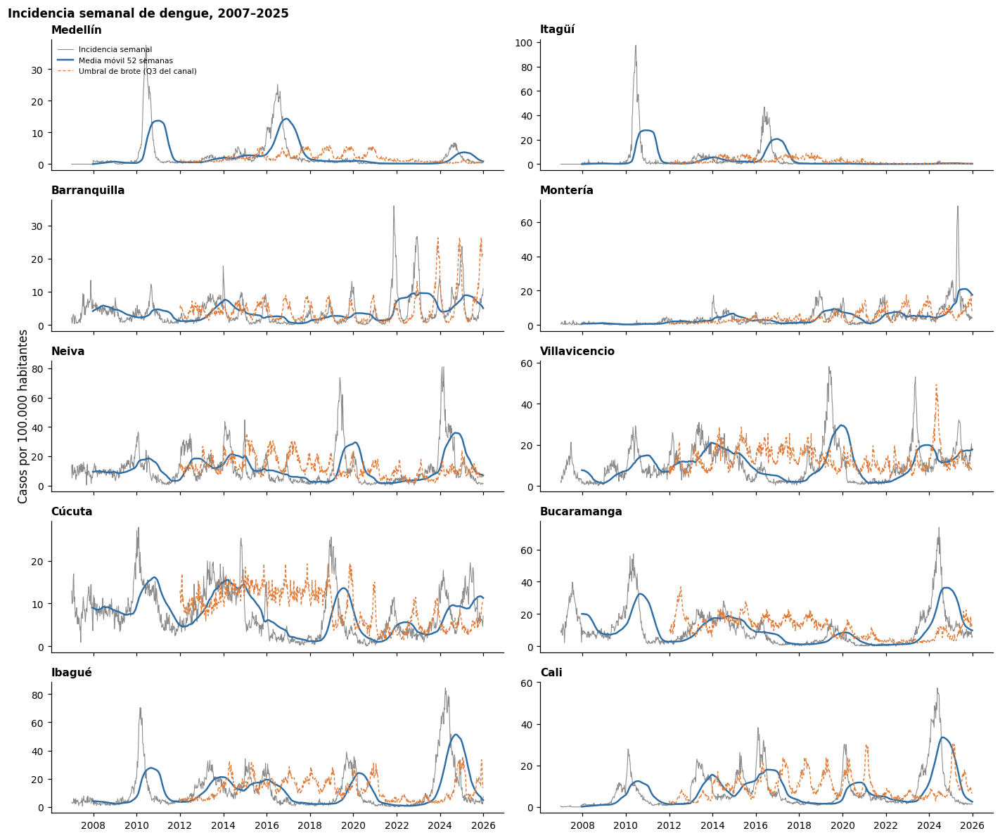

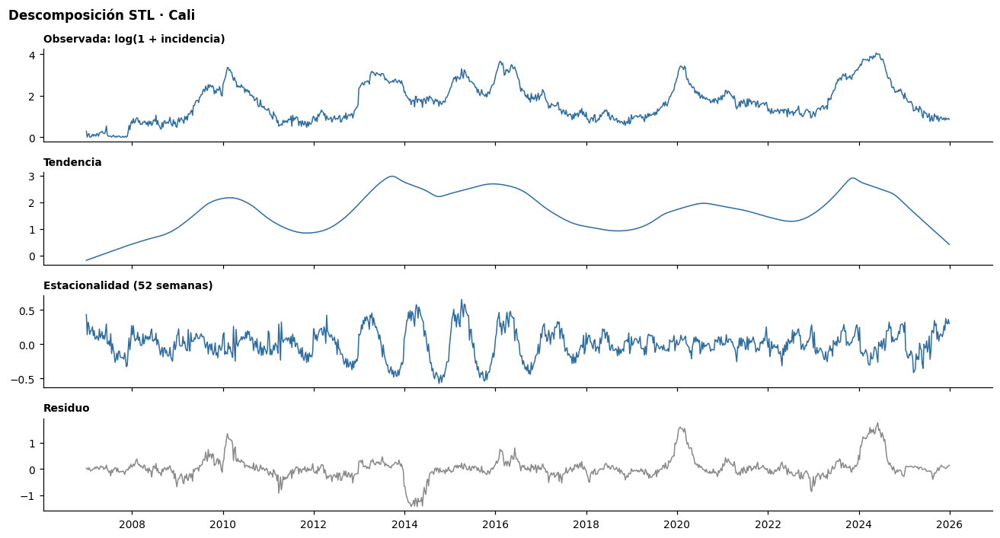

Cali · varianza explicada: tendencia 64% · estacionalidad 5% · residuo 21% (no suman 100 %: los componentes no son independientes)


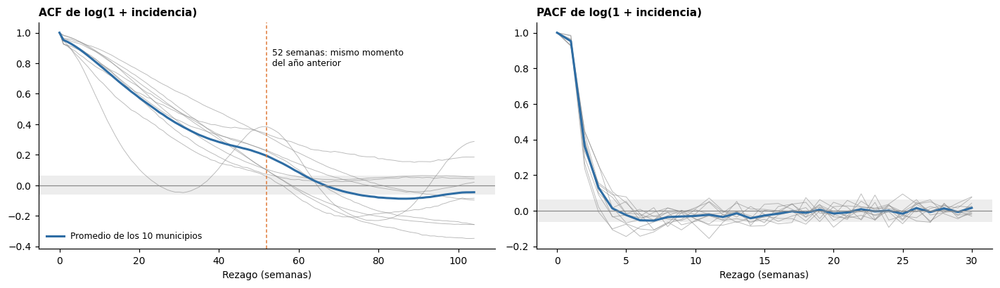

ACF promedio: rezago 1: 0.95 · rezago 4: 0.91 · rezago 8: 0.83 · rezago 12: 0.74 · rezago 26: 0.46 · rezago 52: 0.19
PACF promedio: rezago 1: 0.95 · rezago 2: 0.36 · rezago 3: 0.13 · rezago 4: 0.01 · rezago 8: -0.04 · rezago 12: -0.04
Banda de significancia (±1,96/√n): ±0.062

Control de la serie (2007–2025):
               semanas sin_casos  incidencia_mediana  incidencia_maxima  clima_faltante semana_maxima
municipio                                                                                            
Barranquilla       992     0.2 %                 2.3               36.0               0     2021-SE46
Bucaramanga        992     0.3 %                 7.1               73.7               0     2024-SE25
Cali               992     1.2 %                 3.7               57.2               0     2024-SE21
Cúcuta             992     0.1 %                 6.4               27.8               0     2010-SE05
Ibagué             992     0.2 %                 4.9               84.4      

In [20]:
# Celda 17 · Análisis exploratorio de la serie: tendencia, estacionalidad, ruido y autocorrelación
# Qué hace: (1) la incidencia semanal de los 10 municipios con su media móvil de 52 semanas y el
#   umbral del canal; (2) la descomposición STL de un municipio (tendencia + estacionalidad + residuo);
#   (3) la autocorrelación (ACF) y la autocorrelación parcial (PACF) de log(1 + incidencia);
#   (4) una tabla de control: semanas sin casos, la semana más alta (atípico) y faltantes de clima.
# Para qué: decidir el tamaño de la ventana (cuántas semanas mira hacia atrás la red recurrente) y
#   justificar una red recurrente frente a un modelo clásico (ARIMA).
from statsmodels.tsa.stattools import acf, pacf
from statsmodels.tsa.seasonal import STL

fig, axes = plt.subplots(5, 2, figsize=(13, 11), sharex=True)
for ax, (cod, nombre) in zip(axes.ravel(), NOMBRE.items()):
    d = datos[datos["divipola"] == cod]
    ax.plot(d["fecha"], d["incidencia"], color=GRIS, lw=0.7, label="Incidencia semanal")
    ax.plot(d["fecha"], d["incidencia"].rolling(52).mean(), color=AZUL, lw=1.6, label="Media móvil 52 semanas")
    ax.plot(d["fecha"], d["q3_canal"], color=NARANJA, lw=0.9, ls=(0, (3, 2)), label="Umbral de brote (Q3 del canal)")
    ax.set_title(nombre, loc="left")
axes[0, 0].legend(loc="upper left", fontsize=7, frameon=False)
fig.supylabel("Casos por 100.000 habitantes")
fig.suptitle("Incidencia semanal de dengue, 2007–2025", x=0.01, ha="left", fontsize=11, fontweight="bold")
plt.tight_layout(); plt.show()

# (2) Descomposición STL de Cali (periodo de 52 semanas, robusta a los picos)
cali = datos[datos["divipola"] == "76001"].set_index("fecha")["log_inc"]
stl = STL(cali.values, period=52, robust=True).fit()
fig, axes = plt.subplots(4, 1, figsize=(12, 6.5), sharex=True)
for ax, (serie_c, nombre) in zip(axes, [(cali.values, "Observada: log(1 + incidencia)"), (stl.trend, "Tendencia"),
                                        (stl.seasonal, "Estacionalidad (52 semanas)"), (stl.resid, "Residuo")]):
    ax.plot(cali.index, serie_c, color=AZUL if nombre != "Residuo" else GRIS, lw=1)
    ax.set_title(nombre, loc="left", fontsize=9)
fig.suptitle("Descomposición STL · Cali", x=0.01, ha="left", fontsize=11, fontweight="bold")
plt.tight_layout(); plt.show()
var_total = np.var(cali.values)
print(f"Cali · varianza explicada: tendencia {np.var(stl.trend) / var_total:.0%} · "
      f"estacionalidad {np.var(stl.seasonal) / var_total:.0%} · residuo {np.var(stl.resid) / var_total:.0%} "
      "(no suman 100 %: los componentes no son independientes)")

# (3) ACF y PACF de log(1 + incidencia), municipio por municipio, hasta 2 años de rezago
REZAGOS = 104
acfs, pacfs = [], []
for cod in NOMBRE:
    s = datos.loc[datos["divipola"] == cod, "log_inc"].dropna().values
    acfs.append(acf(s, nlags=REZAGOS)); pacfs.append(pacf(s, nlags=30))
acfs, pacfs = np.array(acfs), np.array(pacfs)
banda = 1.96 / np.sqrt(len(s))
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for ax, valores, titulo, n in [(axes[0], acfs, "ACF", REZAGOS), (axes[1], pacfs, "PACF", 30)]:
    for v in valores:
        ax.plot(range(n + 1), v, color=GRIS, lw=0.6, alpha=0.6)
    ax.plot(range(n + 1), valores.mean(axis=0), color=AZUL, lw=2, label="Promedio de los 10 municipios")
    ax.axhspan(-banda, banda, color=GRIS, alpha=0.15, lw=0)
    ax.axhline(0, color=GRIS, lw=0.8)
    ax.set_xlabel("Rezago (semanas)"); ax.set_title(f"{titulo} de log(1 + incidencia)", loc="left")
axes[0].axvline(52, color=NARANJA, lw=1, ls=(0, (3, 2)))
axes[0].annotate("52 semanas: mismo momento\ndel año anterior", (52, 0.9), xytext=(5, 0),
                 textcoords="offset points", fontsize=8, va="top")
axes[0].legend(loc="lower left", fontsize=8, frameon=False)
plt.tight_layout(); plt.show()
media_acf, media_pacf = acfs.mean(axis=0), pacfs.mean(axis=0)
print("ACF promedio:", " · ".join(f"rezago {k}: {media_acf[k]:.2f}" for k in (1, 4, 8, 12, 26, 52)))
print("PACF promedio:", " · ".join(f"rezago {k}: {media_pacf[k]:.2f}" for k in (1, 2, 3, 4, 8, 12)))
print(f"Banda de significancia (±1,96/√n): ±{banda:.3f}")

# (4) Tabla de control de la serie
control = datos.groupby("municipio").agg(
    semanas=("casos", "size"), sin_casos=("casos", lambda c: (c == 0).mean()),
    incidencia_mediana=("incidencia", "median"), incidencia_maxima=("incidencia", "max"),
    clima_faltante=("t2m", lambda c: c.isna().sum()))
control["semana_maxima"] = datos.loc[datos.groupby("municipio")["incidencia"].idxmax()].set_index("municipio") \
    .apply(lambda f: f"{int(f['anio'])}-SE{int(f['semana']):02d}", axis=1)
control["sin_casos"] = (100 * control["sin_casos"]).round(1).astype(str) + " %"
print("\nControl de la serie (2007–2025):")
print(control.round(1).to_string())


### ¿Por qué una red recurrente y no un modelo clásico (ARIMA)?

- **ARIMA se ajusta serie por serie** (serían 10 modelos) y es lineal. El clima entraría como regresor lineal (ARIMAX), con los rezagos elegidos a mano.
- **Una sola red recurrente aprende de las 10 series a la vez** (comparte parámetros entre municipios), combina incidencia y clima de forma no lineal y aprende qué semanas del pasado importan.
- **El costo:** necesita más datos y no garantiza ser mejor. Por eso se compara siempre contra una referencia ingenua (la persistencia: «la semana que viene será igual a esta») y contra el MLP de la Fase 1. Si la red no las supera, la ventaja teórica no se materializa, y así se reporta.

**Lectura de la celda 17.** (1) **Memoria de corto plazo fuerte:** la ACF promedio vale 0,95 a una semana, 0,74 a 12 y 0,46 a 26; la PACF se corta después del rezago 3 (0,95; 0,36; 0,13; 0,01): la serie se comporta como un proceso autorregresivo de orden bajo. (2) **Estacionalidad anual débil:** a 52 semanas la ACF es 0,19 y no hay pico; en Cali, la descomposición STL atribuye el 64 % de la varianza a la tendencia, el 5 % a la estacionalidad y el 21 % al residuo. Pesan más los ciclos epidémicos de varios años (2010, 2013, 2016, 2019–2020 y 2024) que la estación. (3) **Datos:** 992 semanas por municipio, sin faltantes de clima; Itagüí tiene el 32,6 % de semanas sin casos, y los máximos de 2024 en Bucaramanga, Cali, Ibagué y Neiva superan lo visto en los años de entrenamiento. **Decisión:** ventana de referencia de 12 semanas (cubre la memoria de corto plazo y el rezago del clima de la Fase 1), comparada con 4, 26 y 52 en la celda 21.

In [21]:
# Celda 18 · Ventanas deslizantes y partición cronológica de la rama B
# Qué hace: convierte la tabla en secuencias. Cada muestra es una ventana con las últimas W semanas
#   de un municipio (hasta la semana t) y su objetivo es la incidencia de la semana t + 1.
#   · Por paso (cada semana de la ventana): log(1 + incidencia), temperatura, humedad, log(1 + lluvia)
#     y la semana del año (seno y coseno). Es la versión «sin aplanar» de los rezagos de la Fase 1.
#   · Estáticas (no cambian dentro de la ventana; entran a la cabeza densa): el umbral de brote de
#     t + 1 (sale de años previos) y el municipio (one-hot).
#   · Objetivo: log(1 + incidencia de t + 1), estandarizado. Las métricas se reportan en la escala
#     original (casos por 100.000 habitantes).
# Partición: la misma de la Fase 1 por año de la semana que se predice (train 2012–2019, val 2020–2022,
#   test 2023–2025). Respeta el orden del tiempo: el modelo nunca aprende del futuro de lo que evalúa.
#   Las medias y desviaciones salen solo de entrenamiento.
# Ventana de referencia: W = 12 semanas. Por qué: (1) el clima actúa con rezago sobre el mosquito y
#   el virus; la Fase 1 ya usaba 12 semanas de clima (tres promedios de 4); (2) la ACF de la celda 17
#   sigue alta durante varias semanas, así que el pasado reciente pesa. La celda 21 compara 4, 12, 26 y 52.
datos["log_lluvia"] = np.log1p(datos["lluvia"])
PASO = ["log_inc", "t2m", "rh2m", "log_lluvia", "sem_sin", "sem_cos"]
ESTATICAS = ["log_q3_t1"] + list(dummies.columns)
A_ESTANDARIZAR = ["log_inc", "t2m", "rh2m", "log_lluvia"]
PART_SERIE = {"train": range(2012, 2020), "val": [2020, 2021, 2022], "test": [2023, 2024, 2025]}

base = datos[datos["anio_obj"] <= 2019]                       # solo semanas que alimentan entrenamiento
media_p, desv_p = base[A_ESTANDARIZAR].mean(), base[A_ESTANDARIZAR].std()
pasos = datos[PASO].copy()
pasos[A_ESTANDARIZAR] = (pasos[A_ESTANDARIZAR] - media_p) / desv_p
MATRIZ_PASOS = pasos.to_numpy(np.float32)

entrena = datos["anio_obj"].isin(list(PART_SERIE["train"])) & datos["y_inc"].notna()
estaticas = datos[ESTATICAS].copy()
media_q3, desv_q3 = estaticas.loc[entrena, "log_q3_t1"].mean(), estaticas.loc[entrena, "log_q3_t1"].std()
estaticas["log_q3_t1"] = (estaticas["log_q3_t1"] - media_q3) / desv_q3
MATRIZ_ESTATICAS = estaticas.to_numpy(np.float32)

objetivo_log = np.log1p(datos["y_inc"])
MEDIA_Y, DESV_Y = objetivo_log[entrena].mean(), objetivo_log[entrena].std()
OBJETIVO_Z = ((objetivo_log - MEDIA_Y) / DESV_Y).to_numpy(np.float32)
MUNICIPIO_FILA = datos["divipola"].to_numpy()


def ventanas(W, filas):
    """Para cada fila t devuelve la ventana [t-W+1, …, t] del mismo municipio. Descarta las ventanas
    que cruzan de un municipio a otro o que tienen algún dato faltante."""
    filas = np.asarray(filas)
    filas = filas[filas - W + 1 >= 0]
    filas = filas[MUNICIPIO_FILA[filas - W + 1] == MUNICIPIO_FILA[filas]]
    X = np.stack([MATRIZ_PASOS[i - W + 1:i + 1] for i in filas])
    completas = ~np.isnan(X).any(axis=(1, 2)) & ~np.isnan(MATRIZ_ESTATICAS[filas]).any(axis=1)
    return filas[completas], X[completas]


def conjunto_serie(W):
    """Tensores de entrenamiento, validación y prueba para una ventana de W semanas."""
    salida = {}
    for k, anios in PART_SERIE.items():
        candidatas = datos.index[datos["anio_obj"].isin(list(anios)) & datos["y_inc"].notna()]
        filas, X = ventanas(W, candidatas)
        salida[k] = {"filas": filas, "X": torch.tensor(X), "S": torch.tensor(MATRIZ_ESTATICAS[filas]),
                     "y": torch.tensor(OBJETIVO_Z[filas]).view(-1, 1)}
    return salida


VENTANA = 12
D12 = conjunto_serie(VENTANA)
for k, D in D12.items():
    print(f"{k:5s}: X {tuple(D['X'].shape)} (muestras, semanas, variables por paso) · "
          f"S {tuple(D['S'].shape)} · y {tuple(D['y'].shape)}")
ejemplo = datos.loc[D12["test"]["filas"][0]]
print(f"\nEjemplo: la primera ventana de prueba termina en {ejemplo['municipio']} {int(ejemplo['anio'])}-"
      f"SE{int(ejemplo['semana']):02d} y predice la incidencia de la semana siguiente ({ejemplo['y_inc']:.2f}).")


train: X (4170, 12, 6) (muestras, semanas, variables por paso) · S (4170, 11) · y (4170, 1)
val  : X (1570, 12, 6) (muestras, semanas, variables por paso) · S (1570, 11) · y (1570, 1)
test : X (1570, 12, 6) (muestras, semanas, variables por paso) · S (1570, 11) · y (1570, 1)

Ejemplo: la primera ventana de prueba termina en Medellín 2022-SE52 y predice la incidencia de la semana siguiente (0.12).


In [22]:
# Celda 19 · Arquitectura recurrente (RNN simple, LSTM o GRU) y su bucle de entrenamiento
# Qué hace: define una sola clase con tres celdas intercambiables, para que la comparación sea justa
#   (misma cabeza, mismo estado oculto de 64, mismos datos, mismo entrenamiento):
#   · La celda recorre la ventana semana a semana y resume el pasado en su estado oculto h_t.
#   · La cabeza densa recibe [h_t ‖ estáticas] y predice log(1 + incidencia de t + 1) estandarizado.
#   · RNN simple: h_t = tanh(W·x_t + U·h_{t-1}); sin compuertas, es el contraste (desvanecimiento).
#   · LSTM: compuertas de olvido, entrada y salida sobre un estado de celda C_t (Hochreiter y Schmidhuber, 1997).
#   · GRU: compuertas de actualización y reinicio; menos parámetros (Cho et al., 2014).
# Entrenamiento (hiperparámetros sugeridos por la actividad): Adam, tasa 0,001, lote 32, pérdida MSE,
#   hasta 100 épocas con parada temprana (se detiene si la validación no mejora en 10 épocas y se
#   queda con la mejor). Se entrena en CPU: con redes de este tamaño la GPU no acelera y en CPU los
#   resultados se repiten exactamente con la misma semilla.
CELDAS = {"RNN": nn.RNN, "LSTM": nn.LSTM, "GRU": nn.GRU}


class Recurrente(nn.Module):
    def __init__(self, tipo, n_paso, n_estaticas, oculta=64):
        super().__init__()
        self.tipo = tipo
        self.celda = CELDAS[tipo](n_paso, oculta, batch_first=True)
        self.cabeza = nn.Sequential(nn.Linear(oculta + n_estaticas, 32), nn.ReLU(), nn.Linear(32, 1))

    def codificar(self, x):
        """Estado oculto del último paso (semana t): el resumen de la ventana. En la fusión
        (sección 7) es la representación z_serie."""
        salida, _ = self.celda(x)
        return salida[:, -1]

    def forward(self, x, s):
        return self.cabeza(torch.cat([self.codificar(x), s], dim=1))


def entrenar_rec(modelo, D, epocas=100, paciencia=10, lr=1e-3, tam_lote=32, semilla=SEMILLA):
    criterio = nn.MSELoss()
    optimizador = torch.optim.Adam(modelo.parameters(), lr=lr)
    generador = torch.Generator().manual_seed(semilla)
    Xtr, Str, ytr = D["train"]["X"], D["train"]["S"], D["train"]["y"]
    hist = {"train": [], "val": []}
    mejor_val, mejor_estado, mejor_epoca = float("inf"), None, 0
    for epoca in range(1, epocas + 1):
        modelo.train()
        orden = torch.randperm(len(Xtr), generator=generador)
        suma = 0.0
        for i in range(0, len(Xtr), tam_lote):
            idx = orden[i:i + tam_lote]
            perdida = criterio(modelo(Xtr[idx], Str[idx]), ytr[idx])
            optimizador.zero_grad()
            perdida.backward()
            optimizador.step()
            suma += perdida.item() * len(idx)
        hist["train"].append(suma / len(Xtr))
        modelo.eval()
        with torch.no_grad():
            val = criterio(modelo(D["val"]["X"], D["val"]["S"]), D["val"]["y"]).item()
        hist["val"].append(val)
        if val < mejor_val:
            mejor_val, mejor_epoca, mejor_estado = val, epoca, copy.deepcopy(modelo.state_dict())
        elif epoca - mejor_epoca >= paciencia:
            break
    modelo.load_state_dict(mejor_estado)
    hist["mejor_epoca"] = mejor_epoca
    return hist


def predecir(modelo, Dk):
    """Incidencia predicha para t + 1 en la escala original (casos por 100.000 habitantes)."""
    modelo.eval()
    with torch.no_grad():
        z = modelo(Dk["X"], Dk["S"]).numpy().ravel()
    return np.clip(np.expm1(z * DESV_Y + MEDIA_Y), 0, None)


def metricas_reg(real, pred):
    """RMSE y MAE en casos por 100.000 habitantes. MAPE solo sobre semanas con casos (con incidencia 0
    el error porcentual no está definido); con incidencias muy bajas el MAPE se infla, por eso se lee
    junto con el MAE."""
    real, pred = np.asarray(real), np.asarray(pred)
    con_casos = real > 0
    return {"RMSE": float(np.sqrt(np.mean((pred - real) ** 2))), "MAE": float(np.mean(np.abs(pred - real))),
            "MAPE %": float(100 * np.mean(np.abs(pred[con_casos] - real[con_casos]) / real[con_casos]))}


def contar_parametros(modelo):
    return sum(p.numel() for p in modelo.parameters())


for tipo in CELDAS:
    torch.manual_seed(SEMILLA)
    m = Recurrente(tipo, len(PASO), len(ESTATICAS))
    print(f"{tipo:4s}: {contar_parametros(m.celda):6,d} parámetros en la celda · "
          f"{contar_parametros(m):6,d} en total".replace(",", "."))


RNN :  4.608 parámetros en la celda ·  7.073 en total
LSTM: 18.432 parámetros en la celda · 20.897 en total
GRU : 13.824 parámetros en la celda · 16.289 en total


RNN  semilla 2026:  17 épocas · RMSE val 1.338 · 7 s
RNN  semilla 2027:  17 épocas · RMSE val 1.354 · 7 s
RNN  semilla 2028:  15 épocas · RMSE val 1.407 · 6 s
LSTM semilla 2026:  17 épocas · RMSE val 1.386 · 7 s
LSTM semilla 2027:  17 épocas · RMSE val 1.376 · 8 s
LSTM semilla 2028:  16 épocas · RMSE val 1.372 · 6 s
GRU  semilla 2026:  15 épocas · RMSE val 1.311 · 12 s
GRU  semilla 2027:  17 épocas · RMSE val 1.319 · 14 s
GRU  semilla 2028:  22 épocas · RMSE val 1.349 · 18 s

Ventana de 12 semanas · media ± desviación de 3 semillas · incidencia por 100.000 habitantes
                   RMSE val        MAE val      MAPE % val      RMSE test       MAE test     MAPE % test  parámetros épocas (media) segundos (media)
RNN           1.367 ± 0.036  0.746 ± 0.009  46.482 ± 0.985  3.920 ± 0.663  1.974 ± 0.219  23.282 ± 0.377        7073           16.3              6.9
LSTM          1.378 ± 0.007  0.750 ± 0.006  43.570 ± 3.172  3.395 ± 0.058  1.819 ± 0.021  22.844 ± 0.362       20897           1

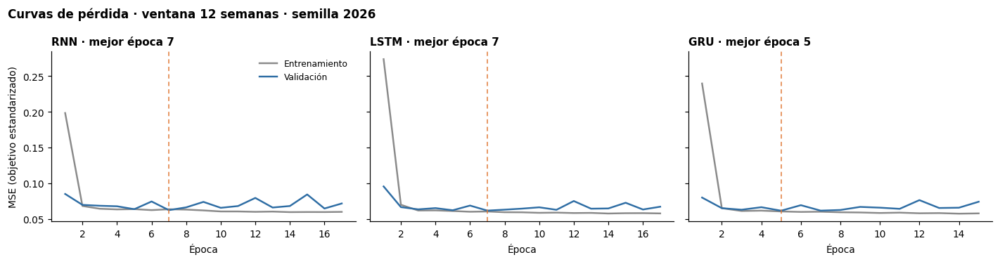


RMSE medio de validación: LSTM 1.378 · GRU 1.326 · RNN 1.367
Celda elegida para la rama B: GRU (menor RMSE medio de validación, por encima de la variación entre semillas).
Mejor semilla por celda: {'RNN': 2026, 'LSTM': 2028, 'GRU': 2026} · pesos en /content/centinela_fase2/pesos/


In [23]:
# Celda 20 · Entrenamiento comparativo: RNN simple, LSTM y GRU con la ventana de 12 semanas
# Qué hace: entrena las tres celdas con 3 semillas cada una (9 modelos) y reporta la media y la
#   desviación de RMSE, MAE y MAPE en validación y en prueba. Con una sola semilla, una diferencia
#   pequeña entre LSTM y GRU podría ser suerte de la inicialización.
# Referencia ingenua: «la semana que viene será igual a esta» (persistencia de la incidencia). Si una
#   red no la supera, no aporta.
# Tiempo estimado en Colab (CPU): 5 a 10 minutos.
# Guarda los pesos (.pth) del mejor modelo de cada celda, según la validación.
os.makedirs(f"{CARPETA}/pesos", exist_ok=True)
SEMILLAS = [SEMILLA, SEMILLA + 1, SEMILLA + 2]
filas, modelos_b, historias_b = [], {}, {}
for tipo in CELDAS:
    for s in SEMILLAS:
        torch.manual_seed(s)
        modelo_b = Recurrente(tipo, len(PASO), len(ESTATICAS))
        inicio = time.time()
        h = entrenar_rec(modelo_b, D12, semilla=s)
        fila = {"celda": tipo, "semilla": s, "épocas": len(h["val"]), "mejor época": h["mejor_epoca"],
                "segundos": time.time() - inicio}
        for k in ("val", "test"):
            real = datos.loc[D12[k]["filas"], "y_inc"].values
            fila.update({f"{m} {k}": v for m, v in metricas_reg(real, predecir(modelo_b, D12[k])).items()})
        filas.append(fila); modelos_b[(tipo, s)] = modelo_b; historias_b[(tipo, s)] = h
        print(f"{tipo:4s} semilla {s}: {fila['épocas']:3d} épocas · RMSE val {fila['RMSE val']:.3f} · "
              f"{fila['segundos']:.0f} s")
res_b = pd.DataFrame(filas)

# Persistencia de la incidencia en las mismas filas
fila_p = {"celda": "Persistencia (ingenua)"}
for k in ("val", "test"):
    filas_k = D12[k]["filas"]
    fila_p.update({f"{m} {k}": v for m, v in metricas_reg(datos.loc[filas_k, "y_inc"],
                                                         datos.loc[filas_k, "incidencia"]).items()})

columnas = [f"{m} {k}" for k in ("val", "test") for m in ("RMSE", "MAE", "MAPE %")]
resumen_b = res_b.groupby("celda", sort=False)[columnas].agg(["mean", "std"])
tabla_b = pd.DataFrame({c: [f"{resumen_b.loc[t, (c, 'mean')]:.3f} ± {resumen_b.loc[t, (c, 'std')]:.3f}"
                            for t in CELDAS] + [f"{fila_p[c]:.3f}"] for c in columnas},
                       index=list(CELDAS) + ["Persistencia"])
tabla_b["parámetros"] = [contar_parametros(modelos_b[(t, SEMILLA)]) for t in CELDAS] + [0]
tabla_b["épocas (media)"] = list(res_b.groupby("celda", sort=False)["épocas"].mean().round(1)) + ["—"]
tabla_b["segundos (media)"] = list(res_b.groupby("celda", sort=False)["segundos"].mean().round(1)) + ["—"]
print(f"\nVentana de {VENTANA} semanas · media ± desviación de 3 semillas · incidencia por 100.000 habitantes")
print(tabla_b.to_string())

# Curvas de pérdida de la semilla 2026
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4), sharey=True)
for ax, tipo in zip(axes, CELDAS):
    h = historias_b[(tipo, SEMILLA)]
    ep = np.arange(1, len(h["train"]) + 1)
    ax.plot(ep, h["train"], color=GRIS, lw=1.6, label="Entrenamiento")
    ax.plot(ep, h["val"], color=AZUL, lw=1.6, label="Validación")
    ax.axvline(h["mejor_epoca"], color=NARANJA, lw=1, ls=(0, (4, 3)))
    ax.set_title(f"{tipo} · mejor época {h['mejor_epoca']}", loc="left"); ax.set_xlabel("Época")
axes[0].set_ylabel("MSE (objetivo estandarizado)"); axes[0].legend(frameon=False, fontsize=8)
fig.suptitle(f"Curvas de pérdida · ventana {VENTANA} semanas · semilla {SEMILLA}", x=0.01, ha="left",
             fontsize=11, fontweight="bold")
plt.tight_layout(); plt.show()

# Mejor semilla de cada celda (menor RMSE de validación) y sus pesos
MEJOR_B = {t: res_b[res_b["celda"] == t].sort_values("RMSE val").iloc[0]["semilla"] for t in CELDAS}
for tipo, s in MEJOR_B.items():
    torch.save({"estado": modelos_b[(tipo, s)].state_dict(),
                "config": {"tipo": tipo, "ventana": VENTANA, "oculta": 64, "paso": PASO, "estaticas": ESTATICAS,
                           "semilla": int(s), "particion": "train 2012-2019, val 2020-2022, test 2023-2025"},
                "normalizacion": {"media_pasos": media_p.to_dict(), "desv_pasos": desv_p.to_dict(),
                                  "media_q3": media_q3, "desv_q3": desv_q3, "media_y": MEDIA_Y, "desv_y": DESV_Y}},
               f"{CARPETA}/pesos/rama_b_{tipo.lower()}_w{VENTANA}.pth")

# Decisión LSTM frente a GRU: menor RMSE medio de validación; si la diferencia es menor que la
# variación entre semillas, es un empate técnico y se prefiere la más liviana (GRU).
rmse = resumen_b[("RMSE val", "mean")]; dispersion = resumen_b[("RMSE val", "std")]
diferencia = rmse["LSTM"] - rmse["GRU"]
if abs(diferencia) < max(dispersion["LSTM"], dispersion["GRU"]):
    ELEGIDA = "GRU"
    razon = "empate técnico (la diferencia es menor que la variación entre semillas): se prefiere la más liviana"
else:
    ELEGIDA = "LSTM" if diferencia < 0 else "GRU"
    razon = "menor RMSE medio de validación, por encima de la variación entre semillas"
print(f"\nRMSE medio de validación: LSTM {rmse['LSTM']:.3f} · GRU {rmse['GRU']:.3f} · RNN {rmse['RNN']:.3f}")
print(f"Celda elegida para la rama B: {ELEGIDA} ({razon}).")
print("Mejor semilla por celda:", {t: int(s) for t, s in MEJOR_B.items()}, "· pesos en", f"{CARPETA}/pesos/")


**Lectura.** (1) Con el objetivo «nivel», solo la GRU iguala a la persistencia en validación (RMSE 1,326 ± 0,020 frente a 1,332); la RNN (1,367) y la LSTM (1,378) quedan por encima. (2) **Se elige la GRU frente a la LSTM:** la diferencia (0,052) supera la variación entre semillas (0,020), y además tiene menos parámetros (16.289 frente a 20.897). (3) En prueba **ninguna red supera a la persistencia** en RMSE (GRU 3,480; LSTM 3,395; RNN 3,920; persistencia 2,977) ni en MAE (1,82 frente a 1,71); solo en MAPE (22,5 a 23,3 % frente a 24,3 %). Causas: autocorrelación de 0,95 a una semana, y la epidemia de 2024, con incidencias por encima de todo lo visto en 2012–2019; la red que predice el nivel se queda corta en los picos (celda 23). (4) La RNN simple es la más inestable en prueba (desviación de 0,663 entre semillas, frente a 0,058 de la LSTM). (5) Curvas: el mínimo de validación llega entre las épocas 5 y 7; después la validación oscila y el entrenamiento casi no baja. La red aprende pronto lo que hay que aprender y la parada temprana evita el sobreajuste. Este resultado motivó la mejora de la celda 25.

W =  4 · LSTM: RMSE val 1.411
W =  4 · GRU : RMSE val 1.362
W = 12 · LSTM: RMSE val 1.386
W = 12 · GRU : RMSE val 1.311
W = 26 · LSTM: RMSE val 1.376
W = 26 · GRU : RMSE val 1.311
W = 52 · LSTM: RMSE val 1.378
W = 52 · GRU : RMSE val 1.312

Semilla 2026 · incidencia por 100.000 habitantes
        RMSE val        MAE val        RMSE test        MAE test       
celda        GRU   LSTM     GRU   LSTM       GRU   LSTM      GRU   LSTM
ventana                                                                
4          1.362  1.411   0.745  0.760     3.408  3.300    1.827  1.799
12         1.311  1.386   0.730  0.744     3.302  3.329    1.776  1.803
26         1.311  1.376   0.730  0.741     3.343  3.305    1.787  1.798
52         1.312  1.378   0.732  0.742     3.358  3.311    1.791  1.801


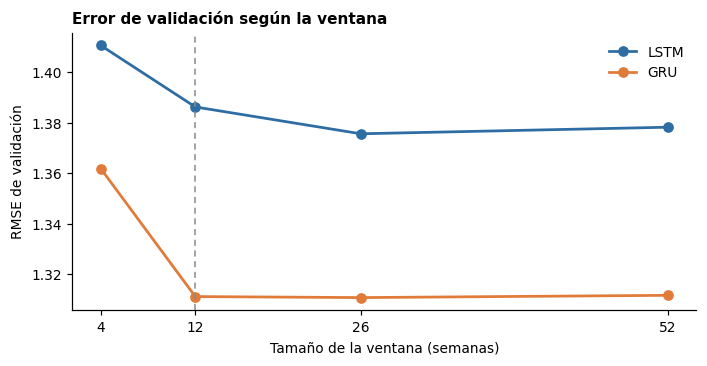

Menor RMSE de validación: ventana 26 con GRU (1.311) · referencia de 12 semanas: LSTM 1.386, GRU 1.311
Ninguna ventana mejora a la de 12 en más que la variación entre semillas (0.020): se mantiene la de 12 semanas (más corta y más rápida de entrenar).


In [24]:
# Celda 21 · ¿Cuántas semanas debe mirar la red? Ventanas de 4, 12, 26 y 52
# Qué hace: entrena LSTM y GRU (semilla 2026) con cuatro tamaños de ventana sobre las MISMAS semanas
#   objetivo (todas tienen al menos 52 semanas de historia), y compara en validación. La de 12 ya
#   está entrenada en la celda 20. La ventana se decide en validación; la prueba solo se informa.
#   4 semanas = un mes; 12 = un trimestre (la referencia); 26 = medio año; 52 = un año completo, que
#   incluye la misma semana del año anterior (el pico de la ACF en el rezago 52).
# Tiempo estimado en Colab (CPU): 5 a 10 minutos (la ventana de 52 es la más lenta).
VENTANAS = [4, 12, 26, 52]
conjuntos_w = {12: D12}
modelos_w = {(t, 12): modelos_b[(t, SEMILLA)] for t in ("LSTM", "GRU")}
filas_w = []
for W in VENTANAS:
    if W not in conjuntos_w:
        conjuntos_w[W] = conjunto_serie(W)
    assert len(conjuntos_w[W]["val"]["filas"]) == len(D12["val"]["filas"]), "Las ventanas no cubren las mismas semanas"
    for tipo in ("LSTM", "GRU"):
        if (tipo, W) not in modelos_w:
            torch.manual_seed(SEMILLA)
            modelos_w[(tipo, W)] = Recurrente(tipo, len(PASO), len(ESTATICAS))
            entrenar_rec(modelos_w[(tipo, W)], conjuntos_w[W])
        fila = {"ventana": W, "celda": tipo}
        for k in ("val", "test"):
            real = datos.loc[conjuntos_w[W][k]["filas"], "y_inc"].values
            fila.update({f"{m} {k}": v for m, v in metricas_reg(real, predecir(modelos_w[(tipo, W)],
                                                                             conjuntos_w[W][k])).items()})
        filas_w.append(fila)
        print(f"W = {W:2d} · {tipo:4s}: RMSE val {fila['RMSE val']:.3f}")
res_w = pd.DataFrame(filas_w)
print("\nSemilla 2026 · incidencia por 100.000 habitantes")
print(res_w.pivot(index="ventana", columns="celda", values=["RMSE val", "MAE val", "RMSE test", "MAE test"])
      .round(3).to_string())

fig, ax = plt.subplots(figsize=(6.5, 3.4))
for tipo, color in [("LSTM", AZUL), ("GRU", NARANJA)]:
    d = res_w[res_w["celda"] == tipo]
    ax.plot(d["ventana"], d["RMSE val"], marker="o", color=color, lw=1.8, label=tipo)
ax.axvline(VENTANA, color=GRIS, lw=1, ls=(0, (4, 3)))
ax.set_xticks(VENTANAS); ax.set_xlabel("Tamaño de la ventana (semanas)"); ax.set_ylabel("RMSE de validación")
ax.set_title("Error de validación según la ventana", loc="left"); ax.legend(frameon=False)
plt.tight_layout(); plt.show()
mejor_w = res_w.loc[res_w["RMSE val"].idxmin()]
referencia = res_w[res_w["ventana"] == VENTANA].set_index("celda")["RMSE val"]
print(f"Menor RMSE de validación: ventana {int(mejor_w['ventana'])} con {mejor_w['celda']} "
      f"({mejor_w['RMSE val']:.3f}) · referencia de {VENTANA} semanas: "
      f"LSTM {referencia['LSTM']:.3f}, GRU {referencia['GRU']:.3f}")
variacion = resumen_b[("RMSE val", "std")][["LSTM", "GRU"]].max()     # variación entre semillas (celda 20)
if referencia.min() - mejor_w["RMSE val"] > variacion:
    print(f"La ventana de {int(mejor_w['ventana'])} semanas mejora a la de {VENTANA} en más que la variación "
          f"entre semillas ({variacion:.3f}): es una mejora real y se debe considerar cambiar la referencia.")
else:
    print(f"Ninguna ventana mejora a la de {VENTANA} en más que la variación entre semillas ({variacion:.3f}): "
          f"se mantiene la de {VENTANA} semanas (más corta y más rápida de entrenar).")


**Lectura.** La ventana de 4 semanas es peor (GRU 1,362; LSTM 1,411) y alargarla a 26 o 52 no mejora (GRU 1,311; 1,311; 1,312). La diferencia entre 12 y 26 semanas (menos de 0,001) es mucho menor que la variación entre semillas (0,020): **se mantiene la ventana de 12 semanas**. Es coherente con la PACF de la celda 17: lo útil está en las semanas recientes, y más pasado no agrega información.

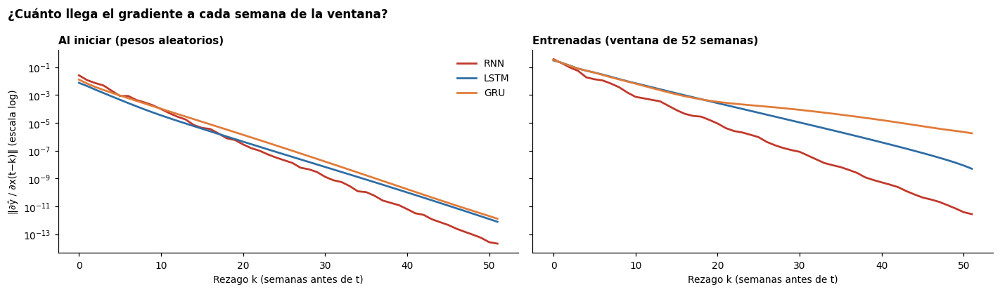

     etapa celda  rezago 0  rezago 12  rezago 51  rezago 51 / rezago 0 conserva por semana  primer rezago < 1 % del rezago 0
Al iniciar   RNN  2.62e-02   2.81e-05   2.14e-14              8.18e-13                 57%                                 9
Al iniciar  LSTM  7.60e-03   1.41e-05   7.91e-13              1.04e-10                 63%                                 9
Al iniciar   GRU  1.29e-02   4.40e-05   1.32e-12              1.02e-10                 64%                                10
Entrenadas   RNN  3.79e-01   4.55e-04   2.79e-12              7.37e-12                 60%                                 8
Entrenadas  LSTM  3.07e-01   3.66e-03   5.10e-09              1.66e-08                 71%                                13
Entrenadas   GRU  3.27e-01   3.22e-03   1.79e-06              5.49e-06                 73%                                12

Semilla 2026 · validación 2020–2022
celda  RMSE val (12 semanas)  RMSE val (52 semanas)  cambio %
  RNN                  1.3

In [25]:
# Celda 22 · Evidencia del desvanecimiento del gradiente (ventana de 52 semanas)
# Qué hace: mide cuánto «siente» la predicción a cada semana de la ventana. Para cada rezago k
#   (0 = la semana t, 51 = un año atrás) calcula la norma del gradiente ‖∂ŷ / ∂x_{t-k}‖, promediada
#   sobre 512 ventanas de validación. Es la misma señal que viaja hacia atrás en el entrenamiento:
#   si es casi cero para un rezago, la red no puede aprender de esa semana.
#   · Al iniciar (pesos aleatorios): muestra la propiedad de la arquitectura, antes de aprender.
#   · Entrenadas: muestra lo que cada red terminó usando.
# Lo que se espera (Hochreiter y Schmidhuber, 1997): en la RNN simple el gradiente se multiplica en
#   cada paso por la derivada de tanh y por la matriz recurrente, y cae de forma exponencial con el
#   rezago; las compuertas de LSTM y GRU dejan un camino casi aditivo y deberían conservarlo mejor.
# «Conserva por semana»: qué fracción del gradiente sobrevive, en promedio, cada semana que se
#   retrocede (pendiente de log ‖∂ŷ/∂x‖ entre los rezagos 0 y 25).
# Además compara el RMSE de validación con ventana de 52 frente a 12 (dependencias largas).
W_LARGA = 52
D52 = conjuntos_w[W_LARGA]
torch.manual_seed(SEMILLA)
rnn_52 = Recurrente("RNN", len(PASO), len(ESTATICAS))
entrenar_rec(rnn_52, D52)
entrenadas_52 = {"RNN": rnn_52, "LSTM": modelos_w[("LSTM", W_LARGA)], "GRU": modelos_w[("GRU", W_LARGA)]}


def norma_por_rezago(modelo, Dk, n=512):
    modelo.eval()
    x = Dk["X"][:n].clone().requires_grad_(True)
    modelo(x, Dk["S"][:n]).sum().backward()
    norma = x.grad.norm(dim=2).mean(dim=0).numpy()          # una norma por posición de la ventana
    return norma[::-1]                                       # índice = rezago (0 = semana t)


iniciales_52 = {}
for tipo in CELDAS:
    torch.manual_seed(SEMILLA)
    iniciales_52[tipo] = Recurrente(tipo, len(PASO), len(ESTATICAS))
COLOR_CELDA = {"RNN": ROJO, "LSTM": AZUL, "GRU": NARANJA}
normas = {}
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
for ax, (etapa, grupo) in zip(axes, [("Al iniciar (pesos aleatorios)", iniciales_52),
                                      ("Entrenadas (ventana de 52 semanas)", entrenadas_52)]):
    for tipo, modelo_g in grupo.items():
        normas[(etapa, tipo)] = norma_por_rezago(modelo_g, D52["val"])
        ax.plot(range(W_LARGA), normas[(etapa, tipo)], color=COLOR_CELDA[tipo], lw=1.8, label=tipo)
    ax.set_yscale("log"); ax.set_xlabel("Rezago k (semanas antes de t)")
    ax.set_title(etapa, loc="left")
axes[0].set_ylabel("‖∂ŷ / ∂x(t−k)‖ (escala log)"); axes[0].legend(frameon=False)
fig.suptitle("¿Cuánto llega el gradiente a cada semana de la ventana?", x=0.01, ha="left",
             fontsize=11, fontweight="bold")
plt.tight_layout(); plt.show()

filas_g = []
for (etapa, tipo), v in normas.items():
    bajo = np.where(v < 0.01 * v[0])[0]
    pendiente = np.polyfit(np.arange(26), np.log(v[:26]), 1)[0]      # caída media por semana (rezagos 0–25)
    filas_g.append({"etapa": etapa.split(" (")[0], "celda": tipo, "rezago 0": v[0], "rezago 12": v[12],
                    "rezago 51": v[51], "rezago 51 / rezago 0": v[51] / v[0],
                    "conserva por semana": f"{np.exp(pendiente):.0%}",
                    "primer rezago < 1 % del rezago 0": int(bajo[0]) if len(bajo) else "nunca"})
print(pd.DataFrame(filas_g).to_string(index=False, float_format=lambda x: f"{x:.2e}"))

# Dependencias largas: ¿mejora o empeora cada celda al pasar de 12 a 52 semanas?
real_val = datos.loc[D52["val"]["filas"], "y_inc"].values
comparacion_w = pd.DataFrame([
    {"celda": t, "RMSE val (12 semanas)": metricas_reg(real_val, predecir(modelos_b[(t, SEMILLA)], D12["val"]))["RMSE"],
     "RMSE val (52 semanas)": metricas_reg(real_val, predecir(entrenadas_52[t], D52["val"]))["RMSE"]}
    for t in CELDAS])
comparacion_w["cambio %"] = 100 * (comparacion_w["RMSE val (52 semanas)"] / comparacion_w["RMSE val (12 semanas)"] - 1)
print("\nSemilla 2026 · validación 2020–2022")
print(comparacion_w.round(3).to_string(index=False))


**Lectura.** **Al iniciar**, las tres celdas pierden el gradiente casi al mismo ritmo (conservan entre 57 y 64 % por semana): es la arquitectura, sin aprendizaje. **Ya entrenadas**, aparece la diferencia: la RNN conserva el 60 % por semana, la LSTM el 71 % y la GRU el 73 %. A 12 semanas, el gradiente de la RNN (4,55 × 10⁻⁴) es entre 7 y 8 veces menor que el de la LSTM (3,66 × 10⁻³) y la GRU (3,22 × 10⁻³); a 51 semanas, la razón frente al rezago 0 es 7,4 × 10⁻¹² en la RNN, 1,7 × 10⁻⁸ en la LSTM y 5,5 × 10⁻⁶ en la GRU: **la RNN recibe unas 750.000 veces menos señal de hace un año que la GRU**. Esa es la evidencia del desvanecimiento: sin compuertas, la RNN no puede aprender de semanas lejanas. Sin embargo, pasar de 12 a 52 semanas no cambia el RMSE de ninguna (−0,1 %, −0,6 % y +0,04 %): en esta serie la memoria larga no pesa, y por eso la RNN no sale perjudicada en esta tarea (celda 25).

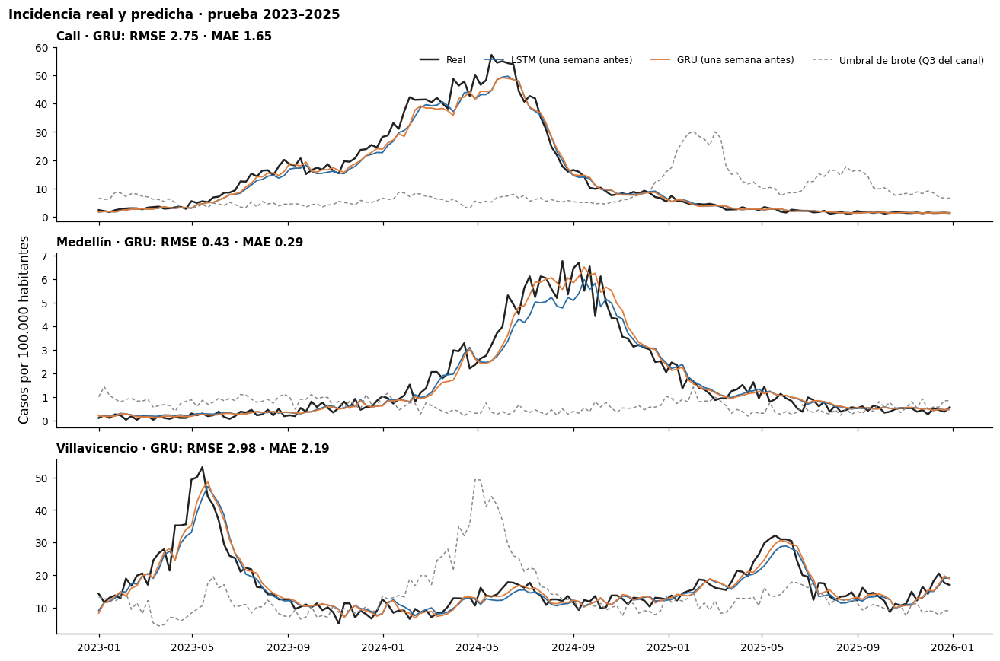

Error en prueba por municipio (las cifras dependen de la escala de cada uno: compárense con la incidencia media)
    municipio  LSTM RMSE  LSTM MAE  GRU RMSE  GRU MAE  incidencia media
     Medellín       0.49      0.30      0.43     0.29              1.61
       Itagüí       0.40      0.30      0.40     0.29              0.40
 Barranquilla       1.39      0.98      1.33     0.96              5.84
     Montería       5.13      2.49      4.41     2.25             10.54
        Neiva       5.21      3.07      5.15     3.02             17.12
Villavicencio       3.28      2.35      2.98     2.19             16.65
       Cúcuta       1.78      1.31      1.77     1.29              8.31
  Bucaramanga       3.77      2.53      3.65     2.46             18.94
       Ibagué       5.15      3.37      5.29     3.36             22.27
         Cali       2.79      1.71      2.75     1.65             14.59


In [26]:
# Celda 23 · Predicciones frente a valores reales en la prueba (2023–2025)
# Qué hace: dibuja, para tres municipios, la incidencia real de cada semana, la que predijeron la LSTM
#   y la GRU una semana antes (mejor semilla, ventana de 12) y el umbral de brote del canal.
#   Cuando la predicción cruza el umbral, el sistema avisaría un brote (celda 24).
# Se eligen Cali, Medellín y Villavicencio: tres climas distintos; Medellín y Villavicencio son,
#   además, los que más imágenes aportan a la fusión.
prueba_b = datos.loc[D12["test"]["filas"], ["divipola", "municipio", "fecha", "y_inc", "q3_t1"]].copy()
prueba_b["fecha_obj"] = prueba_b["fecha"] + pd.Timedelta(weeks=1)
for tipo in ("LSTM", "GRU"):
    prueba_b[f"pred_{tipo}"] = predecir(modelos_b[(tipo, MEJOR_B[tipo])], D12["test"])

fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)
for ax, cod in zip(axes, ["76001", "05001", "50001"]):
    d = prueba_b[prueba_b["divipola"] == cod]
    ax.plot(d["fecha_obj"], d["y_inc"], color="#222222", lw=1.6, label="Real")
    ax.plot(d["fecha_obj"], d["pred_LSTM"], color=AZUL, lw=1.2, label="LSTM (una semana antes)")
    ax.plot(d["fecha_obj"], d["pred_GRU"], color=NARANJA, lw=1.2, label="GRU (una semana antes)")
    ax.plot(d["fecha_obj"], d["q3_t1"], color=GRIS, lw=1, ls=(0, (3, 2)), label="Umbral de brote (Q3 del canal)")
    m = metricas_reg(d["y_inc"], d[f"pred_{ELEGIDA}"])
    ax.set_title(f"{NOMBRE[cod]} · {ELEGIDA}: RMSE {m['RMSE']:.2f} · MAE {m['MAE']:.2f}", loc="left")
axes[0].legend(ncol=4, fontsize=8, frameon=False, loc="upper right")
fig.supylabel("Casos por 100.000 habitantes")
fig.suptitle("Incidencia real y predicha · prueba 2023–2025", x=0.01, ha="left", fontsize=11, fontweight="bold")
plt.tight_layout(); plt.show()

por_municipio = pd.DataFrame([{"municipio": NOMBRE[cod],
                               **{f"{t} {k}": v for t in ("LSTM", "GRU")
                                  for k, v in metricas_reg(d["y_inc"], d[f"pred_{t}"]).items() if k != "MAPE %"},
                               "incidencia media": d["y_inc"].mean()}
                              for cod, d in prueba_b.groupby("divipola")])
print("Error en prueba por municipio (las cifras dependen de la escala de cada uno: compárense con la incidencia media)")
print(por_municipio.round(2).to_string(index=False))


**Lectura.** La GRU sigue la forma de la curva, pero con una semana de rezago, algo típico de un modelo dominado por la persistencia, y subestima la subida y el pico (Cali, 2024). En relación con la incidencia de cada municipio, el error es menor donde la serie es alta y sostenida (Ibagué: MAE 3,36 con media 22,27; Bucaramanga: 2,46 con media 18,94) y mayor donde la incidencia es baja o tiene picos aislados (Itagüí: MAE 0,29 con media 0,40; Montería: 2,25 con media 10,54).

In [27]:
# Celda 24 · De la incidencia predicha a la alerta de brote, frente al MLP de la Fase 1
# Qué hace: convierte la predicción de la LSTM y la GRU en una alerta y la compara con el MLP de la
#   Fase 1 (celda 14) y las líneas base, en las MISMAS semanas de prueba 2023–2025.
#   · Puntaje = log(1 + incidencia predicha) − log(1 + umbral del canal de t + 1). Si es positivo, la
#     red predice que la semana siguiente queda por encima del umbral de brote.
#   · Margen: el corte del puntaje se fija en VALIDACIÓN con la misma regla del MLP (el más alto que
#     avise al menos el 90 % de los brotes). Un corte negativo significa «avisar un poco antes de
#     llegar al umbral», lo que compensa que la regresión suaviza los picos.
#   · Simplificación declarada: el piso de 5 casos de la etiqueta no se aplica a la alerta derivada.
# Pregunta que responde: ¿la red recurrente, entrenada para predecir cuántos casos habrá, avisa los
#   brotes tan bien como el MLP, que se entrenó directamente para clasificarlos?
def puntaje_alerta(modelo, Dk):
    pred = predecir(modelo, Dk)
    return np.log1p(pred) - np.log1p(datos.loc[Dk["filas"], "q3_t1"].values)

comunes = np.intersect1d(D12["test"]["filas"], pred_mlp_crono.index)     # semanas con ambas predicciones
posicion = pd.Series(np.arange(len(D12["test"]["filas"])), index=D12["test"]["filas"])
T24 = datos.loc[comunes, ["y_brote", "brote_t"]].assign(y=lambda d: d["y_brote"].astype(int))
filas_a = [{"modelo": "Clase mayoritaria (nunca brote)", **metricas(T24["y"], np.zeros(len(T24)), T24["brote_t"])},
           {"modelo": "Persistencia (brote en t → brote en t + 1)", **metricas(T24["y"], T24["brote_t"], T24["brote_t"])},
           {"modelo": f"MLP Fase 1 (umbral {umbral_crono:.3f})",
            **metricas(T24["y"], pred_mlp_crono.loc[comunes].values >= umbral_crono, T24["brote_t"])}]
cortes = {}
for tipo in ("LSTM", "GRU"):
    modelo_a = modelos_b[(tipo, MEJOR_B[tipo])]
    y_val = datos.loc[D12["val"]["filas"], "y_brote"].values
    cortes[tipo] = umbral_por_recall(y_val, puntaje_alerta(modelo_a, D12["val"]))
    p_test = puntaje_alerta(modelo_a, D12["test"])[posicion.loc[comunes].values]
    filas_a.append({"modelo": f"{tipo} → alerta (corte {cortes[tipo]:+.3f})",
                    **metricas(T24["y"], p_test >= cortes[tipo], T24["brote_t"])})
    print(f"{tipo}: ROC-AUC del puntaje en prueba {roc_auc_score(T24['y'], p_test):.3f} · avisa cuando "
          f"(1 + predicción) ≥ {np.exp(cortes[tipo]):.2f} × (1 + umbral del canal)")
print(f"ROC-AUC del MLP en las mismas semanas: {roc_auc_score(T24['y'], pred_mlp_crono.loc[comunes]):.3f}")
print(f"\nPrueba 2023–2025 · {len(T24)} semanas · {int(T24['y'].sum())} brotes · "
      f"{int(((T24['brote_t'] == 0) & (T24['y'] == 1)).sum())} inicios de brote")
alertas_b = pd.DataFrame(filas_a)
mostrar(alertas_b)


LSTM: ROC-AUC del puntaje en prueba 0.967 · avisa cuando (1 + predicción) ≥ 0.95 × (1 + umbral del canal)
GRU: ROC-AUC del puntaje en prueba 0.968 · avisa cuando (1 + predicción) ≥ 0.94 × (1 + umbral del canal)
ROC-AUC del MLP en las mismas semanas: 0.979

Prueba 2023–2025 · 1570 semanas · 832 brotes · 73 inicios de brote
                                    modelo  exactitud  precisión  recall    F1  recall_inicio  n_inicios  brotes_sin_aviso  falsas_alarmas
           Clase mayoritaria (nunca brote)      0.470      0.000   0.000 0.000          0.000         73               832               0
Persistencia (brote en t → brote en t + 1)      0.906      0.911   0.912 0.912          0.000         73                73              74
                 MLP Fase 1 (umbral 0.306)      0.913      0.889   0.954 0.921          0.575         73                38              99
              LSTM → alerta (corte -0.052)      0.882      0.839   0.962 0.896          0.685         73                

**Lectura.** La alerta que se deriva de la regresión avisa más brotes que el MLP (*recall* 0,963 la GRU y 0,962 la LSTM, frente a 0,954) y anticipa más inicios (51 y 50 de 73, frente a 42), con menos brotes sin aviso (31 y 32 frente a 38). A cambio da más falsas alarmas (153 y 154 frente a 99) y su F1 es menor (0,897 frente a 0,921). Su ROC-AUC (0,968) es menor que el del MLP (0,979): el MLP ordena mejor el riesgo, así que parte de la ganancia en inicios puede venir solo de avisar más. La celda 26 lo comprueba con el mismo número de falsas alarmas.

In [28]:
# Celda 25 · Mejora de la rama B: predecir el cambio frente a esta semana (residuo sobre la persistencia) · bitácora E-20
# Por qué: en la celda 20 ninguna red superó a la persistencia en RMSE ni en MAE (en validación la GRU
#   apenas la iguala). Con una autocorrelación de 0,95 a una semana, la red gasta su capacidad en
#   reconstruir el nivel de la serie, que la persistencia ya da gratis.
# Qué cambia: solo el objetivo. En lugar de log(1 + incidencia de t + 1), la red predice el CAMBIO
#   Δ = log(1 + incidencia de t + 1) − log(1 + incidencia de t), y la predicción final es la
#   incidencia de esta semana corregida por ese cambio. Si la red predice Δ = 0, reproduce la
#   persistencia exacta; todo lo que aprenda es mejora (o daño) sobre ella. Mismas ventanas, mismas
#   variables, mismos hiperparámetros, mismas 3 semillas.
# Transparencia (bitácora): esta variante se decidió DESPUÉS de ver los resultados de prueba de la
#   celda 20. Para no elegir con la prueba, la decisión entre «nivel» y «cambio» se toma solo con la
#   VALIDACIÓN: se adopta el cambio si mejora el RMSE medio de validación en más que la variación
#   entre semillas.
# Tiempo estimado en Colab (CPU): 3 a 5 minutos.
cambio = np.log1p(datos["y_inc"]) - datos["log_inc"]
MEDIA_D, DESV_D = cambio[entrena].mean(), cambio[entrena].std()
CAMBIO_Z = ((cambio - MEDIA_D) / DESV_D).to_numpy(np.float32)
LOG_INC_T = datos["log_inc"].to_numpy()
D12c = {k: {**Dk, "y": torch.tensor(CAMBIO_Z[Dk["filas"]]).view(-1, 1)} for k, Dk in D12.items()}


def predecir_cambio(modelo, Dk):
    """Incidencia predicha para t + 1 = incidencia de t corregida por el cambio que predice la red."""
    modelo.eval()
    with torch.no_grad():
        z = modelo(Dk["X"], Dk["S"]).numpy().ravel()
    return np.clip(np.expm1(LOG_INC_T[Dk["filas"]] + z * DESV_D + MEDIA_D), 0, None)


filas_c, modelos_c = [], {}
for tipo in CELDAS:
    for s in SEMILLAS:
        torch.manual_seed(s)
        modelo_c = Recurrente(tipo, len(PASO), len(ESTATICAS))
        h = entrenar_rec(modelo_c, D12c, semilla=s)
        fila = {"celda": tipo, "semilla": s, "épocas": len(h["val"])}
        for k in ("val", "test"):
            real = datos.loc[D12[k]["filas"], "y_inc"].values
            fila.update({f"{m} {k}": v for m, v in metricas_reg(real, predecir_cambio(modelo_c, D12c[k])).items()})
        filas_c.append(fila); modelos_c[(tipo, s)] = modelo_c
        print(f"{tipo:4s} semilla {s} (cambio): {fila['épocas']:3d} épocas · RMSE val {fila['RMSE val']:.3f}")
res_c = pd.DataFrame(filas_c)
resumen_c = res_c.groupby("celda", sort=False)[columnas].agg(["mean", "std"])

def media_desv(resumen, t, c):
    return f"{resumen.loc[t, (c, 'mean')]:.3f} ± {resumen.loc[t, (c, 'std')]:.3f}"

tabla_c = pd.DataFrame({c: [media_desv(resumen_b, t, c) for t in CELDAS] + [media_desv(resumen_c, t, c) for t in CELDAS]
                        + [f"{fila_p[c]:.3f}"] for c in columnas},
                       index=[f"{t} · nivel" for t in CELDAS] + [f"{t} · cambio" for t in CELDAS] + ["Persistencia"])
print("\nVentana de 12 semanas · media ± desviación de 3 semillas · incidencia por 100.000 habitantes")
print(tabla_c.to_string())

# Decisión con la validación: mejor celda de cada objetivo y si el cambio mejora de verdad
mejor_nivel = resumen_b[("RMSE val", "mean")].idxmin()
mejor_cambio = resumen_c[("RMSE val", "mean")].idxmin()
rmse_nivel = resumen_b.loc[mejor_nivel, ("RMSE val", "mean")]
rmse_cambio = resumen_c.loc[mejor_cambio, ("RMSE val", "mean")]
variacion_c = max(resumen_b.loc[mejor_nivel, ("RMSE val", "std")], resumen_c.loc[mejor_cambio, ("RMSE val", "std")])
OBJETIVO_B = "cambio" if rmse_nivel - rmse_cambio > variacion_c else "nivel"
ELEGIDA_B = mejor_cambio if OBJETIVO_B == "cambio" else mejor_nivel
print(f"\nValidación: mejor «nivel» = {mejor_nivel} ({rmse_nivel:.3f}) · mejor «cambio» = {mejor_cambio} "
      f"({rmse_cambio:.3f}) · persistencia {fila_p['RMSE val']:.3f} · variación entre semillas {variacion_c:.3f}")
print(f"Modelo de la rama B que pasa a la fusión: {ELEGIDA_B} con objetivo «{OBJETIVO_B}».")

MEJOR_C = {t: res_c[res_c["celda"] == t].sort_values("RMSE val").iloc[0]["semilla"] for t in CELDAS}
for tipo, s in MEJOR_C.items():
    torch.save({"estado": modelos_c[(tipo, s)].state_dict(),
                "config": {"tipo": tipo, "ventana": VENTANA, "oculta": 64, "paso": PASO, "estaticas": ESTATICAS,
                           "semilla": int(s), "objetivo": "cambio log(1+inc t+1) - log(1+inc t)",
                           "particion": "train 2012-2019, val 2020-2022, test 2023-2025"},
                "normalizacion": {"media_pasos": media_p.to_dict(), "desv_pasos": desv_p.to_dict(),
                                  "media_q3": media_q3, "desv_q3": desv_q3, "media_d": MEDIA_D, "desv_d": DESV_D}},
               f"{CARPETA}/pesos/rama_b_{tipo.lower()}_w{VENTANA}_cambio.pth")

# Alerta derivada del modelo con objetivo «cambio» (mismo procedimiento de la celda 24)
modelo_cc = modelos_c[(mejor_cambio, MEJOR_C[mejor_cambio])]
def puntaje_cambio(Dk):
    return np.log1p(predecir_cambio(modelo_cc, Dk)) - np.log1p(datos.loc[Dk["filas"], "q3_t1"].values)
corte_c = umbral_por_recall(datos.loc[D12["val"]["filas"], "y_brote"].values, puntaje_cambio(D12c["val"]))
p_test_c = puntaje_cambio(D12c["test"])[posicion.loc[comunes].values]
alertas_c = pd.concat([alertas_b, pd.DataFrame([{"modelo": f"{mejor_cambio} · cambio → alerta (corte {corte_c:+.3f})",
                                                  **metricas(T24["y"], p_test_c >= corte_c, T24["brote_t"])}])])
print(f"\nROC-AUC del puntaje de {mejor_cambio} · cambio en prueba: {roc_auc_score(T24['y'], p_test_c):.3f}")
print(f"Prueba 2023–2025 · {len(T24)} semanas")
mostrar(alertas_c)


RNN  semilla 2026 (cambio):  19 épocas · RMSE val 1.272
RNN  semilla 2027 (cambio):  15 épocas · RMSE val 1.269
RNN  semilla 2028 (cambio):  23 épocas · RMSE val 1.271
LSTM semilla 2026 (cambio):  19 épocas · RMSE val 1.276
LSTM semilla 2027 (cambio):  17 épocas · RMSE val 1.278
LSTM semilla 2028 (cambio):  18 épocas · RMSE val 1.278
GRU  semilla 2026 (cambio):  19 épocas · RMSE val 1.277
GRU  semilla 2027 (cambio):  17 épocas · RMSE val 1.293
GRU  semilla 2028 (cambio):  14 épocas · RMSE val 1.297

Ventana de 12 semanas · media ± desviación de 3 semillas · incidencia por 100.000 habitantes
                    RMSE val        MAE val      MAPE % val      RMSE test       MAE test     MAPE % test
RNN · nivel    1.367 ± 0.036  0.746 ± 0.009  46.482 ± 0.985  3.920 ± 0.663  1.974 ± 0.219  23.282 ± 0.377
LSTM · nivel   1.378 ± 0.007  0.750 ± 0.006  43.570 ± 3.172  3.395 ± 0.058  1.819 ± 0.021  22.844 ± 0.362
GRU · nivel    1.326 ± 0.020  0.737 ± 0.007  45.179 ± 1.874  3.480 ± 0.187  1.824 ± 

**Lectura.** **La mejora funciona.** Con el objetivo «cambio», las tres redes superan a la persistencia en validación (RMSE 1,271 la RNN, 1,277 la LSTM y 1,289 la GRU, frente a 1,332), con menos variación entre semillas. En prueba, la LSTM (2,871) y la GRU (2,911) superan a la persistencia (2,977) en RMSE, y las tres la superan en MAE (1,62 a 1,67 frente a 1,71) y en MAPE (21,9 a 22,5 % frente a 24,3 %). La regla fijada antes de mirar, que decide solo con la validación, **elige la RNN simple con objetivo «cambio»**: bien planteado el objetivo, lo que hay que aprender está en las semanas recientes y las compuertas no aportan (celdas 21 y 22). En prueba esa RNN queda apenas por encima de la persistencia en RMSE (2,997) y por debajo en MAE (1,666); si se eligiera con la prueba ganaría la LSTM, pero la prueba no se usa para elegir. Es el modelo que pasa a la fusión. Para la alerta es más conservador: anticipa 39 de 73 inicios (53,4 %) con 139 falsas alarmas. *Transparencia: esta variante se decidió después de ver la prueba de la celda 20 (bitácora E-20).*

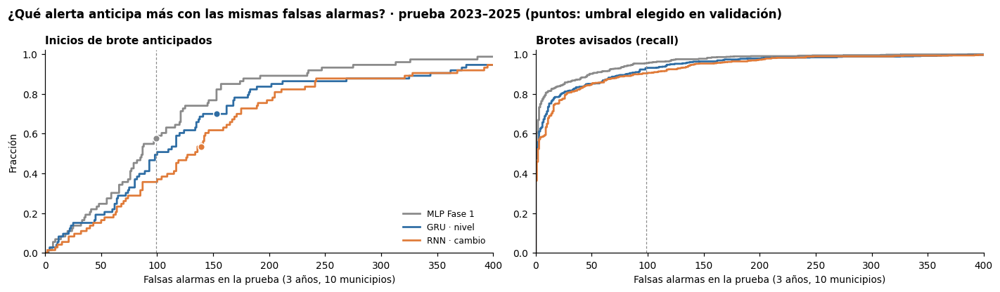

      modelo  falsas alarmas en su umbral inicios con ≤ 50 FA  recall con ≤ 50 FA inicios con ≤ 99 FA  recall con ≤ 99 FA inicios con ≤ 150 FA  recall con ≤ 150 FA
  MLP Fase 1                           99            18 de 73               0.900            42 de 73               0.954             56 de 73                0.976
 GRU · nivel                          153            14 de 73               0.851            36 de 73               0.929             51 de 73                0.963
RNN · cambio                          139            12 de 73               0.851            26 de 73               0.903             45 de 73                0.952


In [29]:
# Celda 26 · Comparación justa de las alertas: inicios anticipados con el mismo número de falsas alarmas
# Por qué: en la celda 24 la alerta de la GRU anticipó más inicios de brote que el MLP, pero también
#   dio más falsas alarmas. Con umbrales distintos no se sabe si es mejor o si solo avisa más.
# Qué hace: recorre TODOS los umbrales posibles de cada modelo en la prueba y dibuja cuántos inicios
#   anticipa (y cuántos brotes avisa) según cuántas falsas alarmas acepta. La curva más alta es mejor
#   a cualquier nivel de falsas alarmas. Luego lee las curvas en los puntos de operación de la celda 24.
# Es un diagnóstico sobre la prueba: no se usa para elegir umbrales ni modelos.
inicio24 = ((T24["brote_t"] == 0) & (T24["y"] == 1)).values
y24 = T24["y"].values
puntajes = {"MLP Fase 1": (pred_mlp_crono.loc[comunes].values, umbral_crono),
            f"{ELEGIDA} · nivel": (puntaje_alerta(modelos_b[(ELEGIDA, MEJOR_B[ELEGIDA])], D12["test"])
                                   [posicion.loc[comunes].values], cortes[ELEGIDA]),
            f"{mejor_cambio} · cambio": (p_test_c, corte_c)}


def curva_alerta(puntaje):
    """Para cada umbral (de mayor a menor): falsas alarmas acumuladas, recall e inicios anticipados."""
    orden = np.argsort(-puntaje, kind="stable")
    falsas = np.cumsum(y24[orden] == 0)
    recall = np.cumsum(y24[orden] == 1) / y24.sum()
    inicios = np.cumsum(inicio24[orden]) / inicio24.sum()
    return falsas, recall, inicios


COLOR_MODELO = dict(zip(puntajes, [GRIS, AZUL, NARANJA]))
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), sharex=True)
lecturas = []
for nombre, (p, corte) in puntajes.items():
    falsas, recall, inicios = curva_alerta(p)
    axes[0].plot(falsas, inicios, color=COLOR_MODELO[nombre], lw=1.8, label=nombre)
    axes[1].plot(falsas, recall, color=COLOR_MODELO[nombre], lw=1.8, label=nombre)
    fa_operacion = int(((p >= corte) & (y24 == 0)).sum())
    axes[0].scatter([fa_operacion], [((p >= corte) & inicio24).sum() / inicio24.sum()],
                    color=COLOR_MODELO[nombre], s=40, zorder=3, edgecolor="white")
    fila = {"modelo": nombre, "falsas alarmas en su umbral": fa_operacion}
    for limite in (50, 99, 150):
        k = np.searchsorted(falsas, limite, side="right") - 1          # último punto con ≤ límite falsas alarmas
        fila[f"inicios con ≤ {limite} FA"] = f"{int(round(inicios[k] * inicio24.sum()))} de {inicio24.sum()}"
        fila[f"recall con ≤ {limite} FA"] = round(float(recall[k]), 3)
    lecturas.append(fila)
for ax, titulo in zip(axes, ["Inicios de brote anticipados", "Brotes avisados (recall)"]):
    ax.set_xlim(0, 400); ax.set_ylim(0, 1.02); ax.set_xlabel("Falsas alarmas en la prueba (3 años, 10 municipios)")
    ax.axvline(99, color=GRIS, lw=0.8, ls=(0, (3, 2)))
    ax.set_title(titulo, loc="left")
axes[0].set_ylabel("Fracción"); axes[0].legend(frameon=False, fontsize=8, loc="lower right")
fig.suptitle("¿Qué alerta anticipa más con las mismas falsas alarmas? · prueba 2023–2025 (puntos: umbral elegido en validación)",
             x=0.01, ha="left", fontsize=11, fontweight="bold")
plt.tight_layout(); plt.show()
print(pd.DataFrame(lecturas).to_string(index=False))


**Lectura.** Con el mismo número de falsas alarmas, **el MLP anticipa más inicios en los tres puntos**: con hasta 50 falsas alarmas, 18 de 73 (GRU 14; RNN «cambio» 12); con hasta 99, 42 (36 y 26); con hasta 150, 56 (51 y 45). Su curva de *recall* también queda por encima. **Conclusión:** para la alerta de brote, el MLP de la Fase 1 sigue siendo el mejor modelo de la serie; la ventaja aparente de la GRU en la celda 24 venía de un umbral más permisivo. El aporte de la rama B es otro: **el pronóstico de cuántos casos habrá la semana siguiente** (gráfica 3 del cliente).

## 6. Rama A · La imagen satelital con una CNN preentrenada

La imagen entra a su arquitectura nativa: una red convolucional, que recorre la imagen con filtros compartidos y conserva su estructura espacial. Con solo 383 imágenes de entrenamiento no tiene sentido entrenar una CNN desde cero: se parte de redes preentrenadas en ImageNet (aprendizaje por transferencia) y se comparan dos modos, extracción de rasgos y ajuste fino.

**Tarea:** clasificar la zona del canal endémico de la semana siguiente (seguridad, alerta o brote) a partir de la imagen de la semana actual, con la partición por bloques de la celda 12 (383 / 83 / 85).

**Advertencias que dejó la sección 3:** clases muy desbalanceadas (76 % seguridad), Medellín concentra 39 de los 73 brotes y a simple vista no se ve una diferencia entre zonas. Por eso la CNN se compara con una línea base que solo conoce el municipio.

| Requisito de la actividad | Celdas |
| --- | --- |
| Dos redes preentrenadas (ResNet50 y EfficientNet-B0) | 29 |
| Extracción de rasgos frente a ajuste fino, con evidencia | 30 y 31 |
| Aumento de datos | 27 |
| Partición 70/15/15 | 12 |
| Métricas y matriz de confusión frente a líneas base | 28 y 32 |
| Grad-CAM | 33 |

Imágenes por conjunto: {'train': 383, 'val': 83, 'test': 85}
Entrenamiento por clase: {'seguridad': 290, 'alerta': 38, 'brote': 55} · pesos de la pérdida: {'seguridad': 0.44, 'alerta': 3.36, 'brote': 2.32}


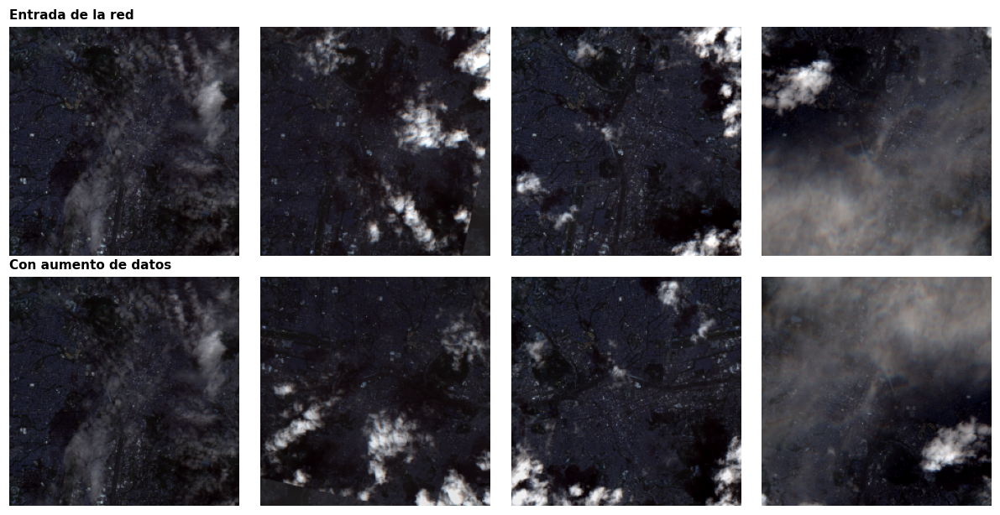

In [30]:
# Celda 27 · Rama A: las imágenes listas para la CNN (color, contraste, aumento de datos y pesos por clase) · bitácora E-21
# Qué hace:
#   1. Color: la red preentrenada recibe 3 canales. Se usa color verdadero (B04, B03, B02: rojo, verde,
#      azul), lo más parecido a las fotos de ImageNet con que se preentrenó (decisión del equipo). El
#      falso color infrarrojo (B08, B04, B03) se prueba una vez al final como sensibilidad (celda 31).
#   2. Contraste: las escenas son oscuras (valores bajos en 0–255). Se estira cada banda entre sus
#      percentiles 2 y 98, calculados SOLO con las imágenes de entrenamiento, y luego se normaliza con
#      la media y la desviación de ImageNet, como esperan las redes preentrenadas.
#   3. Aumento de datos (solo en entrenamiento, distinto en cada época): volteo horizontal, volteo
#      vertical, giro de 90°, 180° o 270° y brillo ±10 %. Una imagen satelital no tiene «arriba»: girada
#      o volteada sigue siendo una vista válida del mismo municipio. El brillo imita cambios de
#      atmósfera y de ángulo del sol. No se recorta (se perdería parte de la ciudad) ni se cambia el
#      color (el color es información).
#   4. Pesos por clase: hay 290 imágenes de seguridad, 55 de brote y 38 de alerta en entrenamiento. La
#      pérdida pesa cada clase en proporción inversa a su frecuencia; si no, a la red le basta con decir
#      siempre «seguridad» para acertar el 76 %.
# Requiere GPU: Entorno de ejecución → Cambiar tipo de entorno de ejecución → T4 GPU.
from torchvision import models
from sklearn.metrics import confusion_matrix, balanced_accuracy_score

PREENTRENADO = True                                        # pesos de ImageNet (torchvision)
if DEVICE == "cpu":
    print("AVISO: no hay GPU. La sección 6 en CPU puede tardar horas. Cambia el entorno a T4 GPU y vuelve a ejecutar.")

INDICES = {k: np.where(sel["conjunto"].values == k)[0] for k in ("train", "val", "test")}
Y_ZONA = torch.tensor(sel["y_zona"].astype(int).values)
COLORES = {"verdadero": [2, 1, 0], "falso": [3, 2, 1]}    # posiciones en (B02, B03, B04, B08)

LIMITES = {}
for nombre_c, bandas in COLORES.items():
    muestra = X_img[INDICES["train"]][:, bandas, ::4, ::4].astype("float32")
    LIMITES[nombre_c] = (torch.tensor(np.percentile(muestra, 2, axis=(0, 2, 3))).view(1, 3, 1, 1).float(),
                         torch.tensor(np.percentile(muestra, 98, axis=(0, 2, 3))).view(1, 3, 1, 1).float())
MEDIA_IMAGENET = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
DESV_IMAGENET = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)


def aumentar(x, generador):
    """Volteos, giros de 90° y brillo ±10 %, sorteados imagen por imagen."""
    salida = []
    for img in x:
        if torch.rand(1, generator=generador) < 0.5:
            img = img.flip(-1)
        if torch.rand(1, generator=generador) < 0.5:
            img = img.flip(-2)
        img = torch.rot90(img, int(torch.randint(0, 4, (1,), generator=generador)), dims=(-2, -1))
        img = img * (0.9 + 0.2 * torch.rand(1, generator=generador))
        salida.append(img.clamp(0, 1))
    return torch.stack(salida)


def lote_imagenes(indices, color="verdadero", generador=None, X=None):
    """Imágenes listas para la red. Con generador aplica el aumento de datos (solo entrenamiento).
    X: arreglo de imágenes de origen (por omisión, las 551 seleccionadas; la auditoría usa otro)."""
    X = X_img if X is None else X
    lo, hi = LIMITES[color]
    x = torch.from_numpy(X[np.asarray(indices)][:, COLORES[color]]).float()
    x = ((x - lo) / (hi - lo)).clamp(0, 1)
    if generador is not None:
        x = aumentar(x, generador)
    return ((x - MEDIA_IMAGENET) / DESV_IMAGENET).to(DEVICE)


conteo = np.bincount(Y_ZONA[INDICES["train"]].numpy(), minlength=3)
PESOS_CLASE = torch.tensor(len(INDICES["train"]) / (3 * conteo), dtype=torch.float32)
print("Imágenes por conjunto:", {k: len(v) for k, v in INDICES.items()})
print("Entrenamiento por clase:", dict(zip(ZONAS.values(), conteo.tolist())),
      "· pesos de la pérdida:", dict(zip(ZONAS.values(), [round(float(v), 2) for v in PESOS_CLASE])))

# Vista de control: 4 imágenes de entrenamiento tal como las ve la red, sin y con aumento
gen_demo = torch.Generator().manual_seed(SEMILLA)
demo = INDICES["train"][:4]
fig, axes = plt.subplots(2, 4, figsize=(11, 5.6))
for fila_ax, x in zip(axes, [lote_imagenes(demo), lote_imagenes(demo, generador=gen_demo)]):
    for ax, img in zip(fila_ax, (x.cpu() * DESV_IMAGENET + MEDIA_IMAGENET).clamp(0, 1)):
        ax.imshow(img.permute(1, 2, 0).numpy()); ax.axis("off")
axes[0, 0].set_title("Entrada de la red", loc="left"); axes[1, 0].set_title("Con aumento de datos", loc="left")
plt.tight_layout(); plt.show()


In [31]:
# Celda 28 · Líneas base de la rama A: lo que la CNN tiene que superar
# Qué hace: mide, en validación y prueba, tres referencias que NO miran la imagen:
#   · Clase mayoritaria: siempre «seguridad».
#   · Solo municipio: una regresión logística que solo sabe qué ciudad es (con los mismos pesos por
#     clase que la CNN). Responde la pregunta de la celda 11: si la CNN no la supera, lo que aprendió
#     de la imagen es básicamente «qué ciudad es».
#   · Persistencia de la zona: la zona de la semana siguiente será la de esta semana. Usa la serie de
#     casos, no la imagen; es lo que la vigilancia ya sabe sin satélite, y es la referencia que la
#     fusión (sección 7) tendrá que superar.
# Métricas: con clases desbalanceadas la exactitud engaña. La principal es el F1 macro (promedio del
#   F1 de las tres zonas, cada una pesa igual); también la exactitud balanceada (promedio del recall
#   de las tres zonas) y el recall de cada zona.
from sklearn.linear_model import LogisticRegression


def metricas_zona(y, pred):
    y, pred = np.asarray(y).astype(int), np.asarray(pred).astype(int)
    rec = recall_score(y, pred, labels=[0, 1, 2], average=None, zero_division=0)
    return {"exactitud": accuracy_score(y, pred),
            "F1 macro": f1_score(y, pred, labels=[0, 1, 2], average="macro", zero_division=0),
            "exactitud balanceada": rec.mean(),
            "recall seguridad": rec[0], "recall alerta": rec[1], "recall brote": rec[2]}


sel["zona_t"] = sel[["divipola", "anio", "semana"]].merge(
    datos[["divipola", "anio", "semana", "zona_t"]], on=["divipola", "anio", "semana"], how="left")["zona_t"].values
mun_img = pd.get_dummies(sel["municipio"], dtype=float).values
solo_municipio = LogisticRegression(class_weight="balanced", max_iter=1000).fit(
    mun_img[INDICES["train"]], sel["y_zona"].values[INDICES["train"]].astype(int))

filas_a = []
for k in ("val", "test"):
    y_k = sel["y_zona"].values[INDICES[k]]
    filas_a += [{"conjunto": k, "modelo": "Clase mayoritaria (seguridad)", **metricas_zona(y_k, np.zeros(len(y_k)))},
                {"conjunto": k, "modelo": "Solo municipio", **metricas_zona(y_k, solo_municipio.predict(mun_img[INDICES[k]]))},
                {"conjunto": k, "modelo": "Persistencia de la zona (serie)", **metricas_zona(y_k, sel["zona_t"].values[INDICES[k]])}]
lineas_base_a = pd.DataFrame(filas_a)
print(lineas_base_a.round(3).to_string(index=False))


conjunto                          modelo  exactitud  F1 macro  exactitud balanceada  recall seguridad  recall alerta  recall brote
     val   Clase mayoritaria (seguridad)      0.771     0.290                 0.333             1.000          0.000         0.000
     val                  Solo municipio      0.578     0.481                 0.603             0.547          0.833         0.429
     val Persistencia de la zona (serie)      0.928     0.859                 0.859             0.969          0.750         0.857
    test   Clase mayoritaria (seguridad)      0.753     0.286                 0.333             1.000          0.000         0.000
    test                  Solo municipio      0.518     0.453                 0.571             0.484          0.500         0.727
    test Persistencia de la zona (serie)      0.941     0.854                 0.864             0.984          0.700         0.909


**Lectura.** La clase mayoritaria acierta el 75 % en prueba, pero su F1 macro es 0,286: la exactitud no sirve con estas clases. **«Solo municipio» llega a un F1 macro de 0,481 en validación y 0,453 en prueba**: saber qué ciudad es ya da información, porque las zonas se reparten muy distinto entre municipios (celda 10). La persistencia de la zona, que usa la serie, es muy superior (0,859 y 0,854): la zona de esta semana predice muy bien la de la siguiente.

In [32]:
# Celda 29 · Las dos redes preentrenadas y los dos modos de aprendizaje por transferencia
# Redes (preentrenadas en ImageNet, de torchvision):
#   · ResNet50 (He et al., 2016): 50 capas con conexiones residuales; rasgos de 2.048 dimensiones.
#   · EfficientNet-B0 (Tan y Le, 2019): mucho más liviana (unos 4 millones de parámetros frente a 23);
#     rasgos de 1.280 dimensiones.
# A cada una se le quita su capa final de 1.000 clases y se le pone una cabeza nueva:
#   Dropout(0,3) → Linear(rasgos → 3 zonas).
# Modos:
#   · Extracción de rasgos (FE): toda la red preentrenada queda congelada; solo aprende la cabeza
#     (tasa 0,001). Es lo más seguro con pocas imágenes (383).
#   · Ajuste fino (FT): además se descongela el último tramo de la red (ResNet50: el bloque layer4;
#     EfficientNet-B0: las dos últimas etapas y la convolución final), con una tasa 10 veces menor
#     (0,0001) para no destruir lo aprendido en ImageNet. Las partes congeladas se mantienen en modo
#     evaluación (sus estadísticas de normalización no cambian).
# Entrenamiento: Adam, lote 32, pérdida de entropía cruzada con pesos por clase (celda 27), hasta
#   40 épocas con parada temprana (paciencia 8) sobre la pérdida de validación.
ZONAS_LISTA = list(ZONAS.values())


class ClasificadorZona(nn.Module):
    def __init__(self, red, n_rasgos, congelados, entrenables, capa_cam):
        super().__init__()
        self.red = red
        self.cabeza = nn.Sequential(nn.Dropout(0.3), nn.Linear(n_rasgos, 3))
        self.congelados, self.entrenables, self.capa_cam = congelados, entrenables, capa_cam

    def rasgos(self, x):
        """Vector de rasgos de la imagen: en la fusión (sección 7) es z_imagen."""
        return self.red(x)

    def forward(self, x):
        return self.cabeza(self.red(x))

    def modo_entrenamiento(self):
        self.train()
        for m in self.congelados:
            m.eval()


def construir(arquitectura, modo, semilla=SEMILLA):
    torch.manual_seed(semilla)
    if arquitectura == "ResNet50":
        red = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2 if PREENTRENADO else None)
        n_rasgos = red.fc.in_features
        red.fc = nn.Identity()
        ultimo = [red.layer4]
        resto = [red.conv1, red.bn1, red.layer1, red.layer2, red.layer3]
        capa_cam = red.layer4[-1]
    else:
        red = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1 if PREENTRENADO else None)
        n_rasgos = red.classifier[1].in_features
        red.classifier = nn.Identity()
        ultimo = [red.features[6:]]
        resto = [red.features[:6]]
        capa_cam = red.features[-1]
    for p in red.parameters():
        p.requires_grad = False
    if modo == "FT":
        for bloque in ultimo:
            for p in bloque.parameters():
                p.requires_grad = True
        congelados, entrenables = resto, ultimo
    else:
        congelados, entrenables = [red], []
    torch.manual_seed(semilla)
    return ClasificadorZona(red, n_rasgos, congelados, entrenables, capa_cam).to(DEVICE)


def logits_cnn(modelo, indices, color="verdadero", tam_lote=64, X=None):
    modelo.eval()
    with torch.no_grad():
        return torch.cat([modelo(lote_imagenes(indices[i:i + tam_lote], color, X=X)).cpu()
                          for i in range(0, len(indices), tam_lote)])


def entrenar_cnn(modelo, color="verdadero", epocas=40, paciencia=8, tam_lote=32, semilla=SEMILLA, datos_img=None):
    """datos_img (opcional, lo usa la auditoría): {"X", "indices", "y", "pesos"}; por omisión, las 551
    imágenes seleccionadas con su partición, sus etiquetas y sus pesos por clase."""
    d = datos_img or {"X": None, "indices": INDICES, "y": Y_ZONA, "pesos": PESOS_CLASE}
    grupos = [{"params": modelo.cabeza.parameters(), "lr": 1e-3}]
    if modelo.entrenables:
        grupos.append({"params": [p for b in modelo.entrenables for p in b.parameters()], "lr": 1e-4})
    optimizador = torch.optim.Adam(grupos)
    criterio = nn.CrossEntropyLoss(weight=d["pesos"].to(DEVICE))
    generador = torch.Generator().manual_seed(semilla)
    entrenamiento, y_val = d["indices"]["train"], d["y"][d["indices"]["val"]]
    hist = {"train": [], "val": [], "f1_val": []}
    mejor_val, mejor_estado, mejor_epoca = float("inf"), None, 0
    for epoca in range(1, epocas + 1):
        modelo.modo_entrenamiento()
        orden = entrenamiento[torch.randperm(len(entrenamiento), generator=generador).numpy()]
        suma = 0.0
        for i in range(0, len(orden), tam_lote):
            ids = orden[i:i + tam_lote]
            perdida = criterio(modelo(lote_imagenes(ids, color, generador, X=d["X"])), d["y"][ids].to(DEVICE))
            optimizador.zero_grad()
            perdida.backward()
            optimizador.step()
            suma += perdida.item() * len(ids)
        hist["train"].append(suma / len(orden))
        lv = logits_cnn(modelo, d["indices"]["val"], color, X=d["X"])
        hist["val"].append(nn.functional.cross_entropy(lv, y_val, weight=d["pesos"]).item())
        hist["f1_val"].append(f1_score(y_val.numpy(), lv.argmax(1).numpy(), average="macro", labels=[0, 1, 2],
                                       zero_division=0))
        if hist["val"][-1] < mejor_val:
            mejor_val, mejor_epoca = hist["val"][-1], epoca
            mejor_estado = {k: v.detach().clone() for k, v in modelo.state_dict().items()}
        elif epoca - mejor_epoca >= paciencia:
            break
    modelo.load_state_dict(mejor_estado)
    hist["mejor_epoca"] = mejor_epoca
    return hist


for arq in ("ResNet50", "EfficientNet-B0"):
    for modo in ("FE", "FT"):
        m = construir(arq, modo)
        total = sum(p.numel() for p in m.parameters())
        entrenables_n = sum(p.numel() for p in m.parameters() if p.requires_grad)
        print(f"{arq:15s} {modo}: {total:12,d} parámetros · entrenables {entrenables_n:12,d} "
              f"({entrenables_n / total:.1%})".replace(",", "."))
del m


Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:01<00:00, 101MB/s]


ResNet50        FE:   23.514.179 parámetros · entrenables        6.147 (0.0%)
ResNet50        FT:   23.514.179 parámetros · entrenables   14.970.883 (63.7%)
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 173MB/s]


EfficientNet-B0 FE:    4.011.391 parámetros · entrenables        3.843 (0.1%)
EfficientNet-B0 FT:    4.011.391 parámetros · entrenables    3.159.583 (78.8%)


ResNet50 FE: 18 épocas · F1 macro val 0.466 · 47 s
ResNet50 FT: 11 épocas · F1 macro val 0.382 · 28 s
EfficientNet-B0 FE: 25 épocas · F1 macro val 0.433 · 29 s
EfficientNet-B0 FT: 9 épocas · F1 macro val 0.359 · 13 s

Semilla 2026 · color verdadero
            red modo  épocas  mejor época  segundos  entrenables  F1 macro val  exactitud balanceada val  recall alerta val  recall brote val  F1 macro test  exactitud balanceada test  recall alerta test  recall brote test
       ResNet50   FE      18           10        47         6147         0.466                     0.555              0.500             0.571          0.392                      0.474                 0.3              0.636
       ResNet50   FT      11            3        28     14970883         0.382                     0.410              0.083             0.429          0.409                      0.430                 0.1              0.455
EfficientNet-B0   FE      25           17        29         3843         0.433    

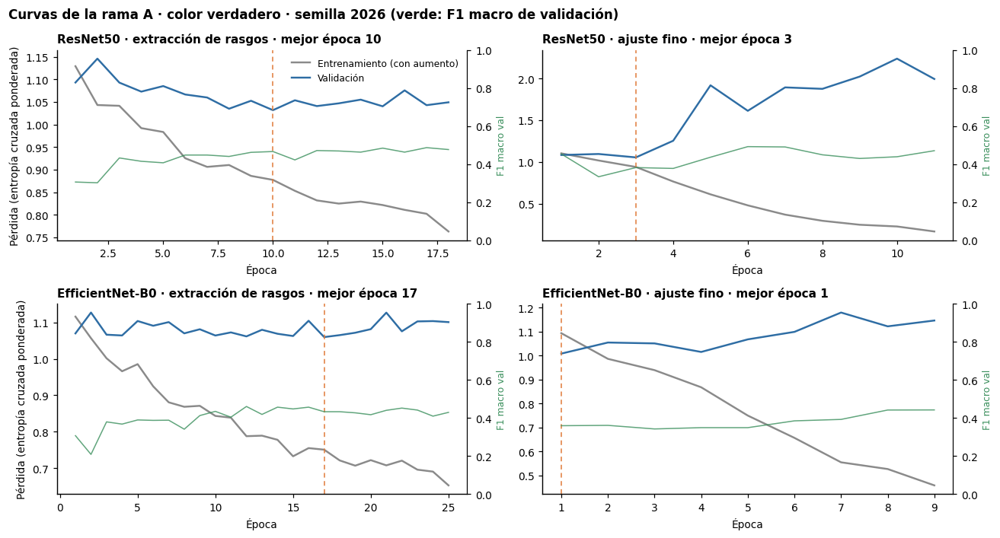


Ganador por F1 macro de validación: ResNet50 · FE · pesos guardados en /content/centinela_fase2/pesos/


In [33]:
# Celda 30 · Extracción de rasgos frente a ajuste fino, en las dos redes (4 entrenamientos)
# Qué hace: entrena ResNet50 y EfficientNet-B0 en los dos modos (semilla 2026, color verdadero) y
#   compara curvas, métricas, parámetros entrenables y tiempo. El ganador se elige con el F1 macro de
#   VALIDACIÓN; la prueba solo se informa.
# Evidencia que se busca: si el ajuste fino aporta (mejor F1 de validación) o si sobreajusta (la
#   pérdida de entrenamiento baja mucho y la de validación sube), algo esperable con 383 imágenes.
# Tiempo estimado con GPU T4: 5 a 10 minutos.
os.makedirs(f"{CARPETA}/pesos", exist_ok=True)
CONFIGS = [(a, m) for a in ("ResNet50", "EfficientNet-B0") for m in ("FE", "FT")]
modelos_a, historias_a, filas_cnn = {}, {}, []
for arq, modo in CONFIGS:
    inicio = time.time()
    modelo_a = construir(arq, modo)
    h = entrenar_cnn(modelo_a)
    fila = {"red": arq, "modo": modo, "épocas": len(h["val"]), "mejor época": h["mejor_epoca"],
            "segundos": round(time.time() - inicio),
            "entrenables": sum(p.numel() for p in modelo_a.parameters() if p.requires_grad)}
    for k in ("val", "test"):
        pred = logits_cnn(modelo_a, INDICES[k]).argmax(1).numpy()
        fila.update({f"{n} {k}": v for n, v in metricas_zona(Y_ZONA[INDICES[k]].numpy(), pred).items()
                     if n in ("F1 macro", "exactitud balanceada", "recall alerta", "recall brote")})
    modelos_a[(arq, modo)], historias_a[(arq, modo)] = modelo_a, h
    filas_cnn.append(fila)
    print(f"{arq} {modo}: {fila['épocas']} épocas · F1 macro val {fila['F1 macro val']:.3f} · {fila['segundos']} s")
res_cnn = pd.DataFrame(filas_cnn)
print("\nSemilla 2026 · color verdadero")
print(res_cnn.round(3).to_string(index=False))
print("\nReferencias (celda 28):")
print(lineas_base_a[["conjunto", "modelo", "F1 macro", "exactitud balanceada", "recall alerta", "recall brote"]]
      .round(3).to_string(index=False))

fig, axes = plt.subplots(2, 2, figsize=(12, 6.5))   # cada panel con su escala: FE y FT tienen pérdidas muy distintas
for ax, (arq, modo) in zip(axes.ravel(), CONFIGS):
    h = historias_a[(arq, modo)]
    ep = np.arange(1, len(h["train"]) + 1)
    ax.plot(ep, h["train"], color=GRIS, lw=1.6, label="Entrenamiento (con aumento)")
    ax.plot(ep, h["val"], color=AZUL, lw=1.6, label="Validación")
    ax.axvline(h["mejor_epoca"], color=NARANJA, lw=1, ls=(0, (4, 3)))
    ax2 = ax.twinx(); ax2.plot(ep, h["f1_val"], color=VERDE, lw=1, alpha=0.8); ax2.set_ylim(0, 1)
    ax2.set_ylabel("F1 macro val", color=VERDE, fontsize=8); ax2.spines["right"].set_visible(True)
    ax.set_title(f"{arq} · {'extracción de rasgos' if modo == 'FE' else 'ajuste fino'} · mejor época {h['mejor_epoca']}",
                 loc="left")
    ax.set_xlabel("Época")
axes[0, 0].set_ylabel("Pérdida (entropía cruzada ponderada)"); axes[1, 0].set_ylabel("Pérdida (entropía cruzada ponderada)")
axes[0, 0].legend(frameon=False, fontsize=8)
fig.suptitle("Curvas de la rama A · color verdadero · semilla 2026 (verde: F1 macro de validación)", x=0.01, ha="left",
             fontsize=11, fontweight="bold")
plt.tight_layout(); plt.show()

GANADOR = tuple(res_cnn.sort_values(["F1 macro val", "exactitud balanceada val"], ascending=False)
                .iloc[0][["red", "modo"]])
for (arq, modo), modelo_a in modelos_a.items():
    torch.save({"estado": modelo_a.state_dict(), "config": {"red": arq, "modo": modo, "color": "verdadero",
                "semilla": SEMILLA, "clases": ZONAS_LISTA, "particion": "bloques de 4 semanas, celda 12"}},
               f"{CARPETA}/pesos/rama_a_{arq.lower().replace('-', '')}_{modo.lower()}.pth")
print(f"\nGanador por F1 macro de validación: {GANADOR[0]} · {GANADOR[1]} · pesos guardados en {CARPETA}/pesos/")


**Lectura.** (1) **La extracción de rasgos supera al ajuste fino en las dos redes** (F1 macro de validación): ResNet50, 0,466 frente a 0,382; EfficientNet-B0, 0,433 frente a 0,359. (2) Las curvas muestran por qué: en ajuste fino, la pérdida de entrenamiento de ResNet50 cae hasta cerca de 0,17 mientras la de validación sube desde la época 3 (de 1,05 a más de 2); la parada temprana se queda con las épocas 3 (ResNet50) y 1 (EfficientNet-B0), casi sin ajuste. Con 383 imágenes, mover 15 millones de parámetros (ResNet50) o 3,2 millones (EfficientNet-B0) **sobreajusta**; entrenar solo la cabeza (6.147 y 3.843 parámetros) es lo prudente. En extracción de rasgos, la pérdida de validación baja poco y se estabiliza, sin dispararse. (3) Ninguna configuración supera con claridad a «Solo municipio» (0,481 en validación). (4) Los pesos por clase funcionan: el ganador tiene *recall* de 0,50 en alerta y 0,57 en brote en validación, en lugar de refugiarse en «seguridad». **Ganador por validación: ResNet50 con extracción de rasgos.**

In [34]:
# Celda 31 · ¿El resultado del ganador es estable? Dos semillas más y la prueba de falso color · bitácora E-21
# Qué hace:
#   1. Repite el ganador de la celda 30 con las semillas 2027 y 2028 (cambian la cabeza inicial, el
#      orden de los lotes y el aumento de datos). Con 7 brotes y 12 alertas en validación, un solo
#      entrenamiento puede ser suerte: la media y la desviación de 3 semillas dan la cifra honesta.
#   2. Entrena el ganador (semilla 2026) con falso color infrarrojo (B08, B04, B03): el infrarrojo
#      cercano resalta la vegetación y el agua, que tienen que ver con el hábitat del mosquito.
# Tiempo estimado con GPU T4: 3 a 6 minutos.
filas_est = []
for s in SEMILLAS:
    if s == SEMILLA:
        modelo_s = modelos_a[GANADOR]
    else:
        modelo_s = construir(*GANADOR, semilla=s)
        entrenar_cnn(modelo_s, semilla=s)
    fila = {"semilla": s}
    for k in ("val", "test"):
        pred = logits_cnn(modelo_s, INDICES[k]).argmax(1).numpy()
        fila.update({f"{n} {k}": v for n, v in metricas_zona(Y_ZONA[INDICES[k]].numpy(), pred).items()
                     if n in ("F1 macro", "exactitud balanceada")})
    filas_est.append(fila)
estabilidad = pd.DataFrame(filas_est)
print(f"{GANADOR[0]} · {GANADOR[1]} · color verdadero · 3 semillas")
print(estabilidad.round(3).to_string(index=False))
print("Media ± desviación:", " · ".join(f"{c} {estabilidad[c].mean():.3f} ± {estabilidad[c].std():.3f}"
                                         for c in estabilidad.columns if c != "semilla"))

modelo_falso = construir(*GANADOR)
h_falso = entrenar_cnn(modelo_falso, color="falso")
filas_color = []
for nombre_c, modelo_c in [("verdadero", modelos_a[GANADOR]), ("falso", modelo_falso)]:
    fila = {"color": nombre_c}
    for k in ("val", "test"):
        pred = logits_cnn(modelo_c, INDICES[k], nombre_c).argmax(1).numpy()
        fila.update({f"{n} {k}": v for n, v in metricas_zona(Y_ZONA[INDICES[k]].numpy(), pred).items()
                     if n in ("F1 macro", "exactitud balanceada", "recall alerta", "recall brote")})
    filas_color.append(fila)
print(f"\n{GANADOR[0]} · {GANADOR[1]} · semilla 2026 · color verdadero frente a falso color infrarrojo")
print(pd.DataFrame(filas_color).round(3).to_string(index=False))
diferencia_color = filas_color[1]["F1 macro val"] - filas_color[0]["F1 macro val"]
print(f"Diferencia en F1 macro de validación (falso − verdadero): {diferencia_color:+.3f} · "
      f"desviación entre semillas: {estabilidad['F1 macro val'].std():.3f}")


ResNet50 · FE · color verdadero · 3 semillas
 semilla  F1 macro val  exactitud balanceada val  F1 macro test  exactitud balanceada test
    2026         0.466                     0.555          0.392                      0.474
    2027         0.452                     0.500          0.397                      0.427
    2028         0.553                     0.619          0.453                      0.530
Media ± desviación: F1 macro val 0.490 ± 0.055 · exactitud balanceada val 0.558 ± 0.059 · F1 macro test 0.414 ± 0.034 · exactitud balanceada test 0.477 ± 0.052

ResNet50 · FE · semilla 2026 · color verdadero frente a falso color infrarrojo
    color  F1 macro val  exactitud balanceada val  recall alerta val  recall brote val  F1 macro test  exactitud balanceada test  recall alerta test  recall brote test
verdadero         0.466                     0.555              0.500             0.571          0.392                      0.474                 0.3              0.636
    falso      

**Lectura.** Con 3 semillas, el ganador da un F1 macro de **0,490 ± 0,055 en validación y 0,414 ± 0,034 en prueba**. La desviación (0,055) es del tamaño de varias diferencias de la celda 30: la ventaja de ResNet50 sobre EfficientNet-B0 en extracción de rasgos (0,033) no es concluyente; la de extracción de rasgos sobre ajuste fino en ResNet50 (0,084) sí lo es. El falso color queda 0,030 por debajo en validación, dentro de la variación: **no se adopta**. En prueba sale mejor (0,480; *recall* de brote 0,818), pero la prueba no se usa para elegir; queda como pista para la Fase 3.

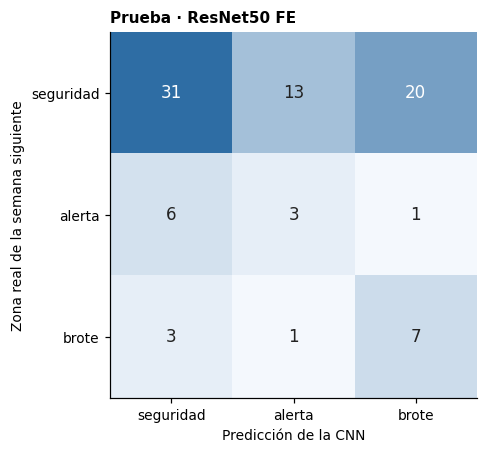

Prueba · 85 imágenes: {'seguridad': 64, 'alerta': 10, 'brote': 11}
                         modelo  exactitud  F1 macro  exactitud balanceada  recall seguridad  recall alerta  recall brote
  Clase mayoritaria (seguridad)      0.753     0.286                 0.333             1.000            0.0         0.000
                 Solo municipio      0.518     0.453                 0.571             0.484            0.5         0.727
Persistencia de la zona (serie)      0.941     0.854                 0.864             0.984            0.7         0.909
                CNN ResNet50 FE      0.482     0.392                 0.474             0.484            0.3         0.636

La CNN coincide con «solo municipio» en 65% de las imágenes de prueba.
Errores de la CNN en prueba por municipio: {'Medellín': 12, 'Villavicencio': 7, 'Bucaramanga': 4, 'Neiva': 4, 'Cúcuta': 4, 'Cali': 4, 'Itagüí': 3, 'Montería': 3, 'Barranquilla': 2, 'Ibagué': 1}
Rasgos de imagen guardados: (551, 2048) → /content/centin

In [35]:
# Celda 32 · Evaluación final de la rama A en la prueba (una sola vez) y rasgos para la fusión
# Qué hace:
#   1. Matriz de confusión del ganador (semilla 2026, color verdadero) en las 85 imágenes de prueba.
#   2. Tabla en prueba: ganador frente a las tres líneas base de la celda 28.
#   3. ¿La CNN aprendió «qué ciudad es»? Mide cuántas veces su predicción coincide con la del modelo
#      que solo conoce el municipio.
#   4. Guarda el vector de rasgos de cada imagen (z_imagen) para la fusión (sección 7). La red no vio
#      las imágenes de validación ni de prueba al entrenar, así que sus rasgos no tienen fuga.
import matplotlib
modelo_final_a = modelos_a[GANADOR]
y_test_a = Y_ZONA[INDICES["test"]].numpy()
prob_test_a = torch.softmax(logits_cnn(modelo_final_a, INDICES["test"]), 1).numpy()
pred_test_a = prob_test_a.argmax(1)

cm = confusion_matrix(y_test_a, pred_test_a, labels=[0, 1, 2])
fig, ax = plt.subplots(figsize=(4.8, 4.2))
ax.imshow(cm, cmap=matplotlib.colors.LinearSegmentedColormap.from_list("azules", ["#f4f8fd", AZUL]))
for i in range(3):
    for j in range(3):
        ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=11,
                color="white" if cm[i, j] > cm.max() / 2 else "#222222")
ax.set_xticks(range(3), ZONAS_LISTA); ax.set_yticks(range(3), ZONAS_LISTA)
ax.set_xlabel("Predicción de la CNN"); ax.set_ylabel("Zona real de la semana siguiente"); ax.grid(False)
ax.set_title(f"Prueba · {GANADOR[0]} {GANADOR[1]}", loc="left")
plt.tight_layout(); plt.show()

pred_municipio = solo_municipio.predict(mun_img[INDICES["test"]])
tabla_a = pd.DataFrame(
    [{"modelo": r["modelo"], **{c: r[c] for c in metricas_zona(y_test_a, pred_test_a)}}
     for _, r in lineas_base_a[lineas_base_a["conjunto"] == "test"].iterrows()]
    + [{"modelo": f"CNN {GANADOR[0]} {GANADOR[1]}", **metricas_zona(y_test_a, pred_test_a)}])
print(f"Prueba · {len(y_test_a)} imágenes:", dict(zip(ZONAS_LISTA, np.bincount(y_test_a, minlength=3).tolist())))
print(tabla_a.round(3).to_string(index=False))
print(f"\nLa CNN coincide con «solo municipio» en {np.mean(pred_test_a == pred_municipio):.0%} de las imágenes de prueba.")
errores = sel.iloc[INDICES["test"]].assign(pred=pred_test_a)
errores = errores[errores["pred"] != errores["y_zona"]]
print("Errores de la CNN en prueba por municipio:", errores["municipio"].value_counts().to_dict())

# Rasgos de todas las imágenes (train, val y test) con el ganador, para la fusión
modelo_final_a.eval()
with torch.no_grad():
    RASGOS_IMG = torch.cat([modelo_final_a.rasgos(lote_imagenes(np.arange(len(sel))[i:i + 64])).cpu()
                            for i in range(0, len(sel), 64)]).numpy()
np.savez_compressed(f"{CARPETA}/rasgos_imagen.npz", rasgos=RASGOS_IMG,
                    divipola=sel["divipola"].values, anio=sel["anio"].values, semana=sel["semana"].values,
                    conjunto=sel["conjunto"].values)
print(f"Rasgos de imagen guardados: {RASGOS_IMG.shape} → {CARPETA}/rasgos_imagen.npz")


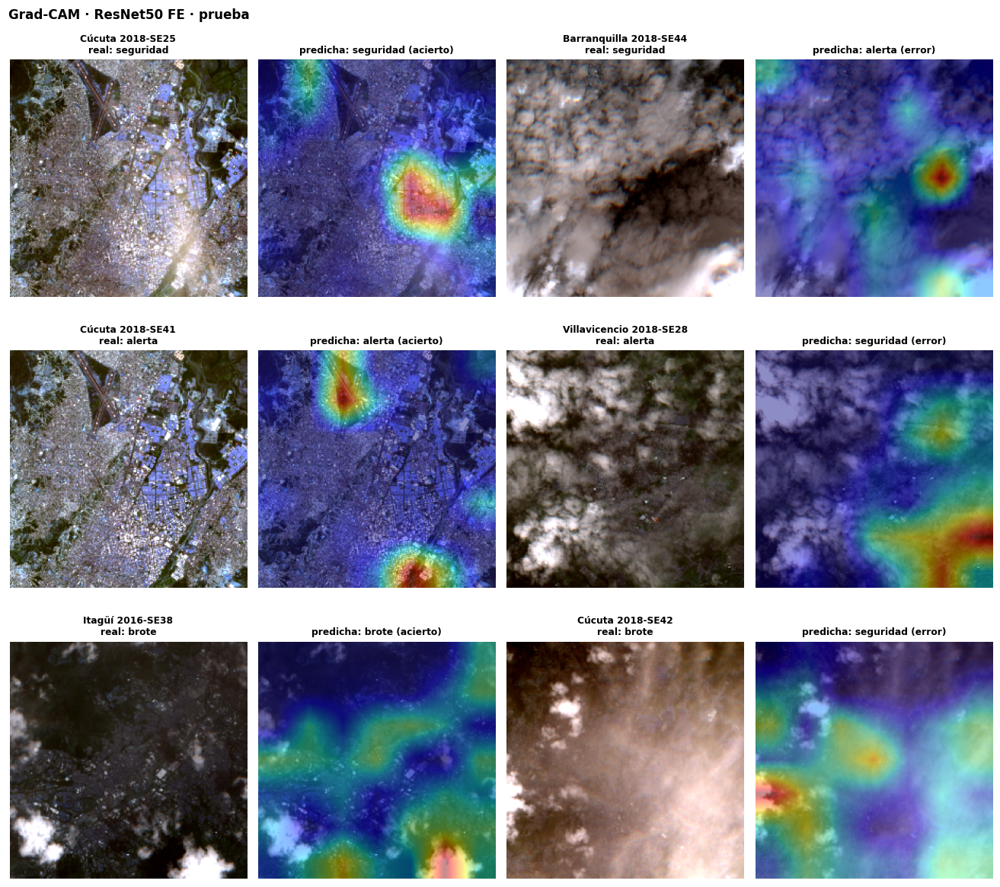

Fracción media del Grad-CAM en el cuadrado central de la escena (25 % del área): 29% · si el mapa fuera uniforme sería 25 %; mucho menos indicaría que la red mira los bordes.


In [36]:
# Celda 33 · Grad-CAM: ¿en qué parte de la imagen se fija la CNN?
# Qué hace: para imágenes de prueba, calcula el mapa Grad-CAM (Selvaraju et al., 2017) de la clase
#   predicha: toma los mapas de activación de la última capa convolucional, los pondera por el
#   gradiente promedio de la clase predicha respecto a cada mapa y se queda con la parte positiva.
#   Las zonas rojas son las que más empujan la decisión.
# Se muestran 2 imágenes por zona real (una acertada y una errada cuando existen), en color verdadero.
# Pregunta que responde: ¿la red mira la ciudad y su entorno (vegetación, agua, zonas urbanas) o
#   mira nubes, bordes y franjas sin datos? Lo segundo sería una señal de que aprendió atajos.
def grad_cam(modelo, indice, color="verdadero"):
    modelo.eval()
    guardado = {}
    gancho = modelo.capa_cam.register_forward_hook(lambda m, entrada, salida: guardado.update(a=salida))
    x = lote_imagenes([indice], color).requires_grad_(True)    # para que el gradiente llegue a la capa congelada
    logits = modelo(x)
    clase = int(logits.argmax(1))
    grad = torch.autograd.grad(logits[0, clase], guardado["a"])[0]
    gancho.remove()
    pesos = grad.mean(dim=(2, 3), keepdim=True)
    mapa = torch.relu((pesos * guardado["a"]).sum(1, keepdim=True))
    mapa = nn.functional.interpolate(mapa, size=x.shape[-2:], mode="bilinear", align_corners=False)[0, 0]
    mapa = (mapa / (mapa.max() + 1e-8)).detach().cpu().numpy()
    return mapa, clase


prueba_a = sel.iloc[INDICES["test"]].assign(pred=pred_test_a, indice=INDICES["test"])
elegidas = []
for zona in ZONAS:
    grupo = prueba_a[prueba_a["y_zona"] == zona]
    for acierto in (True, False):
        candidatas = grupo[(grupo["pred"] == grupo["y_zona"]) == acierto]
        if len(candidatas):
            elegidas.append(candidatas.sample(1, random_state=SEMILLA).iloc[0])
n_filas = (len(elegidas) + 1) // 2
fig, axes = plt.subplots(n_filas, 4, figsize=(12, 3.7 * n_filas))
axes = np.atleast_2d(axes)
for ax in axes.ravel():
    ax.axis("off")
for k, f in enumerate(elegidas):
    mapa, clase = grad_cam(modelo_final_a, int(f["indice"]))
    imagen = color_verdadero(X_img[int(f["indice"])])
    ax_img, ax_cam = axes[k // 2, 2 * (k % 2)], axes[k // 2, 2 * (k % 2) + 1]
    ax_img.imshow(imagen)
    ax_img.set_title(f"{f['municipio']} {f['anio']}-SE{f['semana']:02d}\nreal: {ZONAS[int(f['y_zona'])]}", fontsize=8)
    ax_cam.imshow(imagen); ax_cam.imshow(mapa, cmap="jet", alpha=0.45)
    ax_cam.set_title(f"predicha: {ZONAS[clase]} ({'acierto' if clase == f['y_zona'] else 'error'})", fontsize=8)
fig.suptitle(f"Grad-CAM · {GANADOR[0]} {GANADOR[1]} · prueba", x=0.01, ha="left", fontsize=11, fontweight="bold")
plt.tight_layout(); plt.show()

# Resumen numérico: ¿la red mira el centro de la escena o los bordes? Las franjas sin datos del borde
# de la pasada del satélite y muchos recortes de nubes aparecen en los bordes: si el mapa se
# concentrara ahí, sería una señal de atajo.
centro = np.zeros((X_img.shape[-2], X_img.shape[-1]), bool)
c0, c1 = X_img.shape[-2] // 4, 3 * X_img.shape[-2] // 4
centro[c0:c1, c0:c1] = True
mapas_prueba = [grad_cam(modelo_final_a, int(i))[0] for i in INDICES["test"]]
fraccion_centro = np.array([m[centro].sum() / (m.sum() + 1e-8) for m in mapas_prueba])
print(f"Fracción media del Grad-CAM en el cuadrado central de la escena (25 % del área): {fraccion_centro.mean():.0%} "
      f"· si el mapa fuera uniforme sería 25 %; mucho menos indicaría que la red mira los bordes.")


**Lectura de la evaluación final (celda 32).** En las 85 imágenes de prueba, la CNN logra un F1 macro de 0,392 y una exactitud balanceada de 0,474: reconoce 7 de 11 brotes y 3 de 10 alertas, pero marca como brote 20 de las 64 semanas de seguridad. **No supera a «Solo municipio» (0,453) y coincide con él en el 65 % de las predicciones**: en la práctica, lo que la red aprendió de la imagen es sobre todo qué ciudad es. Los errores se concentran en Medellín (12), el municipio con más imágenes y más brotes.

**Lectura del Grad-CAM (celda 33).** En escenas despejadas, la red se fija en zonas urbanas (en Cúcuta, el centro y el área del aeropuerto); en escenas nubladas o con bruma se fija en nubes y bordes, un atajo sin relación con el dengue. El 29 % del mapa cae en el cuadrado central (sería 25 % si fuera uniforme): no se concentra en los bordes, pero tampoco en el casco urbano. Un detalle revelador: las escenas de Cúcuta de las semanas 25 y 41 de 2018 se ven casi iguales y tienen zonas distintas (seguridad y alerta). La ciudad vista desde el satélite no cambia al ritmo de la epidemia; además, esas dos escenas pasaron el filtro de repetidas (diferencia media ≥ 1), lo que sugiere que quedan repeticiones no detectadas (limitación).

**Conclusión de la rama A:** con 551 imágenes de tres años, una por semana y municipio, la imagen satelital no permite distinguir la zona de la semana siguiente mejor que saber el municipio.

## 7. Rama C · Fusión de imagen y serie, con ablación

La fusión responde la pregunta central del sistema: **¿anticipa mejor un brote quien ve la imagen satelital y además recuerda la serie de casos y clima?** Se usa fusión tardía: cada rama produce su representación (*embedding*), se concatenan y una cabeza densa pequeña decide.

$$\hat{y} = \sigma\left(W_{2}\,\mathrm{ReLU}\left(W_{1}\,[\,z_{imagen} \Vert z_{serie}\,] + b_1\right) + b_2\right)$$

| Paso de la actividad | Celda |
| --- | --- |
| 1 · Clave de alineación real por muestra, sin fuga | 34 |
| 2 · Modelo fusionado (ramas A y B como extractores, cabeza densa, regularización) | 35 |
| 3 · Ablación: solo imagen, solo serie y fusión, en las mismas semanas | 35 y 36 |
| Análisis honesto: incertidumbre y cuándo aporta cada modalidad | 36 y 37 |

**Criterio de honestidad (de la actividad):** si la fusión no supera a la mejor rama sola, también es un hallazgo válido y se explica por qué.

In [37]:
# Celda 34 · Rama C (1/4): alineación de las dos modalidades y representaciones de cada rama
# Clave de alineación: (código DIVIPOLA del municipio que muestra la imagen según su georreferencia,
#   año y semana epidemiológica). Es un co-registro real por muestra: la imagen de la semana t y la
#   ventana de la serie que termina en la semana t del MISMO municipio. Ambas predicen la semana t + 1.
#   No hay pareo artificial: la celda 8 descartó las escenas que estaban en la carpeta equivocada.
# Representaciones (embeddings):
#   · z_imagen: los 2.048 rasgos de la ResNet50 ganadora (celda 32), reducidos a 32 componentes
#     principales (PCA ajustado SOLO con entrenamiento). Con 383 muestras, 2.048 entradas sobreajustan.
#   · z_serie: el estado oculto (64) de la red recurrente elegida en la celda 25, más sus variables
#     estáticas (umbral del canal de t + 1 y municipio).
# Sin fuga de información: la red recurrente de la celda 25 se entrenó con 2012–2019, que incluye las
#   semanas de prueba de las imágenes (2016–2018). Por eso aquí se vuelve a entrenar la MISMA
#   arquitectura con la partición por bloques: semanas que predicen 2012–2015 + bloques de
#   entrenamiento de 2016–2018 (las 10 series), validación con los bloques de validación. Igual que la
#   CNN, que se preentrenó con ImageNet, esta rama se preentrena con toda la serie disponible sin tocar
#   las semanas de validación ni de prueba.
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

clave = ["divipola", "anio", "semana"]
fila_de = pd.Series(datos.index, index=pd.MultiIndex.from_frame(datos[clave]))
filas_img = fila_de.loc[pd.MultiIndex.from_frame(sel[clave])].values      # fila de `datos` de cada imagen
assert len(filas_img) == len(sel)

# Objetivo de la rama B elegida, normalizado SOLO con las semanas de entrenamiento de esta partición
pre_img = datos["anio_obj"].between(2012, 2015) & datos["conjunto_bloque"].isna()
conj_f = pd.Series(np.where(pre_img, "train", datos["conjunto_bloque"]), index=datos.index)
con_obj = datos["y_inc"].notna() & datos["q3_t1"].notna()
bruto = (np.log1p(datos["y_inc"]) - datos["log_inc"]) if OBJETIVO_B == "cambio" else np.log1p(datos["y_inc"])
media_f, desv_f = bruto[con_obj & (conj_f == "train")].mean(), bruto[con_obj & (conj_f == "train")].std()
OBJ_F = ((bruto - media_f) / desv_f).to_numpy(np.float32)

D_fusion = {}
for k in ("train", "val", "test"):
    filas, X = ventanas(VENTANA, datos.index[con_obj & (conj_f == k)])
    D_fusion[k] = {"filas": filas, "X": torch.tensor(X), "S": torch.tensor(MATRIZ_ESTATICAS[filas]),
                   "y": torch.tensor(OBJ_F[filas]).view(-1, 1)}
    print(f"Serie para la rama C · {k:5s}: {len(filas)} semanas (10 municipios)")
torch.manual_seed(SEMILLA)
codificador = Recurrente(ELEGIDA_B, len(PASO), len(ESTATICAS))
h_cod = entrenar_rec(codificador, D_fusion)
print(f"Codificador de la serie: {ELEGIDA_B} · objetivo «{OBJETIVO_B}» · mejor época {h_cod['mejor_epoca']}")

# z_serie de cada imagen (la ventana de 12 semanas que termina en su semana)
filas_ok, X_img_serie = ventanas(VENTANA, filas_img)
assert len(filas_ok) == len(filas_img), "Alguna imagen no tiene su ventana completa de la serie"
codificador.eval()
with torch.no_grad():
    H_SERIE = codificador.codificar(torch.tensor(X_img_serie)).numpy()
Z_SERIE = np.hstack([H_SERIE, MATRIZ_ESTATICAS[filas_img]])

# z_imagen: PCA de 32 componentes ajustado con las imágenes de entrenamiento
pca = PCA(n_components=32, random_state=SEMILLA).fit(RASGOS_IMG[INDICES["train"]])
Z_IMAGEN = pca.transform(RASGOS_IMG)
print(f"PCA de los rasgos de imagen: 32 componentes explican el {pca.explained_variance_ratio_.sum():.0%} "
      "de la varianza en entrenamiento")

Y_BROTE = sel["y_brote"].astype(int).values
BROTE_T_IMG = datos.loc[filas_img, "brote_t"].astype(int).values
for k, idx in INDICES.items():
    print(f"Rama C · {k:5s}: {len(idx)} muestras · brotes en t + 1: {Y_BROTE[idx].sum()}")
torch.save({"estado": codificador.state_dict(), "config": {"tipo": ELEGIDA_B, "objetivo": OBJETIVO_B,
            "ventana": VENTANA, "particion": "objetivo 2012-2015 + bloques train; val = bloques val"}},
           f"{CARPETA}/pesos/rama_c_codificador_serie.pth")


Serie para la rama C · train: 3170 semanas (10 municipios)
Serie para la rama C · val  : 240 semanas (10 municipios)
Serie para la rama C · test : 240 semanas (10 municipios)
Codificador de la serie: RNN · objetivo «cambio» · mejor época 9
PCA de los rasgos de imagen: 32 componentes explican el 82% de la varianza en entrenamiento
Rama C · train: 383 muestras · brotes en t + 1: 55
Rama C · val  : 83 muestras · brotes en t + 1: 7
Rama C · test : 85 muestras · brotes en t + 1: 11


In [38]:
# Celda 35 · Rama C (2/4): fusión tardía y ablación (solo imagen · solo serie · fusión)
# Qué hace: entrena tres cabezas densas IDÉNTICAS que solo difieren en lo que reciben:
#   · Solo imagen: z_imagen (32)
#   · Solo serie: z_serie (64 + 11)
#   · Fusión: [z_imagen ‖ z_serie] (concatenación, fusión tardía)
#   Cabeza: Linear(entrada → 32) → ReLU → Dropout(0,3) → Linear(32 → 1), salida en logit.
#   Objetivo: brote en t + 1 (la etiqueta de la Fase 1). Las tres usan las mismas 383 muestras de
#   entrenamiento, las mismas 83 de validación y las mismas 85 de prueba.
# Entrenamiento: Adam (tasa 0,001, decaimiento de pesos 0,0001), lote 32, entropía cruzada binaria con
#   peso para la clase brote (hay 1 brote por cada 6 semanas sin brote en entrenamiento), hasta 300
#   épocas con parada temprana (paciencia 30) sobre la pérdida de validación. Las entradas se
#   estandarizan con la media y la desviación de entrenamiento.
# Como la validación tiene solo 7 brotes, cada configuración se entrena con 5 semillas y se reporta
#   el promedio de sus probabilidades (y la variación entre semillas en la celda 36).
# Tiempo estimado: 1 a 2 minutos.
ENTRADAS = {"Solo imagen": Z_IMAGEN, "Solo serie": Z_SERIE, "Fusión": np.hstack([Z_IMAGEN, Z_SERIE])}
SEMILLAS_C = [SEMILLA + i for i in range(5)]


class CabezaFusion(nn.Module):
    def __init__(self, d):
        super().__init__()
        self.red = nn.Sequential(nn.Linear(d, 32), nn.ReLU(), nn.Dropout(0.3), nn.Linear(32, 1))

    def forward(self, z):
        return self.red(z)


def entrenar_cabeza(Z, semilla, epocas=300, paciencia=30, tam_lote=32):
    escala = StandardScaler().fit(Z[INDICES["train"]])
    T = {k: torch.tensor(escala.transform(Z[idx]), dtype=torch.float32) for k, idx in INDICES.items()}
    Yt = {k: torch.tensor(Y_BROTE[idx], dtype=torch.float32).view(-1, 1) for k, idx in INDICES.items()}
    torch.manual_seed(semilla)
    cabeza = CabezaFusion(Z.shape[1])
    peso_pos = ((Yt["train"] == 0).sum() / (Yt["train"] == 1).sum()).float()
    criterio = nn.BCEWithLogitsLoss(pos_weight=peso_pos)
    optimizador = torch.optim.Adam(cabeza.parameters(), lr=1e-3, weight_decay=1e-4)
    generador = torch.Generator().manual_seed(semilla)
    mejor_val, mejor_estado, mejor_epoca = float("inf"), None, 0
    for epoca in range(1, epocas + 1):
        cabeza.train()
        orden = torch.randperm(len(T["train"]), generator=generador)
        for i in range(0, len(orden), tam_lote):
            idx = orden[i:i + tam_lote]
            perdida = criterio(cabeza(T["train"][idx]), Yt["train"][idx])
            optimizador.zero_grad(); perdida.backward(); optimizador.step()
        cabeza.eval()
        with torch.no_grad():
            val = criterio(cabeza(T["val"]), Yt["val"]).item()
        if val < mejor_val:
            mejor_val, mejor_epoca, mejor_estado = val, epoca, copy.deepcopy(cabeza.state_dict())
        elif epoca - mejor_epoca >= paciencia:
            break
    cabeza.load_state_dict(mejor_estado)
    cabeza.eval()
    with torch.no_grad():
        prob = {k: torch.sigmoid(cabeza(t)).numpy().ravel() for k, t in T.items()}
    return cabeza, prob, mejor_epoca


PROB_C, SEMILLAS_PROB, cabezas_c = {}, {}, {}
for nombre_e, Z in ENTRADAS.items():
    resultados = [entrenar_cabeza(Z, s) for s in SEMILLAS_C]
    SEMILLAS_PROB[nombre_e] = [r[1] for r in resultados]
    PROB_C[nombre_e] = {k: np.mean([r[1][k] for r in resultados], axis=0) for k in INDICES}
    cabezas_c[nombre_e] = resultados[0][0]
    print(f"{nombre_e:11s}: entrada de {Z.shape[1]:3d} dimensiones · épocas óptimas por semilla "
          f"{[r[2] for r in resultados]}")
    torch.save({"estados": [r[0].state_dict() for r in resultados], "semillas": SEMILLAS_C,
                "entrada": nombre_e, "dimension": Z.shape[1]},
               f"{CARPETA}/pesos/rama_c_{nombre_e.lower().replace(' ', '_').replace('ó', 'o')}.pth")


Solo imagen: entrada de  32 dimensiones · épocas óptimas por semilla [23, 21, 19, 21, 21]
Solo serie : entrada de  75 dimensiones · épocas óptimas por semilla [91, 115, 58, 217, 81]
Fusión     : entrada de 107 dimensiones · épocas óptimas por semilla [54, 69, 65, 72, 42]


Prueba · 85 semanas con imagen · 11 brotes · 1 inicio(s) de brote
                    modelo  ROC-AUC  PR-AUC  umbral  precisión  recall    F1  brotes_sin_aviso  falsas_alarmas
         Clase mayoritaria    0.500   0.129   0.500      0.000   0.000 0.000                11               0
              Persistencia    0.934   0.711   0.500      0.769   0.909 0.833                 1               3
MLP Fase 1 (serie tabular)    0.989   0.947   0.916      0.818   0.818 0.818                 2               2
               Solo imagen    0.726   0.282   0.126      0.129   1.000 0.229                 0              74
                Solo serie    0.994   0.962   0.396      0.786   1.000 0.880                 0               3
                    Fusión    0.986   0.920   0.146      0.550   1.000 0.710                 0               9

Variación entre las 5 semillas (ROC-AUC y PR-AUC de prueba):
  Solo imagen: ROC-AUC 0.718 ± 0.020 · PR-AUC 0.301 ± 0.035
  Solo serie : ROC-AUC 0.994 ± 0.00

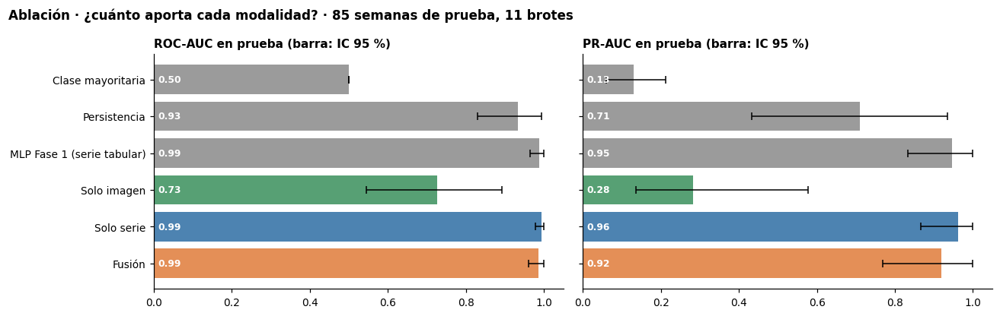

In [39]:
# Celda 36 · Rama C (3/4): resultados de la ablación en la prueba, con su incertidumbre
# Qué hace: compara, en las mismas 85 semanas de prueba (11 brotes), la fusión, sus dos ramas por
#   separado y las referencias: clase mayoritaria, persistencia y el MLP de la Fase 1 (celda 16).
# Dos tipos de métricas:
#   · Sin umbral: ROC-AUC (qué tan bien ordena el riesgo) y PR-AUC o precisión promedio (lo mismo,
#     pero centrado en la clase brote, la rara). Con 7 brotes en validación el umbral es inestable
#     (celda 16), así que estas son las métricas principales de la ablación.
#   · Con umbral: el más alto que avisa el 90 % de los brotes de validación (la regla de la Fase 1).
# Incertidumbre: con 11 brotes, una diferencia de 0,05 en AUC puede ser azar. Se remuestrean las 85
#   semanas de prueba 2.000 veces (bootstrap) y se reporta el intervalo del 95 % de cada métrica y de
#   la diferencia «fusión − mejor rama sola».
from sklearn.metrics import average_precision_score

idx_t, idx_v = INDICES["test"], INDICES["val"]
y_t, bt_t = Y_BROTE[idx_t], BROTE_T_IMG[idx_t]
prob_mlp_img = mlp_imagenes["prob_mlp"].values                     # mismo orden que `sel`
PUNTAJES_T = {"Clase mayoritaria": (np.zeros(len(idx_t)), 0.5),
              "Persistencia": (bt_t.astype(float), 0.5),
              "MLP Fase 1 (serie tabular)": (prob_mlp_img[idx_t], umbral_bloques)}
for nombre_e in ENTRADAS:
    umbral_e = umbral_por_recall(Y_BROTE[idx_v], PROB_C[nombre_e]["val"])
    PUNTAJES_T[nombre_e] = (PROB_C[nombre_e]["test"], umbral_e)

filas_f = []
for nombre_m, (p, u) in PUNTAJES_T.items():
    filas_f.append({"modelo": nombre_m, "ROC-AUC": roc_auc_score(y_t, p), "PR-AUC": average_precision_score(y_t, p),
                    "umbral": u, **{k: v for k, v in metricas(y_t, p >= u, bt_t).items()
                                    if k in ("precisión", "recall", "F1", "brotes_sin_aviso", "falsas_alarmas")}})
ablacion = pd.DataFrame(filas_f)
print(f"Prueba · {len(y_t)} semanas con imagen · {y_t.sum()} brotes · {int(((bt_t == 0) & (y_t == 1)).sum())} inicio(s) de brote")
print(ablacion.round(3).to_string(index=False))

print("\nVariación entre las 5 semillas (ROC-AUC y PR-AUC de prueba):")
for nombre_e in ENTRADAS:
    aucs = [roc_auc_score(y_t, sp["test"]) for sp in SEMILLAS_PROB[nombre_e]]
    aps = [average_precision_score(y_t, sp["test"]) for sp in SEMILLAS_PROB[nombre_e]]
    print(f"  {nombre_e:11s}: ROC-AUC {np.mean(aucs):.3f} ± {np.std(aucs, ddof=1):.3f} · "
          f"PR-AUC {np.mean(aps):.3f} ± {np.std(aps, ddof=1):.3f}")

# Bootstrap de la prueba
rng_b = np.random.default_rng(SEMILLA)
muestras_b = {m: {"ROC-AUC": [], "PR-AUC": []} for m in PUNTAJES_T}
dif_b = {"Fusión − Solo serie": [], "Fusión − Solo imagen": [], "Fusión − Persistencia": []}
for _ in range(2000):
    r = rng_b.integers(0, len(y_t), len(y_t))
    if y_t[r].sum() == 0 or y_t[r].sum() == len(r):
        continue
    ap_r = {}
    for nombre_m, (p, _) in PUNTAJES_T.items():
        muestras_b[nombre_m]["ROC-AUC"].append(roc_auc_score(y_t[r], p[r]))
        ap_r[nombre_m] = average_precision_score(y_t[r], p[r])
        muestras_b[nombre_m]["PR-AUC"].append(ap_r[nombre_m])
    for etiqueta in dif_b:
        dif_b[etiqueta].append(ap_r["Fusión"] - ap_r[etiqueta.split(" − ")[1]])
intervalos = pd.DataFrame([{"modelo": m, **{f"{met} IC95": f"[{np.percentile(v, 2.5):.3f}, {np.percentile(v, 97.5):.3f}]"
                                            for met, v in d.items()}} for m, d in muestras_b.items()])
print("\nIntervalos del 95 % (bootstrap, 2.000 remuestreos de la prueba):")
print(intervalos.to_string(index=False))
print("\nDiferencia de PR-AUC (bootstrap):")
for etiqueta, v in dif_b.items():
    v = np.array(v)
    print(f"  {etiqueta}: media {v.mean():+.3f} · IC95 [{np.percentile(v, 2.5):+.3f}, {np.percentile(v, 97.5):+.3f}] · "
          f"la fusión gana en el {np.mean(v > 0):.0%} de los remuestreos")

COLOR_ABL = {"Clase mayoritaria": GRIS, "Persistencia": GRIS, "MLP Fase 1 (serie tabular)": GRIS,
             "Solo imagen": VERDE, "Solo serie": AZUL, "Fusión": NARANJA}
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
nombres_m = list(PUNTAJES_T)
for ax, met in zip(axes, ["ROC-AUC", "PR-AUC"]):
    valores = ablacion.set_index("modelo")[met]
    bajo = [valores[m] - np.percentile(muestras_b[m][met], 2.5) for m in nombres_m]
    alto = [np.percentile(muestras_b[m][met], 97.5) - valores[m] for m in nombres_m]
    ax.barh(range(len(nombres_m)), [valores[m] for m in nombres_m], xerr=[np.clip(bajo, 0, None), np.clip(alto, 0, None)],
            color=[COLOR_ABL[m] for m in nombres_m], alpha=0.85, capsize=3, error_kw={"lw": 1})
    for i, m in enumerate(nombres_m):
        ax.text(0.01, i, f"{valores[m]:.2f}", va="center", ha="left", color="white", fontsize=8, fontweight="bold")
    ax.set_xlim(0, 1.05); ax.set_title(f"{met} en prueba (barra: IC 95 %)", loc="left")
axes[0].set_yticks(range(len(nombres_m)), nombres_m); axes[0].invert_yaxis()
fig.suptitle(f"Ablación · ¿cuánto aporta cada modalidad? · {len(y_t)} semanas de prueba, {y_t.sum()} brotes", x=0.01, ha="left",
             fontsize=11, fontweight="bold")
plt.tight_layout(); plt.show()
ablacion.to_csv(f"{CARPETA}/ablacion_rama_c.csv", index=False)


**Lectura.** (1) **La imagen no aporta a la alerta.** «Solo serie» logra PR-AUC 0,962 y ROC-AUC 0,994; la fusión, 0,920 y 0,986. La diferencia en PR-AUC es −0,040 (IC 95 %: −0,128 a 0,000) y la fusión gana solo en el 1 % de los remuestreos. El resultado se sostiene con 5 semillas (0,964 ± 0,004 frente a 0,927 ± 0,011). (2) Con el umbral de validación, las dos avisan los 11 brotes, pero la fusión da 9 falsas alarmas y «Solo serie» 3 (F1 0,710 frente a 0,880). (3) La imagen sola tiene algo de señal (PR-AUC 0,282 cuando al azar sería 0,129; ROC-AUC 0,726), muy por debajo de la serie y, según la celda 32, sobre todo por la identidad del municipio. (4) La fusión supera a la persistencia (PR-AUC +0,206; IC 95 %: 0,034 a 0,414), pero el mérito es de la serie. (5) «Solo serie» (la RNN preentrenada con toda la serie más una cabeza entrenada con 383 semanas) queda a la par del MLP de la Fase 1 (PR-AUC 0,962 frente a 0,947, con intervalos superpuestos).

**Por qué la imagen no aporta:** (a) la serie ya resume el estado epidemiológico: la zona de esta semana predice muy bien la siguiente (celda 28); (b) los 32 componentes de la imagen, aprendidos con solo 55 brotes, agregan dimensiones que la cabeza no puede aprovechar sin sobreajustar; (c) el paisaje urbano casi no cambia de una semana a otra y el brote sí; las nubes cambian, pero no por el dengue. **Limitación:** la prueba con imagen tiene un solo inicio de brote, así que no se puede medir si la imagen ayuda a anticipar inicios, que es donde podría aportar.

In [40]:
# Celda 37 · Rama C (4/4): ¿cuándo aporta la imagen?
# Qué hace: compara el error de las tres variantes por grupos de la prueba, con el puntaje de Brier
#   (error cuadrático medio de la probabilidad: 0 es perfecto; más bajo es mejor). Se usa Brier y no
#   F1 porque en cada grupo hay muy pocos brotes y el F1 se vuelve inestable.
#   · Por nubosidad: si la imagen solo aportara con cielo despejado, la fusión debería ganar ahí.
#   · Por municipio: si la imagen solo ayudara donde la serie es débil.
# Advertencia: son grupos de 85 semanas partidas en pedazos; es una lectura exploratoria, no una prueba.
prueba_c = sel.iloc[idx_t][["municipio", "anio", "semana", "nubes"]].copy()
prueba_c["y"] = y_t
for nombre_e in ENTRADAS:
    prueba_c[f"error {nombre_e}"] = (PROB_C[nombre_e]["test"] - y_t) ** 2
corte_nubes = prueba_c["nubes"].median()
prueba_c["cielo"] = np.where(prueba_c["nubes"] <= corte_nubes, f"despejado (≤ {corte_nubes:.2f})",
                             f"con nubes (> {corte_nubes:.2f})")
columnas_err = [f"error {n}" for n in ENTRADAS]
for grupo in ["cielo", "municipio"]:
    resumen_g = prueba_c.groupby(grupo).agg(semanas=("y", "size"), brotes=("y", "sum"),
                                            **{c.replace("error ", "Brier "): (c, "mean") for c in columnas_err})
    resumen_g["gana"] = resumen_g[[c.replace("error ", "Brier ") for c in columnas_err]].idxmin(axis=1).str.replace("Brier ", "")
    print(f"Puntaje de Brier en prueba por {grupo} (más bajo es mejor):")
    print(resumen_g.round(3).to_string(), "\n")
print("Brier global:", " · ".join(f"{n} {prueba_c[f'error {n}'].mean():.3f}" for n in ENTRADAS))


Puntaje de Brier en prueba por cielo (más bajo es mejor):
                    semanas  brotes  Brier Solo imagen  Brier Solo serie  Brier Fusión        gana
cielo                                                                                             
con nubes (> 0.03)       42       3              0.177             0.028         0.061  Solo serie
despejado (≤ 0.03)       43       8              0.225             0.034         0.036  Solo serie 

Puntaje de Brier en prueba por municipio (más bajo es mejor):
               semanas  brotes  Brier Solo imagen  Brier Solo serie  Brier Fusión        gana
municipio                                                                                    
Barranquilla         3       0              0.181             0.019         0.018      Fusión
Bucaramanga          7       0              0.189             0.000         0.000      Fusión
Cali                11       0              0.151             0.027         0.110  Solo serie
Cúcuta      

**Lectura.** Con cielo despejado (nubes ≤ 0,03; 43 semanas, 8 brotes), la fusión casi empata con «Solo serie» (Brier 0,036 frente a 0,034); con nubes (42 semanas, 3 brotes), su error es el doble (0,061 frente a 0,028). **La imagen no aporta ni en el mejor caso, y estorba cuando hay nubes**, coherente con el Grad-CAM (celda 33). Por municipio, la fusión gana en Cúcuta (0,008 frente a 0,032), empata en Barranquilla, Bucaramanga y Medellín, y pierde con claridad en Cali (0,110 frente a 0,027) y Neiva (0,110 frente a 0,008). Con 3 a 18 semanas por municipio, estas diferencias son exploratorias.

## 8. Auditoría a la IA: la deduplicación por ETag

En la exploración de las imágenes, la IA quitó las repetidas comparando el ETag (la huella del archivo en S3) dentro de cada carpeta y reportó 1.060 imágenes listas, cada una con el municipio de su carpeta. El equipo no lo aceptó: en una figura vio la misma ciudad en carpetas de municipios distintos, y la georreferencia de cada escena lo confirmó. Esta sección mide **cuánto habría cambiado el resultado** si se hubiera aceptado la propuesta. El detalle del episodio está en la bitácora.

In [41]:
# Celda 38 · Auditoría a la IA: la deduplicación por ETag · bitácora E-14, E-22
# Qué pasó: en la exploración, la IA (Claude) quitó las repetidas comparando el ETag de S3 (la huella
#   del archivo) DENTRO de cada carpeta y dio por buenas 1.060 escenas (1.270 con contenido menos 210
#   copias de relleno), cada una con el municipio de su carpeta. El equipo vio en una figura la misma
#   ciudad en carpetas de municipios distintos; la georreferencia de cada escena lo confirmó (celda 8).
#   Comparar ETag carpeta por carpeta no puede ver que el mismo archivo está también en otra carpeta,
#   ni que la carpeta no corresponde al municipio que muestra la escena.
# Qué mide esta celda: cuánto habría cambiado el resultado si se hubiera aceptado la propuesta de la IA.
#   1. El conjunto «contaminado»: deduplicación por ETag dentro de cada carpeta, municipio = carpeta,
#      mismo umbral de nubes y la misma partición por bloques de 4 semanas.
#   2. Cuántas imágenes quedan con el municipio (y por tanto la etiqueta) de otra ciudad, cuántas son la
#      misma escena repetida en varias carpetas, y cuántas imágenes de prueba tienen una gemela casi
#      idéntica en entrenamiento (fuga).
#   3. La CNN ganadora entrenada con el conjunto contaminado, evaluada en SU prueba (lo que se habría
#      reportado) y en la prueba limpia (la verdad).
# Tiempo estimado con GPU T4: 1 a 2 minutos.
por_carpeta = con_contenido.drop_duplicates(["divipola_carpeta", "etag"])
print(f"Escenas con contenido: {len(con_contenido)} · únicas por ETag dentro de cada carpeta (propuesta de la IA): "
      f"{len(por_carpeta)} · únicas por ETag en todo el conjunto: {con_contenido['etag'].nunique()} · "
      f"válidas tras el control de la celda 8: {len(validas)}")

base = por_carpeta                                                    # el criterio propuesto por la IA
base = base[base["nubes"] <= UMBRAL_NUBES].rename_axis("fila_x").reset_index()   # fila_x = posición en X_todas
base["divipola"] = base["divipola_carpeta"]                           # municipio = carpeta
contam = (base.merge(datos[["divipola", "anio", "semana", "y_zona"]], on=["divipola", "anio", "semana"], how="left")
          .set_index("fila_x").dropna(subset=["y_zona"]))
contam["conjunto"] = ((contam["fecha"] - pd.Timestamp("2016-01-03")).dt.days // 28).map(BLOQUE_CONJ)
contam["mal_ubicada"] = contam["divipola_carpeta"] != contam["divipola_real"]
contam["en_varias_carpetas"] = contam["etag"].map(contam["etag"].value_counts()) > 1
print(f"Conjunto contaminado: {len(contam)} imágenes (limpio: {len(sel)}) · con el municipio de otra ciudad: "
      f"{contam['mal_ubicada'].sum()} ({contam['mal_ubicada'].mean():.0%}) · el mismo archivo en varias carpetas: "
      f"{contam['en_varias_carpetas'].sum()} ({contam['en_varias_carpetas'].mean():.0%})")
etiquetas_por_archivo = contam.groupby("etag")["y_zona"].nunique()
print(f"Archivos que quedan con etiquetas distintas según la carpeta: {(etiquetas_por_archivo > 1).sum()} "
      "(la misma foto enseñada como dos zonas diferentes)")
print(pd.crosstab(contam["conjunto"], contam["y_zona"].map(ZONAS)).reindex(["train", "val", "test"]).to_string())


def gemelas(indices_a, indices_b):
    """Cuántas escenas de indices_a tienen una casi idéntica (diferencia media < 1) en indices_b."""
    fb = firma[np.asarray(indices_b)]
    return int(sum((np.abs(fb - firma[i]).mean(axis=1) < 1).any() for i in indices_a))


IDX_CONT = {k: contam.index[contam["conjunto"] == k].values for k in ("train", "val", "test")}
idx_limpio_test = sel["indice_escena"].values[INDICES["test"]]
idx_limpio_train = sel["indice_escena"].values[INDICES["train"]]
print(f"\nFuga · prueba contaminada con gemela en su entrenamiento: {gemelas(IDX_CONT['test'], IDX_CONT['train'])} "
      f"de {len(IDX_CONT['test'])}")
print(f"Fuga · prueba limpia con gemela en el entrenamiento contaminado: {gemelas(idx_limpio_test, IDX_CONT['train'])} "
      f"de {len(idx_limpio_test)}")
print(f"Control · prueba limpia con gemela en el entrenamiento limpio: {gemelas(idx_limpio_test, idx_limpio_train)} "
      f"de {len(idx_limpio_test)}")

# La CNN ganadora entrenada con el conjunto contaminado
Y_CONT = torch.full((len(X_todas),), -1, dtype=torch.long)
Y_CONT[contam.index.values] = torch.tensor(contam["y_zona"].astype(int).values)
conteo_c = np.bincount(Y_CONT[IDX_CONT["train"]].numpy(), minlength=3)
datos_cont = {"X": X_todas, "indices": IDX_CONT, "y": Y_CONT,
              "pesos": torch.tensor(len(IDX_CONT["train"]) / (3 * conteo_c), dtype=torch.float32)}
modelo_cont = construir(*GANADOR)
entrenar_cnn(modelo_cont, datos_img=datos_cont)

pred_cont_propia = logits_cnn(modelo_cont, IDX_CONT["test"], X=X_todas).argmax(1).numpy()
pred_cont_limpia = logits_cnn(modelo_cont, INDICES["test"]).argmax(1).numpy()
auditoria = pd.DataFrame([
    {"modelo": "CNN entrenada con el conjunto contaminado", "evaluada en": "su propia prueba (lo que se habría reportado)",
     **metricas_zona(Y_CONT[IDX_CONT["test"]].numpy(), pred_cont_propia)},
    {"modelo": "CNN entrenada con el conjunto contaminado", "evaluada en": "la prueba limpia (la verdad)",
     **metricas_zona(y_test_a, pred_cont_limpia)},
    {"modelo": "CNN entrenada con el conjunto limpio", "evaluada en": "la prueba limpia",
     **metricas_zona(y_test_a, pred_test_a)}])
print("\n", auditoria[["modelo", "evaluada en", "exactitud", "F1 macro", "exactitud balanceada"]].round(3).to_string(index=False))
brecha = auditoria.loc[0, "F1 macro"] - auditoria.loc[1, "F1 macro"]
print(f"\nBrecha entre lo que se habría reportado y la verdad (F1 macro): {brecha:+.3f}")

Escenas con contenido: 1270 · únicas por ETag dentro de cada carpeta (propuesta de la IA): 1060 · únicas por ETag en todo el conjunto: 758 · válidas tras el control de la celda 8: 748
Conjunto contaminado: 808 imágenes (limpio: 551) · con el municipio de otra ciudad: 247 (31%) · el mismo archivo en varias carpetas: 333 (41%)
Archivos que quedan con etiquetas distintas según la carpeta: 55 (la misma foto enseñada como dos zonas diferentes)
y_zona    alerta  brote  seguridad
conjunto                          
train         50     80        421
val           17     11        101
test          12     18         98

Fuga · prueba contaminada con gemela en su entrenamiento: 2 de 128
Fuga · prueba limpia con gemela en el entrenamiento contaminado: 2 de 85
Control · prueba limpia con gemela en el entrenamiento limpio: 0 de 85

                                    modelo                                   evaluada en  exactitud  F1 macro  exactitud balanceada
CNN entrenada con el conjunto contami

**Lectura.** (1) La propuesta de la IA (ETag dentro de cada carpeta) reproduce exactamente las 1.060 escenas que reportó; el control de la celda 8 deja 748. (2) Con el mismo umbral de nubes, el conjunto contaminado tendría **808 imágenes en lugar de 551** (en apariencia, un 47 % más de datos), pero **el 31 % (247) con el municipio de otra ciudad**, el 41 % (333) repetidas en varias carpetas y 55 archivos enseñados como dos zonas distintas. (3) La fuga entre entrenamiento y prueba es mínima (2 de 128 y 2 de 85 imágenes con una gemela). (4) **El hallazgo central:** la CNN contaminada saca casi lo mismo en su propia prueba (F1 macro 0,281) que en la prueba limpia (0,285), así que la métrica no delata el error. Pero el modelo es peor: frente a la CNN limpia (0,392), pierde 0,107 de F1 macro (−27 %) y la exactitud balanceada baja de 0,474 a 0,378.

**Lección:** un error en la preparación de los datos puede no verse en las métricas, porque contamina también la prueba. Solo una verificación independiente del dato (aquí, una figura y la georreferencia) lo detecta. Desde entonces, el equipo revisa visualmente las imágenes antes de aceptar un conteo de la IA (bitácora E-14). Esta misma celda tuvo un error de la IA en su primera versión, que comparaba el ETag en todo el conjunto (758 únicas) y no carpeta por carpeta; se corrigió antes de esta ejecución (bitácora E-22).

## 9. Gráficas para el cliente

Cuatro gráficas para el equipo de Enfermedades Transmitidas por Vectores, cada una con una pregunta en el título y sin tecnicismos, y un panel interactivo (celda 42, al final de la sección 10). Se guardan en alta resolución para el informe y las diapositivas.

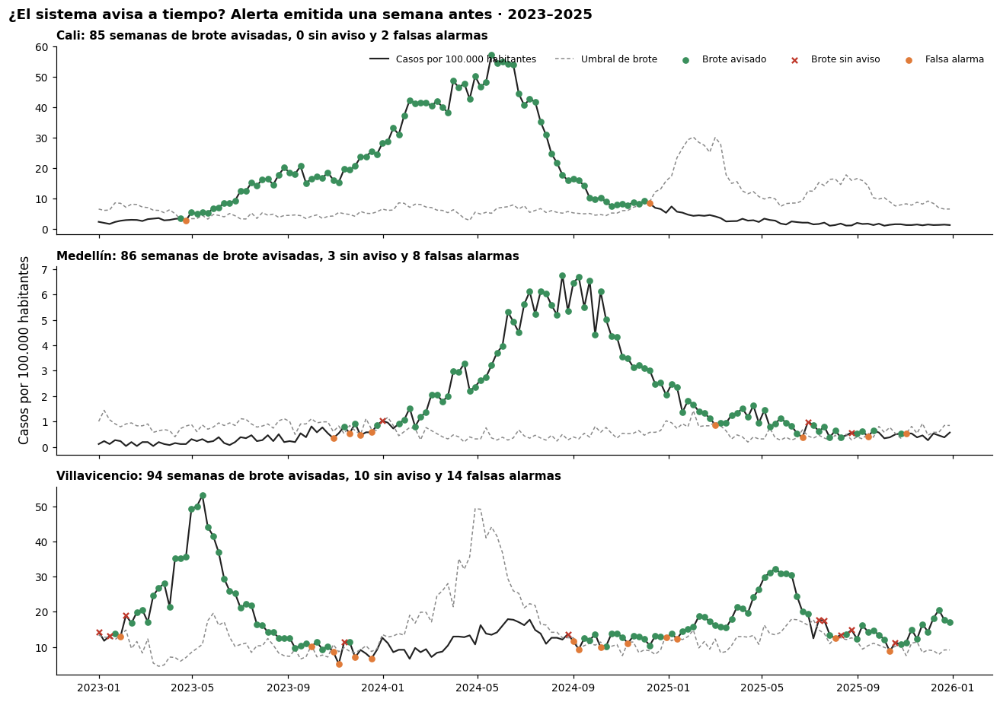

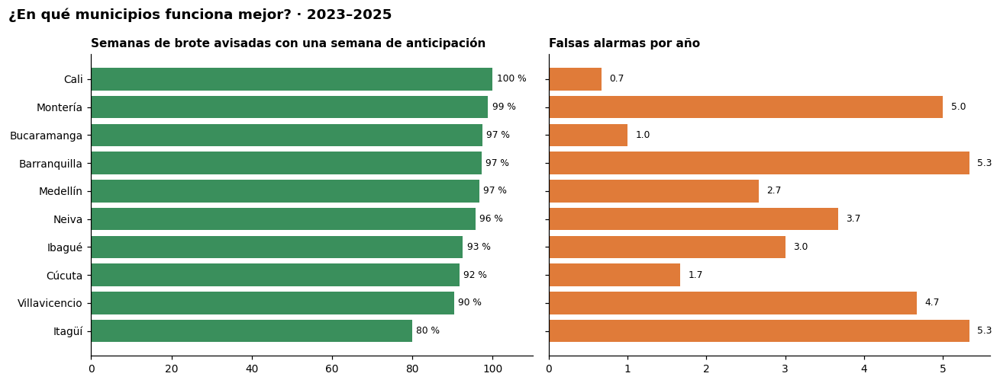

En total: 794 semanas de brote avisadas, 38 sin aviso y 99 falsas alarmas (3.3 por municipio y año).


In [42]:
# Celda 39 · Gráficas para el cliente (1/2): ¿el sistema avisa a tiempo?
# Para quién: el equipo de Enfermedades Transmitidas por Vectores de una secretaría de salud. Lenguaje
#   sin tecnicismos; cada gráfica responde una pregunta. Se guardan en alta resolución en la carpeta
#   «figuras» para el informe y las diapositivas.
# Qué alerta se muestra: la del MLP de la Fase 1 (celda 14), que en la comparación justa de la celda 26
#   anticipa más inicios de brote con las mismas falsas alarmas. Prueba 2023–2025: datos que el modelo
#   nunca vio.
os.makedirs(f"{CARPETA}/figuras", exist_ok=True)
vista = datos.loc[T_crono.index, ["divipola", "municipio", "fecha", "incidencia", "y_inc", "q3_t1", "y_brote"]].copy()
vista["fecha_obj"] = vista["fecha"] + pd.Timedelta(weeks=1)
vista["alerta"] = (pred_mlp_crono.loc[vista.index] >= umbral_crono).astype(int)
vista["resultado"] = np.select(
    [(vista["alerta"] == 1) & (vista["y_brote"] == 1), (vista["alerta"] == 0) & (vista["y_brote"] == 1),
     (vista["alerta"] == 1) & (vista["y_brote"] == 0)],
    ["Brote avisado", "Brote sin aviso", "Falsa alarma"], "Sin brote y sin aviso")

# Figura 1 · Línea de tiempo de tres municipios
COLOR_RES = {"Brote avisado": VERDE, "Brote sin aviso": ROJO, "Falsa alarma": NARANJA}
fig, axes = plt.subplots(3, 1, figsize=(12, 8.5), sharex=True)
for ax, cod in zip(axes, ["76001", "05001", "50001"]):
    d = vista[vista["divipola"] == cod]
    ax.plot(d["fecha_obj"], d["y_inc"], color="#222222", lw=1.4, label="Casos por 100.000 habitantes")
    ax.plot(d["fecha_obj"], d["q3_t1"], color=GRIS, lw=1, ls=(0, (3, 2)), label="Umbral de brote")
    for res, color in COLOR_RES.items():
        e = d[d["resultado"] == res]
        ax.scatter(e["fecha_obj"], e["y_inc"], color=color, s=22, zorder=3, label=res,
                   marker="x" if res == "Brote sin aviso" else "o")
    n = d["resultado"].value_counts()
    ax.set_title(f"{NOMBRE[cod]}: {n.get('Brote avisado', 0)} semanas de brote avisadas, "
                 f"{n.get('Brote sin aviso', 0)} sin aviso y {n.get('Falsa alarma', 0)} falsas alarmas", loc="left")
axes[0].legend(ncol=5, fontsize=8, frameon=False, loc="upper right")
fig.supylabel("Casos por 100.000 habitantes")
fig.suptitle("¿El sistema avisa a tiempo? Alerta emitida una semana antes · 2023–2025", x=0.01, ha="left",
             fontsize=12, fontweight="bold")
plt.tight_layout(); plt.savefig(f"{CARPETA}/figuras/cliente_1_alertas_en_el_tiempo.png", dpi=200); plt.show()

# Figura 2 · Balance por municipio
balance = vista.pivot_table(index="municipio", columns="resultado", values="y_brote", aggfunc="size", fill_value=0)
for c in COLOR_RES:
    if c not in balance:
        balance[c] = 0
balance["avisados %"] = 100 * balance["Brote avisado"] / (balance["Brote avisado"] + balance["Brote sin aviso"]).replace(0, np.nan)
balance["falsas por año"] = balance["Falsa alarma"] / 3
balance = balance.sort_values("avisados %")
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), sharey=True)
axes[0].barh(balance.index, balance["avisados %"], color=VERDE)
for i, v in enumerate(balance["avisados %"]):
    axes[0].text(v + 1, i, f"{v:.0f} %" if pd.notna(v) else "sin brotes", va="center", fontsize=8)
axes[0].set_xlim(0, 110); axes[0].set_title("Semanas de brote avisadas con una semana de anticipación", loc="left")
axes[1].barh(balance.index, balance["falsas por año"], color=NARANJA)
for i, v in enumerate(balance["falsas por año"]):
    axes[1].text(v + 0.1, i, f"{v:.1f}", va="center", fontsize=8)
axes[1].set_title("Falsas alarmas por año", loc="left")
fig.suptitle("¿En qué municipios funciona mejor? · 2023–2025", x=0.01, ha="left", fontsize=12, fontweight="bold")
plt.tight_layout(); plt.savefig(f"{CARPETA}/figuras/cliente_2_balance_por_municipio.png", dpi=200); plt.show()
total = vista["resultado"].value_counts()
print(f"En total: {total.get('Brote avisado', 0)} semanas de brote avisadas, {total.get('Brote sin aviso', 0)} sin aviso "
      f"y {total.get('Falsa alarma', 0)} falsas alarmas ({total.get('Falsa alarma', 0) / 30:.1f} por municipio y año).")


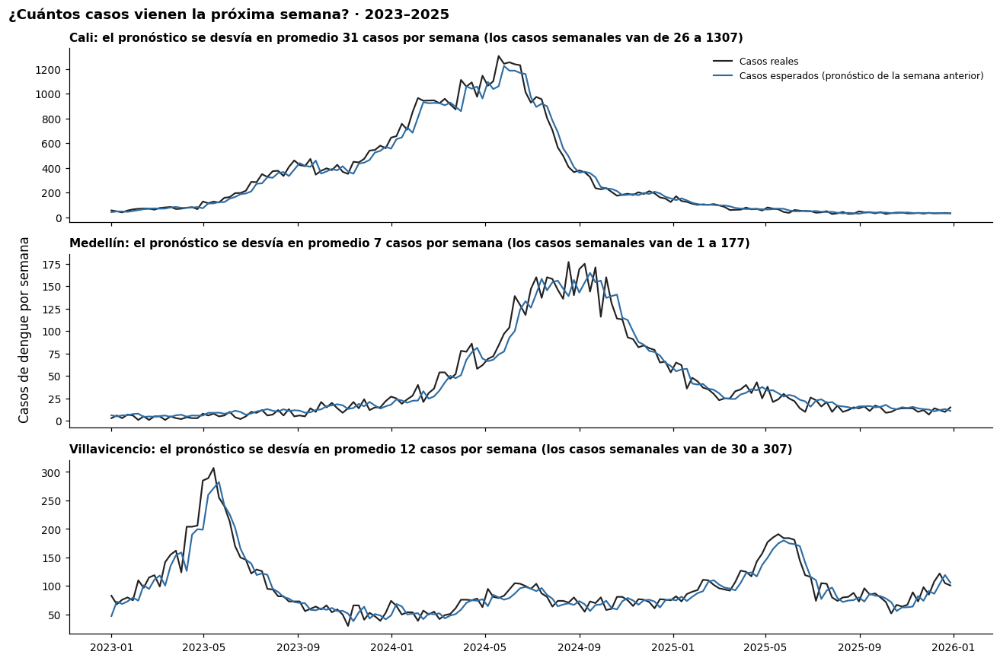

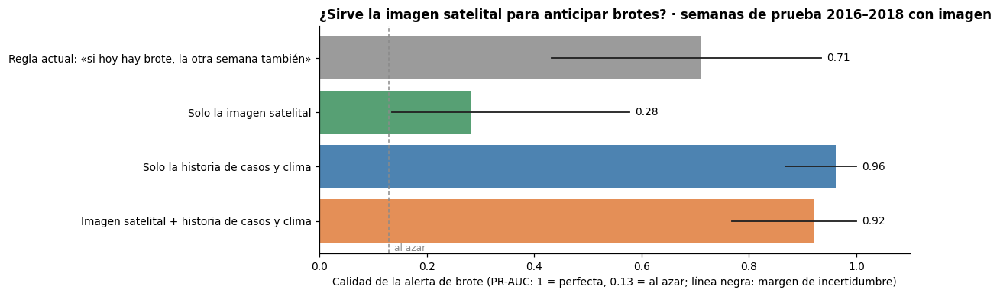

Figuras guardadas en /content/centinela_fase2/figuras/: ['cliente_1_alertas_en_el_tiempo.png', 'cliente_2_balance_por_municipio.png', 'cliente_3_casos_esperados.png', 'cliente_4_valor_del_satelite.png']


In [43]:
# Celda 40 · Gráficas para el cliente (2/2): ¿cuántos casos vienen? y ¿sirve el satélite?
# Figura 3: casos esperados la semana siguiente según la rama B elegida (celda 25), frente a los casos
#   reales, en número de casos (no por 100.000 habitantes): es la cifra con la que se planean
#   brigadas, insumos y camas.
# Figura 4: la respuesta a la pregunta de la fusión, en palabras del cliente.
if OBJETIVO_B == "cambio":
    pred_b = predecir_cambio(modelos_c[(ELEGIDA_B, MEJOR_C[ELEGIDA_B])], D12c["test"])
else:
    pred_b = predecir(modelos_b[(ELEGIDA_B, MEJOR_B[ELEGIDA_B])], D12["test"])
casos_b = datos.loc[D12["test"]["filas"], ["divipola", "fecha", "y_inc", "poblacion_t1"]].copy()
casos_b["fecha_obj"] = casos_b["fecha"] + pd.Timedelta(weeks=1)
casos_b["reales"] = casos_b["y_inc"] * casos_b["poblacion_t1"] / 100_000
casos_b["esperados"] = pred_b * casos_b["poblacion_t1"] / 100_000

fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)
for ax, cod in zip(axes, ["76001", "05001", "50001"]):
    d = casos_b[casos_b["divipola"] == cod]
    ax.plot(d["fecha_obj"], d["reales"], color="#222222", lw=1.4, label="Casos reales")
    ax.plot(d["fecha_obj"], d["esperados"], color=AZUL, lw=1.4, label="Casos esperados (pronóstico de la semana anterior)")
    error = np.mean(np.abs(d["esperados"] - d["reales"]))
    ax.set_title(f"{NOMBRE[cod]}: el pronóstico se desvía en promedio {error:.0f} casos por semana "
                 f"(los casos semanales van de {d['reales'].min():.0f} a {d['reales'].max():.0f})", loc="left")
axes[0].legend(fontsize=8, frameon=False, loc="upper right")
fig.supylabel("Casos de dengue por semana")
fig.suptitle("¿Cuántos casos vienen la próxima semana? · 2023–2025", x=0.01, ha="left", fontsize=12, fontweight="bold")
plt.tight_layout(); plt.savefig(f"{CARPETA}/figuras/cliente_3_casos_esperados.png", dpi=200); plt.show()

# Figura 4 · ¿Sirve la imagen satelital? (PR-AUC de la celda 36, con su intervalo)
etiquetas_cliente = {"Persistencia": "Regla actual: «si hoy hay brote, la otra semana también»",
                     "Solo imagen": "Solo la imagen satelital",
                     "Solo serie": "Solo la historia de casos y clima",
                     "Fusión": "Imagen satelital + historia de casos y clima"}
fig, ax = plt.subplots(figsize=(11, 3.6))
for i, (m, texto) in enumerate(etiquetas_cliente.items()):
    v = ablacion.set_index("modelo").loc[m, "PR-AUC"]
    lo, hi = np.percentile(muestras_b[m]["PR-AUC"], [2.5, 97.5])
    ax.barh(i, v, color=COLOR_ABL[m], alpha=0.85)
    ax.plot([lo, hi], [i, i], color="#222222", lw=1.2)
    ax.text(min(hi, 1) + 0.01, i, f"{v:.2f}", va="center", fontsize=9)
ax.set_yticks(range(len(etiquetas_cliente)), list(etiquetas_cliente.values())); ax.invert_yaxis()
azar = y_t.mean()                                            # PR-AUC de una alerta al azar = proporción de brotes
ax.axvline(azar, color=GRIS, lw=1, ls=(0, (3, 2)))
ax.text(azar + 0.01, len(etiquetas_cliente) - 0.45, "al azar", fontsize=8, color=GRIS)
ax.set_xlim(0, 1.1)
ax.set_xlabel(f"Calidad de la alerta de brote (PR-AUC: 1 = perfecta, {azar:.2f} = al azar; línea negra: margen de incertidumbre)")
ax.set_title("¿Sirve la imagen satelital para anticipar brotes? · semanas de prueba 2016–2018 con imagen", loc="left",
             fontsize=11, fontweight="bold")
plt.tight_layout(); plt.savefig(f"{CARPETA}/figuras/cliente_4_valor_del_satelite.png", dpi=200); plt.show()
print("Figuras guardadas en", f"{CARPETA}/figuras/:", sorted(os.listdir(f"{CARPETA}/figuras")))


**Lectura para el cliente.** (1) **Alerta** (gráficas 1 y 2): en 2023–2025, el sistema avisó con una semana de anticipación 794 de las 832 semanas de brote (95 %), dejó 38 sin aviso y dio 99 falsas alarmas, unas 3,3 por municipio y año. Funciona mejor en Cali (todas las semanas de brote avisadas y 0,7 falsas alarmas por año) y peor en Itagüí (80 % avisadas), el municipio con menos casos; Barranquilla e Itagüí tienen la mayor cantidad de falsas alarmas (5,3 por año). (2) **Casos** (gráfica 3): el pronóstico de la semana siguiente se desvía en promedio 31 casos por semana en Cali (con semanas de 26 a 1.307 casos), 7 en Medellín (de 1 a 177) y 12 en Villavicencio (de 30 a 307); sigue bien la forma de la epidemia, pero llega un poco tarde a los picos. (3) **Satélite** (gráfica 4): con las imágenes disponibles (2016–2018), la imagen satelital no mejora la alerta; la historia de casos y clima basta.

**Recomendación:** usar la alerta de la serie y el pronóstico de casos; no invertir todavía en el componente satelital hasta contar con más años de imágenes y una medida de nubes más precisa.

## 10. Anexo de procedencia y descarga de resultados

In [44]:
# Celda 41 · Anexo de procedencia (SHA-256) y descarga de resultados
# Qué hace:
#   1. Tabla de procedencia: cada archivo descargado (SIVIGILA, NASA POWER, DANE) con su URL, la
#      fecha de descarga y su huella SHA-256, más las 551 escenas de PhysioNet usadas. Si alguien
#      descarga lo mismo y obtiene otra huella, el archivo cambió en la fuente.
#   2. Los pesos entrenados (.pth) con su tamaño y su huella.
#   3. Dos archivos .zip para descargar: resultados (figuras y tablas) y pesos.
# Política de datos: no se incluyen los conteos de SIVIGILA ni la tabla municipio-semana (datos de salud,
#   aunque agregados): se quedan en la sesión, como en la Fase 1.
import zipfile

anexo = pd.DataFrame(procedencia, columns=["archivo", "url", "fecha_descarga", "sha256"]).drop_duplicates("archivo")
anexo["fuente"] = np.select([anexo["url"].str.contains("sivigila"), anexo["url"].str.contains("power.larc"),
                             anexo["url"].str.contains("proyecciones")], ["SIVIGILA (INS)", "NASA POWER", "DANE (sivirep)"], "otra")
escenas_usadas = sel[["clave", "divipola", "anio", "semana", "sha256"]].rename(columns={"clave": "archivo"})
escenas_usadas = escenas_usadas.assign(url=BUCKET + "/" + escenas_usadas["archivo"], fuente="PhysioNet (Cajas et al., 2024)",
                                       fecha_descarga=FECHA_EJECUCION)
anexo_completo = pd.concat([anexo, escenas_usadas[["archivo", "url", "fecha_descarga", "sha256", "fuente"]]], ignore_index=True)
anexo_completo.to_csv(f"{CARPETA}/anexo_procedencia.csv", index=False)
print("Archivos por fuente:")
print(anexo_completo["fuente"].value_counts().to_string())

pesos = []
for nombre_p in sorted(os.listdir(f"{CARPETA}/pesos")):
    ruta = f"{CARPETA}/pesos/{nombre_p}"
    with open(ruta, "rb") as f:
        pesos.append({"archivo": nombre_p, "MB": round(os.path.getsize(ruta) / 1e6, 1),
                      "sha256": hashlib.sha256(f.read()).hexdigest()})
pesos = pd.DataFrame(pesos)
pesos.to_csv(f"{CARPETA}/anexo_pesos.csv", index=False)
print(f"\nPesos guardados ({pesos['MB'].sum():.0f} MB en total; GitHub acepta archivos de hasta 100 MB):")
print(pesos.assign(sha256=pesos["sha256"].str[:16] + "…").to_string(index=False))

with zipfile.ZipFile(f"{CARPETA}/centinela_fase2_resultados.zip", "w", zipfile.ZIP_DEFLATED) as z:
    for nombre_f in sorted(os.listdir(f"{CARPETA}/figuras")):
        z.write(f"{CARPETA}/figuras/{nombre_f}", f"figuras/{nombre_f}")
    for nombre_f in ["anexo_procedencia.csv", "anexo_pesos.csv", "ablacion_rama_c.csv"]:
        z.write(f"{CARPETA}/{nombre_f}", nombre_f)
with zipfile.ZipFile(f"{CARPETA}/centinela_fase2_pesos.zip", "w", zipfile.ZIP_STORED) as z:
    for nombre_f in pesos["archivo"]:
        z.write(f"{CARPETA}/pesos/{nombre_f}", f"pesos/{nombre_f}")
print(f"\nListos para descargar: centinela_fase2_resultados.zip "
      f"({os.path.getsize(f'{CARPETA}/centinela_fase2_resultados.zip') / 1e6:.0f} MB) y centinela_fase2_pesos.zip "
      f"({os.path.getsize(f'{CARPETA}/centinela_fase2_pesos.zip') / 1e6:.0f} MB).")
print("Para descargarlos, ejecuta en una celda nueva: guardar_local(f\"{CARPETA}/centinela_fase2_resultados.zip\") "
      "y luego lo mismo con el de pesos.")


Archivos por fuente:
fuente
PhysioNet (Cajas et al., 2024)    551
SIVIGILA (INS)                     38
DANE (sivirep)                     19
NASA POWER                         10

Pesos guardados (222 MB en total; GitHub acepta archivos de hasta 100 MB):
                     archivo   MB            sha256
rama_a_efficientnetb0_fe.pth 16.4 e48f63522aa2a910…
rama_a_efficientnetb0_ft.pth 16.4 0ab2d0aea0c57fc6…
      rama_a_resnet50_fe.pth 94.4 1c3ee8752400ddac…
      rama_a_resnet50_ft.pth 94.4 75b4be3b698a9049…
          rama_b_gru_w12.pth  0.1 69192efcb001a7ed…
   rama_b_gru_w12_cambio.pth  0.1 c175d6f14b97ac6c…
         rama_b_lstm_w12.pth  0.1 43cbe0829f7f230e…
  rama_b_lstm_w12_cambio.pth  0.1 ae57372e18f717b5…
          rama_b_rnn_w12.pth  0.0 347645da3e9ecfd4…
   rama_b_rnn_w12_cambio.pth  0.0 4c6d71326e8f20f0…
rama_c_codificador_serie.pth  0.0 1e02932e41571aa6…
           rama_c_fusion.pth  0.1 80fd3974f3db9a8f…
      rama_c_solo_imagen.pth  0.0 92064c585261df4a…
       rama_c_so

### Panel interactivo para el cliente (bonus)

Complementa las gráficas de la sección 9: el equipo de ETV puede elegir su municipio y revisar semana por semana qué habría avisado el sistema y cuántos casos esperaba.

In [45]:
# Celda 42 · Panel interactivo para el cliente (bonus)
# Qué hace: reúne en una sola página las gráficas 1 y 3 del cliente, con un selector de municipio.
#   · Arriba: incidencia semanal real, umbral de brote y el resultado de la alerta de cada semana
#     (brote avisado, brote sin aviso, falsa alarma), 2023–2025.
#   · Abajo: casos reales frente a casos esperados (el pronóstico hecho la semana anterior).
#   Al pasar el mouse sobre la gráfica se ven la fecha y los valores de cada semana.
# Se guarda como un archivo HTML que se abre en cualquier navegador, sin instalar nada:
#   figuras/panel_centinela.html
# Datos: solo los agregados municipio-semana que ya muestran las gráficas 1 y 3; ningún registro individual.
# La celda es autónoma: arma sus datos a partir de las celdas 14 (alerta del MLP) y 25 (pronóstico de
#   casos), así que solo necesita que esas celdas (y las que las preceden) se hayan ejecutado.
import plotly.graph_objects as go
from plotly.subplots import make_subplots

os.makedirs(f"{CARPETA}/figuras", exist_ok=True)
# Alerta del MLP en la prueba 2023–2025 (la misma de la gráfica 1)
panel = datos.loc[T_crono.index, ["divipola", "fecha", "y_inc", "q3_t1", "y_brote"]].copy()
panel["fecha_obj"] = panel["fecha"] + pd.Timedelta(weeks=1)
panel["alerta"] = (pred_mlp_crono.loc[panel.index] >= umbral_crono).astype(int)
panel["resultado"] = np.select(
    [(panel["alerta"] == 1) & (panel["y_brote"] == 1), (panel["alerta"] == 0) & (panel["y_brote"] == 1),
     (panel["alerta"] == 1) & (panel["y_brote"] == 0)],
    ["Brote avisado", "Brote sin aviso", "Falsa alarma"], "Sin brote y sin aviso")
# Pronóstico de casos de la rama B elegida en la celda 25 (el mismo de la gráfica 3)
if OBJETIVO_B == "cambio":
    pred_panel = predecir_cambio(modelos_c[(ELEGIDA_B, MEJOR_C[ELEGIDA_B])], D12c["test"])
else:
    pred_panel = predecir(modelos_b[(ELEGIDA_B, MEJOR_B[ELEGIDA_B])], D12["test"])
casos_panel = datos.loc[D12["test"]["filas"], ["divipola", "fecha", "y_inc", "poblacion_t1"]].copy()
casos_panel["fecha_obj"] = casos_panel["fecha"] + pd.Timedelta(weeks=1)
casos_panel["reales"] = casos_panel["y_inc"] * casos_panel["poblacion_t1"] / 100_000
casos_panel["esperados"] = pred_panel * casos_panel["poblacion_t1"] / 100_000
panel = panel.merge(casos_panel[["divipola", "fecha_obj", "reales", "esperados"]], on=["divipola", "fecha_obj"], how="left")
orden_mun = MUNICIPIOS["divipola"].tolist()
fig = make_subplots(rows=2, cols=1, shared_xaxes=True, vertical_spacing=0.09, row_heights=[0.55, 0.45],
                    subplot_titles=("¿El sistema avisa a tiempo? (alerta emitida una semana antes)",
                                    "¿Cuántos casos vienen la próxima semana?"))
ESTILO_RES = {"Brote avisado": (VERDE, "circle"), "Brote sin aviso": (ROJO, "x"), "Falsa alarma": (NARANJA, "circle")}
trazas_por_mun, resumen_mun = [], {}
for cod in orden_mun:
    d = panel[panel["divipola"] == cod].sort_values("fecha_obj")
    inicio_t = len(fig.data)
    fig.add_trace(go.Scatter(x=d["fecha_obj"], y=d["y_inc"], name="Casos por 100.000 hab.", line=dict(color="#222222", width=1.6),
                             hovertemplate="%{x|%d %b %Y}<br>Incidencia: %{y:.1f}<extra></extra>"), row=1, col=1)
    fig.add_trace(go.Scatter(x=d["fecha_obj"], y=d["q3_t1"], name="Umbral de brote", line=dict(color=GRIS, width=1, dash="dash"),
                             hovertemplate="Umbral: %{y:.1f}<extra></extra>"), row=1, col=1)
    for res, (color, simbolo) in ESTILO_RES.items():
        e = d[d["resultado"] == res]
        fig.add_trace(go.Scatter(x=e["fecha_obj"], y=e["y_inc"], mode="markers", name=res,
                                 marker=dict(color=color, symbol=simbolo, size=7),
                                 hovertemplate=f"{res}<br>%{{x|%d %b %Y}}<extra></extra>"), row=1, col=1)
    fig.add_trace(go.Scatter(x=d["fecha_obj"], y=d["reales"], name="Casos reales", line=dict(color="#222222", width=1.6),
                             hovertemplate="%{x|%d %b %Y}<br>Casos reales: %{y:.0f}<extra></extra>"), row=2, col=1)
    fig.add_trace(go.Scatter(x=d["fecha_obj"], y=d["esperados"], name="Casos esperados", line=dict(color=AZUL, width=1.6),
                             hovertemplate="Casos esperados: %{y:.0f}<extra></extra>"), row=2, col=1)
    trazas_por_mun.append(range(inicio_t, len(fig.data)))
    n = d["resultado"].value_counts()
    brotes = n.get("Brote avisado", 0) + n.get("Brote sin aviso", 0)
    resumen_mun[cod] = (f"{NOMBRE[cod]} · 2023–2025: avisó {n.get('Brote avisado', 0)} de {brotes} semanas de brote · "
                        f"{n.get('Falsa alarma', 0) / 3:.1f}".replace(".", ",") + " falsas alarmas por año · el pronóstico se desvía en promedio "
                        f"{np.mean(np.abs(d['esperados'] - d['reales'])):.0f} casos por semana")

total_trazas = len(fig.data)
botones = []
for k, cod in enumerate(orden_mun):
    visible = [False] * total_trazas
    for t in trazas_por_mun[k]:
        visible[t] = True
    botones.append(dict(label=NOMBRE[cod], method="update",
                        args=[{"visible": visible}, {"title.text": f"<b>Centinela del Dengue</b><br><sup>{resumen_mun[cod]}</sup>"}]))
for t in range(total_trazas):
    fig.data[t].visible = t in trazas_por_mun[0]
fig.update_layout(
    title=dict(text=f"<b>Centinela del Dengue</b><br><sup>{resumen_mun[orden_mun[0]]}</sup>", x=0.01),
    updatemenus=[dict(buttons=botones, direction="down", x=1.0, xanchor="right", y=1.17, yanchor="top",
                      showactive=True, bgcolor="white")],
    height=720, template="simple_white", hovermode="x unified", margin=dict(t=120, l=60, r=20, b=40),
    legend=dict(orientation="h", y=-0.08, x=0), font=dict(family="Arial", size=12))
fig.update_yaxes(title_text="Casos por 100.000 hab.", row=1, col=1)
fig.update_yaxes(title_text="Casos por semana", row=2, col=1)
fig.write_html(f"{CARPETA}/figuras/panel_centinela.html", include_plotlyjs=True, full_html=True,
               config={"displaylogo": False, "locale": "es"})
fig.show()
print(f"Panel guardado en {CARPETA}/figuras/panel_centinela.html "
      f"({os.path.getsize(f'{CARPETA}/figuras/panel_centinela.html') / 1e6:.1f} MB). Para descargarlo: "
      "guardar_local(f\"{CARPETA}/figuras/panel_centinela.html\")")

Panel guardado en /content/centinela_fase2/figuras/panel_centinela.html (4.9 MB). Para descargarlo: guardar_local(f"{CARPETA}/figuras/panel_centinela.html")


**Lectura.** El panel reúne en una sola página las gráficas 1 y 3 del cliente, con un selector para los 10 municipios: arriba, la incidencia semanal, el umbral de brote y el resultado de la alerta en cada semana de 2023–2025; abajo, los casos reales frente a los esperados. El título resume cada municipio: semanas de brote avisadas, falsas alarmas por año y desviación promedio del pronóstico. Al pasar el mouse se leen la fecha y los valores de cada semana. Se entrega como `figuras/panel_centinela.html` (4,9 MB), que se abre en cualquier navegador sin instalar nada; contiene solo los agregados municipio-semana que ya muestran las gráficas.

## 11. Conclusiones, limitaciones y evidencia por criterio

### Conclusiones

1. **La serie de casos y clima es la modalidad que anticipa el brote.** El MLP de la Fase 1 sigue siendo la mejor alerta: en 2023–2025 avisa el 95,4 % de las semanas de brote y anticipa 42 de 73 inicios, con 99 falsas alarmas en tres años y diez municipios (celdas 14 y 26).
2. **Rama B.** Con el objetivo bien planteado (predecir el cambio frente a esta semana), las redes recurrentes superan a la persistencia en pronóstico de casos: en prueba, la LSTM baja el RMSE de 2,977 a 2,871, y las tres bajan el MAE de 1,71 a 1,62–1,67 (celda 25). La GRU se impone a la LSTM con el objetivo «nivel», y la RNN simple con el objetivo «cambio», porque lo útil está en las últimas semanas (celdas 21 y 22). El desvanecimiento del gradiente es medible: entrenada, la RNN recibe unas 750.000 veces menos señal de hace un año que la GRU (celda 22).
3. **Rama A.** Con 383 imágenes, la extracción de rasgos supera al ajuste fino, que sobreajusta desde la época 3 (celda 30). La mejor CNN (ResNet50) no supera a un modelo que solo sabe el municipio (F1 macro 0,392 frente a 0,453 en prueba): aprendió sobre todo qué ciudad es, y en escenas nubladas mira las nubes (celdas 32 y 33).
4. **Rama C.** La fusión no supera a la serie sola (PR-AUC 0,920 frente a 0,962; IC 95 % de la diferencia de −0,128 a 0,000) y empeora cuando hay nubes (celdas 36 y 37). Siguiendo el criterio de honestidad de la actividad, es un resultado negativo bien medido: con estas imágenes, el satélite no agrega información sobre el brote de la semana siguiente que la serie no tenga ya.
5. **Uso de IA.** Un error real de la IA (deduplicación por ETag dentro de cada carpeta) habría producido un modelo un 27 % peor sin que las métricas lo mostraran; lo detectó la revisión humana de una figura y la georreferencia (sección 8).

**Para el cliente:** usar la alerta y el pronóstico de casos basados en la serie; el componente satelital queda en investigación.

### Limitaciones

- **Imágenes:** solo 2016–2018, una escena por semana y municipio; 551 imágenes, muy desiguales entre municipios (11 en Montería). La validación tiene 7 brotes y la prueba 11, con un solo inicio de brote: no se puede evaluar si la imagen ayuda a anticipar inicios.
- **Calidad de imagen:** la medida de nubes no detecta bruma, nubes grises ni franjas sin datos, y pueden quedar escenas repetidas que la regla de diferencia media < 1 no detectó (celda 33).
- **Partición por bloques:** las semanas de la frontera entre bloques comparten rezagos; afecta por igual a todos los modelos comparados.
- **Umbral:** con tan pocos brotes en validación, el umbral es inestable (celda 16); por eso la ablación se lee con métricas sin umbral.
- **Decisión tardía:** la variante «cambio» de la rama B se decidió después de ver la prueba; se eligió solo con validación y se declara en la bitácora (E-20).
- **Reproducibilidad:** las redes de la serie corren en CPU y se repiten exactas; la CNN en GPU puede variar en milésimas entre ejecuciones (por ejemplo, el F1 macro de validación de ResNet50 con ajuste fino fue 0,386 en una ejecución anterior y 0,382 en esta).

### Dónde está la evidencia de cada criterio de la rúbrica

| Criterio | Evidencia en el cuaderno |
| --- | --- |
| 1 · CNN con aprendizaje por transferencia (20 %) | Celdas 10–12 (551 imágenes, 3 zonas, 70/15/15), 27 (aumento de datos, pesos por clase), 28 (líneas base), 29–31 (ResNet50 y EfficientNet-B0, extracción de rasgos frente a ajuste fino, 3 semillas, falso color), 32 (matriz de confusión) y 33 (Grad-CAM) |
| 2 · LSTM y GRU con RNN de contraste (20 %) | Celdas 17 (análisis de la serie, ARIMA), 18 y 21 (ventana justificada), 19–20 (tres celdas, 3 semillas, RMSE, MAE y MAPE, decisión GRU frente a LSTM), 22 (desvanecimiento), 23 (predicción frente a real), 24–26 (alerta derivada y comparación justa) |
| 3 · Fusión y ablación (30 %) | Celdas 14–16 (MLP de referencia), 34 (clave de alineación sin fuga), 35–36 (ablación con incertidumbre) y 37 (cuándo aporta cada modalidad) |
| 4 · Uso de IA y auditoría (15 %) | Celda 38 (auditoría de un fallo real), bitácora E-14 en adelante, celda 41 (procedencia SHA-256) |
| 5 · Comunicación al cliente (15 %) | Celdas 39–40 (cuatro gráficas con lectura), celda 42 (panel interactivo, bonus) e informe técnico |

### Referencias

Cajas, S. A., Restrepo, D., Moukheiber, D., Kuo, K. T., Wu, C., Garcia Chicangana, D. S., Paddo, A. R., Moukheiber, M., Moukheiber, L., Moukheiber, S., Purkayastha, S., Lopez, D. M., Kuo, P.-C. y Celi, L. A. (2024). *A multi-modal satellite imagery dataset for public health analysis in Colombia* (versión 1.0.0) [Conjunto de datos]. PhysioNet. https://doi.org/10.13026/xr5s-xe24

Cho, K., van Merriënboer, B., Gulcehre, C., Bahdanau, D., Bougares, F., Schwenk, H. y Bengio, Y. (2014). Learning phrase representations using RNN encoder–decoder for statistical machine translation. En *Proceedings of the 2014 Conference on Empirical Methods in Natural Language Processing* (pp. 1724–1734). Association for Computational Linguistics. https://doi.org/10.3115/v1/D14-1179

Guío Español, A., Tamayo Uribe, E. y Gómez Ayerbe, P. (2021). *Marco ético para la inteligencia artificial en Colombia* (versión 1). Presidencia de la República de Colombia. https://minciencias.gov.co/sites/default/files/marco-etico-ia-colombia-2021.pdf

He, K., Zhang, X., Ren, S. y Sun, J. (2016). Deep residual learning for image recognition. En *Proceedings of the IEEE Conference on Computer Vision and Pattern Recognition* (pp. 770–778). IEEE. https://doi.org/10.1109/CVPR.2016.90

Hochreiter, S. y Schmidhuber, J. (1997). Long short-term memory. *Neural Computation, 9*(8), 1735–1780. https://doi.org/10.1162/neco.1997.9.8.1735

Instituto Nacional de Salud. (2026). *Sistema Nacional de Vigilancia en Salud Pública (SIVIGILA): microdatos del evento dengue, 2007–2025* [Conjunto de datos]. https://portalsivigila.ins.gov.co/

Kuo, K.-T., Moukheiber, D., Cajas Ordonez, S., Restrepo, D., Paddo, A. R., Chen, T.-Y., Moukheiber, L., Moukheiber, M., Moukheiber, S., Purkayastha, S., Kuo, P.-C. y Celi, L. A. (2024). *DengueNet: Dengue prediction using spatiotemporal satellite imagery for resource-limited countries* (arXiv:2401.11114). arXiv. https://arxiv.org/abs/2401.11114

NASA Langley Research Center. (s. f.). *NASA Prediction of Worldwide Energy Resources (POWER)* [Conjunto de datos]. https://power.larc.nasa.gov/

Selvaraju, R. R., Cogswell, M., Das, A., Vedantam, R., Parikh, D. y Batra, D. (2017). Grad-CAM: Visual explanations from deep networks via gradient-based localization. En *2017 IEEE International Conference on Computer Vision* (pp. 618–626). IEEE. https://doi.org/10.1109/ICCV.2017.74

Tan, M. y Le, Q. V. (2019). EfficientNet: Rethinking model scaling for convolutional neural networks. En *Proceedings of the 36th International Conference on Machine Learning* (Vol. 97, pp. 6105–6114). PMLR. https://proceedings.mlr.press/v97/tan19a.html